# CS780: Deep Reinforcement Learning Assignment - 1
***Instructor: Ashutosh Modi***


- Submission Deadline: 07/02/2026; 11:59 PM
- Submission Form: [https://forms.gle/KZ8EZwUuddw1Gh648](https://forms.gle/KZ8EZwUuddw1Gh648)


## Instructions
Read all the instructions below carefully before you start working on the assignment.
- The purpose of this course is that you learn RL and the best way to do that is by implementation and experimentation.
- The assignment requires your to implement some algorithms and you are required report your findings after experimenting with those algorithms.
- You are to treat this colab notebook as a mix of report and code repo, such that all the code blocks are executable from end-to-end and the write about your observations and findings in relecant markdown cells.
- You are expected to implement algorithms on your own and not copy it from other sources/class mates.
Of course, you can refer to lecture slides.
- If you use any reference or material (including code), please cite the source, else it will be considered
plagiarism. But referring to other sources that directly solve the problems given in the assignment is not
allowed. There is a limit to which you can refer to outside material.
- This is an individual assignment.
- In case your solution is found to have an overlap with solution by someone else (including external sources),
all the parties involved will get zero in this and all future assignments plus further more penalties in the
overall grade. We will check not just for lexical but also semantic overlap. Same applies for the code as
well. **Even an iota of cheating would NOT be tolerated**. If you cheat one line or cheat one page
the penalty would be same.
- Be a smart agent, think long term, if you cheat we will discover it somehow, the price you would be paying
is not worth it.
- In case you are struggling with the assignment, seek help from TAs. Cheating is not an option! I respect
honesty and would be lenient if you are not able to solve some questions due to difficulty in understanding.
Remember we are there to help you out, seek help if something is difficult to understand.
- The deadline for the submission is given above. Submit at least 30 minutes before the deadline, lot can
happen at the last moment, your internet can fail, there can be a power failure, you can be abducted by
aliens, etc.
- You have to submit your assignment via following Google Form (link above). You will be sharing your
code and a report having the details about the code and answer to questions in the assignment.
- The form would close after the deadline and we will not accept any solution. No reason what-so-ever
would be accepted for not being able to submit before the deadline.
- Since the assignment involves experimentation, reporting your results and observations, there is a lot
of scope for creativity and innovation and presenting new perspectives. Such efforts would be highly
appreciated and accordingly well rewarded. Be an exploratory agent!
In your plots, have a clear legend and clear lines, etc. Of course you would generating the plots in your
code but you must also put these plots in your report. Generate high resolution pdf/svg version of the
plots so that it doesn’t pixilate on zooming.
- For implementing a new environment in Gymaniusm, we have already shared a document about the
process, please refer to it. You are not required to render the environment on the screen/terminal. **Do
remember to set the seed, this will be useful for reproducing your experiments. And we
will use the seed provided by you to verify your results. Also for each instance of the
environment that you create use a different seed and save these seeds, these will be useful
for reproducing the results**. Do not set the seed to 42 :P
- For all experiments, report about the seed used in the code documentation and also in your report, write
about the seed used.
- In your report write about all things that are not obvious from the code e.g., if you have made any
assumptions, references/sources, running time, etc.
<!-- - Code should be written in Jupyter notebook and keep it very well documented (there are separate marks
for documentation). Include readme file that tells about how to run the code. Zip your documented
Jupyter notebook and readme. -->

## Problem 1: Multi-armed Bandits
$(10+10+60+20+20+20+20+20+20+20=220\text{ points})$

In lecture 6 we learnt about Multi-armed bandit. In this problem, you will be implementing Multi-armed bandit with different strategies. The aim is to compare the performance of different strategies.
In particular, you will be implementing 2-armed Bernoulli Bandit (Figure (a)) and 10-armed Gaussian Bandit (Figure (b)).

![multi-armed bandits](https://i.postimg.cc/d0LBhpRH/Screenshot-2026-01-18-at-2-55-07-PM.png)


**2-armed Bernoulli Bandit:** The mathematical formulation is as follows:

$$
R_0 \sim \text{Bernoulli}(\alpha)
$$
$$
R_1 \sim \text{Bernoulli}(\beta)
$$

**10-armed Gaussian Bandit:** The mathematical formulation is as follows:

$$
q_*(k) \sim N(\mu=0, \sigma^2=1)
$$
$$
R_k \sim N(\mu=q_*(k), \sigma^2=1)
$$

Note that in 10-armed Gaussian Bandit, for each arm $k$, the action value $q_*(k)$ is sampled from a standard Gaussian distribution and reward for the corresponding arm is sample from a gaussian distribution which has mean $q_*(k)$ and unit standard deviation.



In [1]:
# Install gymnasium
!pip install gymnasium


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces

# For reproducibility
SEED = 101

### 1. Create 2-armed bandit environment (10 points)
In Gymnasium create the environment for 2-armed Bernoulli Bandit. The environment should take $\alpha$ and $\beta$ as input parameters and simulate 2-armed bandit accordingly. Once you have implemented the environment, run it using different values of $\alpha$ and $\beta$ to make sure it is executing as expected. For, example, you can try with $(\alpha, \beta) = (0, 0), (1, 0), (0, 1), (1, 1), (0.5, 0.5)$, etc. Report about your test cases and how they point towards the correct implementation. Also report about your general observations.

In [3]:
class TwoArmedBernoulliBandit(gym.Env):
    """
    Gymnasium environment for a 2-armed Bernoulli Bandit.
    Action 0 - Bernoulli(alpha)
    Action 1 - Bernoulli(beta)
    """

    def __init__(self, alpha, beta):
        """
        Initialize the environment.

        Args:
            alpha (float): Success probability for Arm 0.
            beta (float): Success probability for Arm 1.
        """
        super().__init__()
        self.alpha = alpha
        self.beta = beta
        self.action_space = spaces.Discrete(2)
        self.observation_space = spaces.Discrete(1)


    def reset(self, seed=None, options=None):
        """
        Reset the environment.
        """
        super().reset(seed=seed)
        return 0, {}

    def step(self, action):
        """
        Execute one time step within the environment.

        Args:
            action (int): The selected arm
           (0 or 1).

        Returns: tuple of (observation, reward, terminated, truncated, info)
            observation (int): 0 (dummy state).
            reward (float): 1.0 (success) or 0.0 (failure).
            terminated (bool): False (episodic tasks usually end, but bandits are often treated as infinite or fixed step).
            truncated (bool): False.
            info (dict): Empty dictionary.
        """

        if action == 0:
          reward = np.random.binomial(1, self.alpha)
        elif action == 1:
          reward = np.random.binomial(1, self.beta)
        return (0,reward,False,False,{})

In [4]:
def test_bernoulli_bandit(alpha, beta):
    """
    Test the 2-armed Bernoulli Bandit environment to verify probabilities.

    Args:
        alpha (float): Success probability for Arm 0.
        beta (float): Success probability for Arm 1.
    """
    np.random.seed(SEED)
    steps = 10_000
    env = TwoArmedBernoulliBandit(alpha, beta)
    env.reset(seed=SEED)
    rew_0 = 0.0
    rew_1 = 0.0
    for i in range(steps):
        rew_0 += env.step(0)[1]
        rew_1 += env.step(1)[1]

    rew_0 = rew_0 / steps
    rew_1 = rew_1 / steps

    print(f"(alpha, beta) = ({alpha}, {beta})")
    print(f"  Arm 0 mean reward = {rew_0}")
    print(f"  Arm 1 mean reward = {rew_1}")
    print("-" * 40)
    return (rew_0, rew_1)


In [5]:
test_cases = [
    (0, 0),
    (0.1, 0.9),
    (0.25, 0.75),
    (0.5, 0.5),
    (0.75, 0.25),
    (0.9, 0.1),
    (1, 1),
]

for alpha, beta in test_cases:
    rew_0, rew_1 = test_bernoulli_bandit(alpha, beta)
    assert abs(rew_0 - alpha) <= 1e-2 and abs(rew_1 - beta)<=1e-2


(alpha, beta) = (0, 0)
  Arm 0 mean reward = 0.0
  Arm 1 mean reward = 0.0
----------------------------------------
(alpha, beta) = (0.1, 0.9)
  Arm 0 mean reward = 0.1016
  Arm 1 mean reward = 0.9015
----------------------------------------
(alpha, beta) = (0.25, 0.75)
  Arm 0 mean reward = 0.2482
  Arm 1 mean reward = 0.7534
----------------------------------------
(alpha, beta) = (0.5, 0.5)
  Arm 0 mean reward = 0.4982
  Arm 1 mean reward = 0.5038
----------------------------------------
(alpha, beta) = (0.75, 0.25)
  Arm 0 mean reward = 0.7518
  Arm 1 mean reward = 0.2466
----------------------------------------
(alpha, beta) = (0.9, 0.1)
  Arm 0 mean reward = 0.8984
  Arm 1 mean reward = 0.0985
----------------------------------------
(alpha, beta) = (1, 1)
  Arm 0 mean reward = 1.0
  Arm 1 mean reward = 1.0
----------------------------------------


**Observations:**

The two-armed bandit environment was set as per the problem description, sampling rewards from bernoullis with parameters alpha (for action 0) & beta (for action 1).

The env was then verified checking for the convergence of Sample Mean to the distributions' parameters within a 0.01 threshold.

### 2. Create 10-armed bandit environment (10 points)
Similarly, in Gymnasium create the environment for 10-armed Gaussian Bandit. Make sure it is executing as expected by creating certain test cases, e.g., by playing with $\sigma$. Report about your test cases and how they point towards the correct implementation. Also report about your general observations.



In [6]:
class TenArmedGaussianBandit(gym.Env):
    """
    Gymnasium environment for the 10-armed Gaussian Bandit.

    Mathematical Formulation:
        q*(k) ~ N(0, 1)
        R_t ~ N(q*(A_t), sigma^2)
    """

    def __init__(self, num_arms=10, sigma=1.0):
        """
        Initialize the environment.

        Args:
            num_arms (int): Number of arms (default = 10)
            sigma (float): Standard deviation of reward noise
        """
        super().__init__()
        self.num_arms = num_arms
        self.sigma = sigma
        self.action_space = spaces.Discrete(num_arms)
        self.observation_space = spaces.Discrete(1)
        self.means = np.random.normal(0, 1, num_arms)


    def reset(self, seed=None, options=None):
        """
        Reset the environment.

        Returns:
            observation (int): Dummy observation
            info (dict)
        """
        super().reset(seed = seed)
        return 0, {}

    def step(self, action):
        """
        Execute one step of the environment.

        Args:
            action (int): Selected arm (0 to num_arms - 1)

        Returns: tuple of (observation, reward, terminated, truncated, info)
            observation (int): 0 (dummy state).
            reward (float): Sampled Gaussian reward
            terminated (bool): False (episodic tasks usually end, but bandits are often treated as infinite or fixed step).
            truncated (bool): False.
            info (dict): Empty dictionary.
        """
        reward = np.random.normal(self.means[action], self.sigma)
        return (0, reward, False, False, {})


In [7]:
def test_gaussian_bandit(sigma, arm=0):
    """
    Pull a single arm repeatedly to verify Gaussian reward statistics.

    Verify two things:
      1. Does the sample mean converge to q*(k)?
      2. Does the sample standard deviation match sigma?

    Args:
        sigma (float): Standard deviation of Gaussian reward noise
        arm (int): Arm index to test (0 to 9)
    """
    steps = 10_000
    np.random.seed(SEED)
    env = TenArmedGaussianBandit(sigma=sigma)
    env.reset(seed=SEED)
    rew = np.zeros(steps)
    for i in range(steps):
         rew[i] = env.step(arm)[1]
    rew_mean = np.mean(rew)
    rew_std = np.std(rew)
    print(f"q*{arm}: {env.means[arm]}")
    print(f"Sample Mean: {rew_mean}")
    print(f"sigma: {sigma}")
    print(f"Sample Std: {rew_std}")
    print("-" * 45)
    return (rew_mean, rew_std, env.means[arm])


In [8]:
'''
# Test with different noise levels
sigmas = [0.1, 0.5, 1.0, 2.0, 5.0]

for sigma in sigmas:
    test_gaussian_bandit(sigma=sigma)
'''

sigmas = [0.1, 0.5, 1.0, 2.0, 5.0]
for sigma in sigmas:
  arm = np.random.randint(0, 10)
  rew_mean, rew_std, env_mean = test_gaussian_bandit(sigma=sigma)
  assert abs(rew_mean - env_mean) <= 1e-1 and abs(rew_std - sigma) <= 1e-1


q*0: 2.706849839399938
Sample Mean: 2.7082585936196826
sigma: 0.1
Sample Std: 0.10122628857372933
---------------------------------------------
q*0: 2.706849839399938
Sample Mean: 2.7138936104986615
sigma: 0.5
Sample Std: 0.5061314428686466
---------------------------------------------
q*0: 2.706849839399938
Sample Mean: 2.720937381597386
sigma: 1.0
Sample Std: 1.012262885737293
---------------------------------------------
q*0: 2.706849839399938
Sample Mean: 2.7350249237948336
sigma: 2.0
Sample Std: 2.0245257714745866
---------------------------------------------
q*0: 2.706849839399938
Sample Mean: 2.777287550387177
sigma: 5.0
Sample Std: 5.061314428686466
---------------------------------------------


**Observations:**

The 10-armed bandit(configurable to K arms) environment was set as per the problem description, sampling Rewards from Gaussian with Kth mean, and std dev. = sigma on action k.

Then env was then verified by checking for the convergence of Sample Mean & Standard Deviation to the distribution's parameters within a 0.1 threshold.

### 3. Agents ($10 \times 6 = 60$ points)

#### 3. (a) Greedy agent (10 points)

Create a function that implements the **Pure Exploitation (Greedy) strategy** (the function should have same signature as shown in the lecture). Run this for 2-armed Bernoulli Bandit to generate a table of actions and rewards (as in the lecture) and manually verify that the strategy is working as expected.


In [9]:
def pure_exploitation(env, max_steps):
    """
    Implement the Pure Exploitation (Greedy) strategy for a bandit problem.

    Args:
        env (gym.Env): Bandit environment with discrete action space.
        max_steps (int): Number of interaction steps.

    Returns:
        actions (np.ndarray): Actions selected at each step.
        rewards (np.ndarray): Rewards received at each step.
    """
    Q = np.zeros(env.action_space.n)
    N = np.zeros(env.action_space.n)
    actions = np.zeros(max_steps, dtype=int)
    rewards = np.zeros(max_steps)
    for t in range(max_steps):
        action = np.random.choice(np.where(Q == np.max(Q))[0])
        reward = env.step(action)[1]
        actions[t] = action
        rewards[t] = reward
        N[action] += 1
        Q[action] += (reward - Q[action]) / N[action]

    return actions, rewards, Q


In [10]:
def print_interaction_table(actions, rewards, rows=15):
    """
    Prints a table of actions and rewards
    """
    print("Step | Action | Reward")
    print("----------------------")
    for i in range(min(rows, len(actions))):
        print(f"{i:>4} | {actions[i]:>6} | {rewards[i]:>6}")

def estimate_versus_expected(estimates, expectation):
    print("Action | Estimated Q | Expected Q")
    print("---------------------------------")
    for i in range(len(estimates)):
      print(f"{i:>6} | {estimates[i]:>11.2f} |{expectation[i]:>11.2f}")



In [11]:
'''
Run it for 2-armed Bernoulli Bandit to generate a table of actions and rewards (use print_interaction_table) and
manually verify that the strategy is working as expected.
'''

alpha, beta = 0.9, 0.6
env = TwoArmedBernoulliBandit(alpha, beta)

np.random.seed(SEED)
env.reset(seed=SEED)

actions, rewards, Q = pure_exploitation(env,500)
print_interaction_table(actions, rewards)
print("---------------------------------")
estimate_versus_expected(Q, [alpha, beta])

Step | Action | Reward
----------------------
   0 |      1 |    1.0
   1 |      1 |    0.0
   2 |      1 |    0.0
   3 |      1 |    1.0
   4 |      1 |    1.0
   5 |      1 |    1.0
   6 |      1 |    1.0
   7 |      1 |    1.0
   8 |      1 |    0.0
   9 |      1 |    0.0
  10 |      1 |    1.0
  11 |      1 |    0.0
  12 |      1 |    1.0
  13 |      1 |    1.0
  14 |      1 |    1.0
---------------------------------
Action | Estimated Q | Expected Q
---------------------------------
     0 |        0.00 |       0.90
     1 |        0.58 |       0.60


**Observations:**

Due to the nature of seed used for breaking ties, action 1 was preferred. Even in the absence of seed, if action 1 were the first one to result in a +1 reward, it would have been repeatedly chosen irrespective of the probability of success of action 1 due to the nature of GREEDY Strategy. It exploits the first action that result in a reward, and never explores.

An additional function for printing action vs estimated Q vs expected Q was added, to compare performances of different strategies.

#### 3. (b) Exploration Agent (10 points)


Create a function that implements the **Pure Exploration strategy** (the function should have same signature as shown in the lecture). Run this for 2-armed Bernoulli Bandit to generate a table of actions and rewards (as in the lecture) and manually verify that the strategy is working as expected.



In [12]:
def pure_exploration(env, max_steps):
    """
    Implements the Pure Exploration strategy for a bandit problem.

    Args:
        env (gym.Env): Bandit environment with discrete action space.
        max_steps (int): Number of interaction steps.

    Returns:
        actions (np.ndarray): Actions selected at each step.
        rewards (np.ndarray): Rewards received at each step.
    """
    Q = np.zeros(env.action_space.n)
    N = np.zeros(env.action_space.n)
    actions = np.zeros(max_steps, dtype=int)
    rewards = np.zeros(max_steps)
    for t in range(max_steps):
        action = np.random.choice(env.action_space.n)
        reward = env.step(action)[1]
        actions[t] = action
        rewards[t] = reward
        N[action] += 1
        Q[action] += (reward - Q[action]) / N[action]

    return actions, rewards, Q

In [13]:
'''
Run it for 2-armed Bernoulli Bandit to generate a table of actions and rewards (use print_interaction_table)  and
manually verify that the strategy is working as expected.
'''

alpha, beta = 0.9, 0.6
env = TwoArmedBernoulliBandit(alpha, beta)

np.random.seed(SEED)
env.reset(seed=SEED)

actions, rewards, Q = pure_exploration(env,500)
print_interaction_table(rewards, actions)
print("---------------------------------")
estimate_versus_expected(Q, [alpha, beta])

Step | Action | Reward
----------------------
   0 |    1.0 |      1
   1 |    1.0 |      0
   2 |    1.0 |      1
   3 |    0.0 |      1
   4 |    1.0 |      0
   5 |    0.0 |      1
   6 |    1.0 |      0
   7 |    1.0 |      0
   8 |    1.0 |      1
   9 |    0.0 |      0
  10 |    1.0 |      1
  11 |    1.0 |      0
  12 |    0.0 |      1
  13 |    1.0 |      0
  14 |    0.0 |      1
---------------------------------
Action | Estimated Q | Expected Q
---------------------------------
     0 |        0.91 |       0.90
     1 |        0.58 |       0.60


**Observations:**

The pure exploration agent estimated Q-Values better than the Greedy Agent.

#### 3. (c) $\epsilon $-greedy agent (10 points)

Create a function that implements the **epsilon-Greedy strategy** (the function should have same signature as shown in the lecture). Run this for 2-armed Bernoulli Bandit with different values of epsilon, ranging from small to large values. Verify that your implementation is working.


In [14]:
def epsilon_greedy(env, max_steps, epsilon):
    """
    Implement the Epsilon-Greedy strategy for a bandit problem.

    Args:
        env (gym.Env): Bandit environment with discrete action space.
        max_steps (int): Number of interaction steps.
        epsilon (float): Probability of choosing a random action (exploration).

    Returns:
        actions (np.ndarray): Actions selected at each step.
        rewards (np.ndarray): Rewards received at each step.
    """
    Q = np.zeros(env.action_space.n)
    N = np.zeros(env.action_space.n)
    actions = np.zeros(max_steps, dtype=int)
    rewards = np.zeros(max_steps)
    for t in range(max_steps):
      if np.random.random() > epsilon:
        action = np.random.choice(np.where(Q == np.max(Q))[0])
      else:
        action = np.random.choice(env.action_space.n)
      reward = env.step(action)[1]
      actions[t] = action
      rewards[t] = reward
      N[action] += 1
      Q[action] += (reward - Q[action]) / N[action]
    return actions, rewards, Q


In [15]:
'''
Run it for 2-armed Bernoulli Bandit to generate a table of actions and rewards (use print_interaction_table)  and
manually verify that the strategy is working as expected.

use diff values of epsilons!
epsilons = [0.01, 0.1, 0.5, 1.0]
'''

alpha, beta = 0.9, 0.6
env = TwoArmedBernoulliBandit(alpha, beta)

np.random.seed(SEED)

epsilons = [0.01, 0.1, 0.5, 1.0]
for epsilon in epsilons:
  env.reset(seed=SEED)
  actions, rewards, Q = epsilon_greedy(env,500, epsilon)
  print(f"----EPSILON = {epsilon:.2f}----")
  print_interaction_table(rewards, actions)
  print("---------------------------------")
  estimate_versus_expected(Q, [alpha, beta])


----EPSILON = 0.01----
Step | Action | Reward
----------------------
   0 |    0.0 |      1
   1 |    0.0 |      1
   2 |    1.0 |      0
   3 |    1.0 |      0
   4 |    1.0 |      0
   5 |    1.0 |      0
   6 |    1.0 |      0
   7 |    1.0 |      0
   8 |    1.0 |      0
   9 |    1.0 |      0
  10 |    1.0 |      0
  11 |    1.0 |      0
  12 |    1.0 |      0
  13 |    1.0 |      0
  14 |    1.0 |      0
---------------------------------
Action | Estimated Q | Expected Q
---------------------------------
     0 |        0.92 |       0.90
     1 |        0.60 |       0.60
----EPSILON = 0.10----
Step | Action | Reward
----------------------
   0 |    1.0 |      1
   1 |    1.0 |      1
   2 |    1.0 |      1
   3 |    0.0 |      1
   4 |    0.0 |      1
   5 |    1.0 |      1
   6 |    1.0 |      1
   7 |    1.0 |      1
   8 |    0.0 |      1
   9 |    1.0 |      1
  10 |    0.0 |      1
  11 |    1.0 |      1
  12 |    1.0 |      1
  13 |    1.0 |      1
  14 |    0.0 |      1
--

**Observations:**

An epsilon greedy agent estimated the Q values better than the greedy agent, even for lower epsilon values. Thus, highlighting that exploration, is somewhat necessary to RL problems. 

#### 3. (d) Decaying $\epsilon $-greedy agent (10 points)


Create a function that implements the **decaying epsilon-Greedy strategy** (the function should have same signature as shown in the lecture). You can try two different versions of decay: linear and exponential. Start with the value of 1.0 for epsilon and decay it linearly/exponentially with pre-defined rate to 0.0. You can try with different rates of decays. The type of decay and the final decay rate are input parameters to the function, include these in the function definition.

    

In [16]:
def decaying_epsilon_greedy(env, max_steps,
                            epsilon_start,
                            epsilon_end,
                            decay_type):
    """
    Implements a decaying Epsilon-Greedy strategy.

    Args:
        env (gym.Env): Bandit environment with discrete action space.
        max_steps (int): Number of interaction steps.
        epsilon_start (float): Initial value of epsilon.
        epsilon_end (float): Final value of epsilon.
        decay_type (str): Type of decay ('linear' or 'exponential').

    Returns:
        actions (np.ndarray): Actions selected at each step.
        rewards (np.ndarray): Rewards received at each step.
    """

    Q = np.zeros(env.action_space.n)
    N = np.zeros(env.action_space.n)
    actions = np.zeros(max_steps, dtype=int)
    rewards = np.zeros(max_steps)
    if decay_type == 'linear':
        decay_rate = (epsilon_start - epsilon_end)/(max_steps-1)
    elif decay_type == 'exponential':
        decay_rate = (epsilon_end/epsilon_start) ** (1/(max_steps-1))
    for t in range(max_steps):
        if decay_type == 'linear':
            epsilon = epsilon_start - decay_rate*t
        elif decay_type == 'exponential':
            epsilon = epsilon_start * (decay_rate ** t)
        if np.random.random() > epsilon:
            action = np.random.choice(np.where(Q == np.max(Q))[0])
        else:
            action = np.random.choice(env.action_space.n)
        reward = env.step(action)[1]
        actions[t] = action
        rewards[t] = reward
        N[action] += 1
        Q[action] += (reward - Q[action])/N[action]

    return actions, rewards, Q



In [17]:
'''
Run it for 2-armed Bernoulli Bandit to generate a table of actions and rewards (use print_interaction_table)  and
manually verify that the strategy is working as expected.

play with diff start and end values!
configs = [
    ("linear", 1.0, 0.0),
    ("exponential", 1.0, 0.01)
]

'''


alpha, beta = 0.9, 0.6
env = TwoArmedBernoulliBandit(alpha, beta)
np.random.seed(SEED)
env.reset(seed=SEED)

configs = [
    ("linear", 1.0, 0.0),
    ("exponential", 1.0, 0.01)
]
for config in configs:
    decay_type, epsilon_start, epsilon_end = config
    env.reset(seed=SEED)
    actions, rewards, Q = decaying_epsilon_greedy(env, 500, epsilon_start, epsilon_end, decay_type)
    print(f"EPSILON_START = {epsilon_start:.2f} , EPSILON_END = {epsilon_end:.2f}, DECAY_TYPE = {decay_type}")
    print("--------------------------------------------------------------")
    print_interaction_table(rewards, actions)
    print("---------------------------------")
    estimate_versus_expected(Q, [alpha, beta])
    print("--------------------------------------------------------------")




EPSILON_START = 1.00 , EPSILON_END = 0.00, DECAY_TYPE = linear
--------------------------------------------------------------
Step | Action | Reward
----------------------
   0 |    0.0 |      1
   1 |    0.0 |      1
   2 |    1.0 |      0
   3 |    1.0 |      0
   4 |    0.0 |      1
   5 |    0.0 |      0
   6 |    0.0 |      1
   7 |    1.0 |      1
   8 |    0.0 |      1
   9 |    1.0 |      1
  10 |    1.0 |      0
  11 |    1.0 |      1
  12 |    1.0 |      0
  13 |    0.0 |      1
  14 |    1.0 |      0
---------------------------------
Action | Estimated Q | Expected Q
---------------------------------
     0 |        0.89 |       0.90
     1 |        0.55 |       0.60
--------------------------------------------------------------
EPSILON_START = 1.00 , EPSILON_END = 0.01, DECAY_TYPE = exponential
--------------------------------------------------------------
Step | Action | Reward
----------------------
   0 |    0.0 |      0
   1 |    1.0 |      0
   2 |    0.0 |      0
   3

**Observations:**
The decaying epsilon greedy agent was implemented as per the instructions given and lecture slides provided. It was tested for different decay types.

#### 3. (e) Softmax agent (10 points)


Create a function that implements the **Softmax strategy** (the function should have same signature as shown in the lecture). You would have to play with the initial temperature parameter. For example, you start with initial temperature of 100 and decay it linearly to 0.01 or you start with initial temperature of infty and decay it linearly to 0.005, etc.


In [18]:
def softmax(env, max_steps,
                     temp_start,
                     temp_end,
                     decay_type):
    """
    Implements the Softmax (Boltzmann) exploration strategy.

    Args:
        env (gym.Env): Bandit environment with discrete action space.
        max_steps (int): Number of interaction steps.
        temp_start (float): Initial temperature (Tau).
        temp_end (float): Final temperature.
        decay_type (str): 'linear' or 'exponential'

    Returns:
        actions (np.ndarray): Actions selected at each step.
        rewards (np.ndarray): Rewards received at each step.
    """

    Q = np.zeros(env.action_space.n)
    N = np.zeros(env.action_space.n)
    actions = np.zeros(max_steps, dtype=int)
    rewards = np.zeros(max_steps)
    if decay_type == 'linear':
        decay_rate = (temp_start - temp_end)/(max_steps-1)
    elif decay_type == 'exponential':
        decay_rate = (temp_end / temp_start)**(1/(max_steps-1))
    for t in range(max_steps):
        if decay_type == 'linear':
            temperature = temp_start - (decay_rate*t)
        elif decay_type == 'exponential':
            temperature = temp_start * (decay_rate ** t)
        dis = softmax_dis(Q, temperature)
        action = np.random.choice(range(len(Q)), p = dis)
        actions[t] = action
        reward = env.step(action)[1]
        rewards[t] = reward
        N[action] += 1
        Q[action] += (reward - Q[action])/N[action]

    return actions, rewards, Q



def softmax_dis(q_values, temperature):
    e_x = np.exp((q_values - np.max(q_values))/temperature)
    return e_x/e_x.sum()

In [19]:
'''
Run it for 2-armed Bernoulli Bandit to generate a table of actions and rewards (use print_interaction_table)  and
manually verify that the strategy is working as expected.

play with diff start and end values!
configs = [
    ("linear", 100.0, 0.01),
    ("linear", 1e6, 0.005),
    ("exponential", 100.0, 0.01)
]

'''



alpha, beta = 0.9, 0.6
env = TwoArmedBernoulliBandit(alpha, beta)
np.random.seed(SEED)

configs = [
    ("linear", 100.0, 0.01),
    ("linear", 1e6, 0.005),
    ("exponential", 100.0, 0.01)
]
for config in configs:
    decay_type, temp_start, temp_end = config
    env.reset(seed=SEED)
    actions, rewards, Q = softmax(env, 500, temp_start, temp_end, decay_type)
    print(f"TEMP_START = {temp_start:.2f} , TEMP_END = {temp_end:.2f}, DECAY_TYPE = {decay_type}")
    print("--------------------------------------------------------------")
    print_interaction_table(rewards, actions)
    print("---------------------------------")
    estimate_versus_expected(Q, [alpha, beta])
    print("--------------------------------------------------------------")


TEMP_START = 100.00 , TEMP_END = 0.01, DECAY_TYPE = linear
--------------------------------------------------------------
Step | Action | Reward
----------------------
   0 |    1.0 |      1
   1 |    1.0 |      0
   2 |    0.0 |      1
   3 |    1.0 |      0
   4 |    1.0 |      1
   5 |    1.0 |      1
   6 |    1.0 |      0
   7 |    1.0 |      1
   8 |    1.0 |      0
   9 |    1.0 |      1
  10 |    1.0 |      1
  11 |    1.0 |      0
  12 |    0.0 |      0
  13 |    1.0 |      1
  14 |    1.0 |      1
---------------------------------
Action | Estimated Q | Expected Q
---------------------------------
     0 |        0.90 |       0.90
     1 |        0.62 |       0.60
--------------------------------------------------------------
TEMP_START = 1000000.00 , TEMP_END = 0.01, DECAY_TYPE = linear
--------------------------------------------------------------
Step | Action | Reward
----------------------
   0 |    0.0 |      1
   1 |    1.0 |      0
   2 |    1.0 |      1
   3 |    1.0

**Observations:**

The softmax agent was created as per the instructions provided and the lecture material. It was tested for different temperature ranges, and decay types.

#### 3. (f) UCB agent (10 points)



Create a function that implements the **UCB strategy** (the function should have same signature as shown in the lecture). You would have to play with the `c` parameter. For example, you can try `c=0.2`, `c=0.5`, etc.


In [20]:
def ucb_strategy(env, max_steps, c):
    """
    Implement the Upper Confidence Bound (UCB) strategy.

    Args:
        env (gym.Env): Bandit environment with discrete action space.
        max_steps (int): Number of interaction steps.
        c (float): Exploration coefficient controlling optimism.

    Returns:
        actions (np.ndarray): Actions selected at each step.
        rewards (np.ndarray): Rewards received at each step.
    """
    Q = np.zeros(env.action_space.n)
    N = np.zeros(env.action_space.n)
    actions = np.zeros(max_steps, dtype=int)
    rewards = np.zeros(max_steps)

    for t in range(max_steps):
        if t<env.action_space.n:
            action = t
        else:
            u = Q + c * np.sqrt(np.log(t) / N)
            action = np.random.choice(np.where(Q+u == np.max(Q+u))[0])
        actions[t] = action
        reward = env.step(action)[1]
        rewards[t] = reward
        N[action] += 1
        Q[action] += (reward - Q[action]) / N[action]

    return actions, rewards, Q


In [21]:
'''
Run it for 2-armed Bernoulli Bandit to generate a table of actions and rewards (use print_interaction_table)  and
manually verify that the strategy is working as expected.

play with diff c values
c_values = [0.0, 0.2, 0.5, 1.0]

'''


alpha, beta = 0.9, 0.6
env = TwoArmedBernoulliBandit(alpha, beta)
np.random.seed(SEED)


c_values = [0.0, 0.2, 0.5, 1.0]

for c in c_values:
  env.reset(seed=SEED)
  rewards, actions, Q = ucb_strategy(env, 500, c)
  print(f"--------C = {c:.2f}--------")
  print_interaction_table(rewards, actions)
  print("---------------------------------")
  estimate_versus_expected(Q, [alpha, beta])


# Write your code here

--------C = 0.00--------
Step | Action | Reward
----------------------
   0 |      0 |    1.0
   1 |      1 |    1.0
   2 |      1 |    0.0
   3 |      0 |    1.0
   4 |      0 |    1.0
   5 |      0 |    1.0
   6 |      0 |    1.0
   7 |      0 |    1.0
   8 |      0 |    1.0
   9 |      0 |    1.0
  10 |      0 |    1.0
  11 |      0 |    1.0
  12 |      0 |    1.0
  13 |      0 |    1.0
  14 |      0 |    1.0
---------------------------------
Action | Estimated Q | Expected Q
---------------------------------
     0 |        0.90 |       0.90
     1 |        0.50 |       0.60
--------C = 0.20--------
Step | Action | Reward
----------------------
   0 |      0 |    1.0
   1 |      1 |    1.0
   2 |      1 |    0.0
   3 |      0 |    0.0
   4 |      1 |    0.0
   5 |      0 |    1.0
   6 |      0 |    0.0
   7 |      0 |    1.0
   8 |      0 |    0.0
   9 |      0 |    1.0
  10 |      0 |    1.0
  11 |      0 |    0.0
  12 |      0 |    1.0
  13 |      0 |    1.0
  14 |      0 |    1.

**Observations:**

The ucb agent was created as per the instructions provided and the lecture material. It was tested for various 'c' values. It is important to note that for smaller c values, where exploration was rewarded less in a sense, didn't succeed in estimated the expected return of the arm with lesser expected return. This can be attributed to the increase in greediness/exploitation tendency for decreased c-value.

### 4. 2-armed bandit testbed (20 points)

Create 50 different 2-armed Bernoulli Bandit environments by sampling different values of $\alpha$ and $\beta$ from a standard uniform distribution ($U(0,1)$). Run each of the agents above (6 in total) for 1000 time-steps (this is one run) for each instance of the environment. At each time step record the received reward. For a given agent, at each time step, average out the rewards over 50 instances of the environment. Draw a plot (e.g., using Matplotlib) of average rewards received vs. time step. Do this for all agents and plot it in the same plot. Now you can compare different agents (i.e., different strategies). Since different agents have different hyper-parameters, play with different settings and you can generate multiple different plots so as to aid comparison. Analyze the plots, write about your key observations, e.g., what strategy works
better, what settings for a strategy works better, what your findings about the agents, etc.

In [22]:
def run_experiment_bernoulli(agent_func, agent_params, num_envs=50, steps=1000):
    """
    Runs an agent  across multiple 2-armed Bernoulli bandit environments and
    returns the average reward per time step.

    Args:
        agent_func: Agent function from Question 3.
        agent_params: Dictionary of agent hyperparameters.
        num_envs: Number of environments.
        steps: Number of steps per environment.

    Returns:
        avg_rewards: Array of average rewards.

    NOTE: increase the num_envs to get the much smoother curve. maybe 500 or 1000
    """
    np.random.seed(SEED)
    cum_rewards = np.zeros(steps)
    alphas = np.random.uniform(low = 0, high = 1, size=num_envs)
    betas = np.random.uniform(low = 0, high = 1, size=num_envs)

    for i in range(num_envs):
        env = TwoArmedBernoulliBandit(alphas[i],betas[i])
        env.reset(seed=SEED)
        cum_rewards += agent_func(env=env, max_steps=steps, **agent_params)[1]

    return cum_rewards/num_envs



In [23]:
def plot_agent_comparison(results_dict, filename='file'):
    """
    Plots average reward vs time step for multiple agents. (in single graph)

    Args:
        results_dict: Dictionary mapping agent name -> avg reward array.
    """
    plt.figure(figsize=(12,9))
    for agent_name, avg_rewards in results_dict.items():
        plt.plot(avg_rewards, label=agent_name)
    plt.xlabel('Timesteps')
    plt.ylabel('Average-Reward')
    plt.title('Agent Comparison')
    plt.legend()
    plt.savefig(f"{filename}.svg", dpi=300, bbox_inches='tight')
    plt.show()


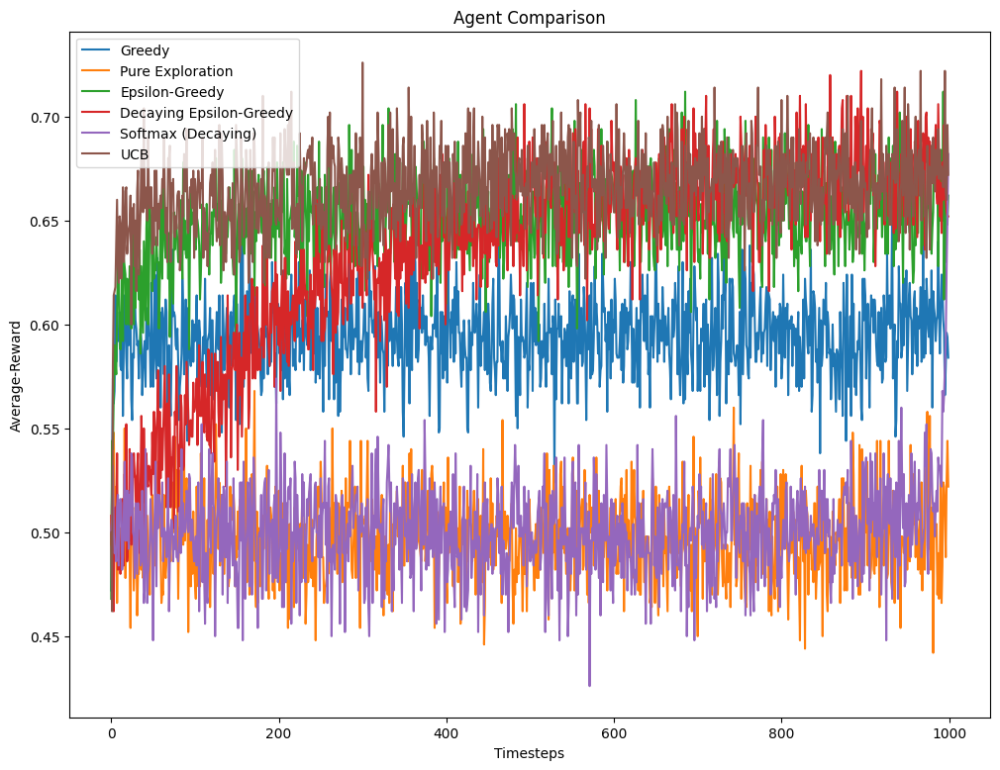

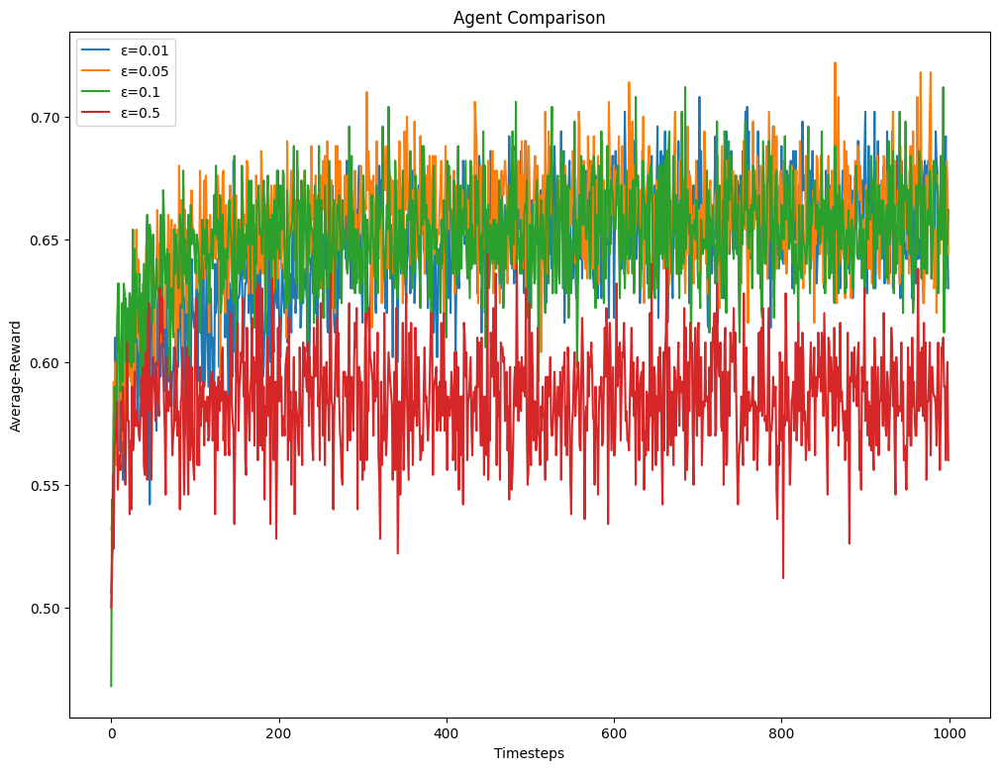

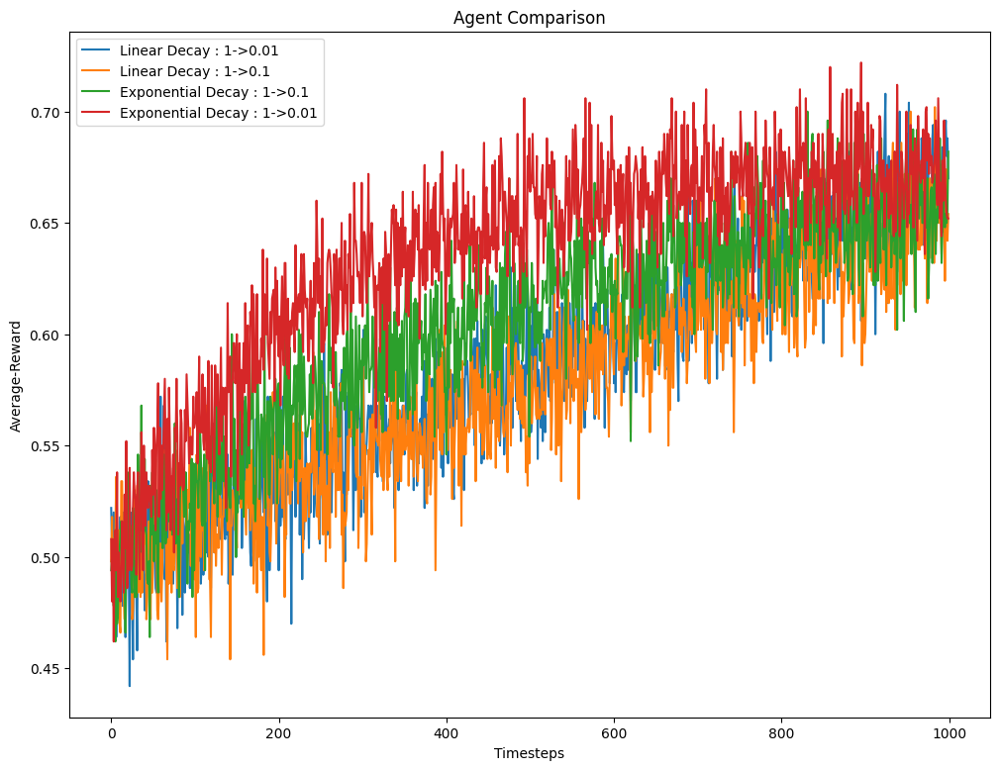

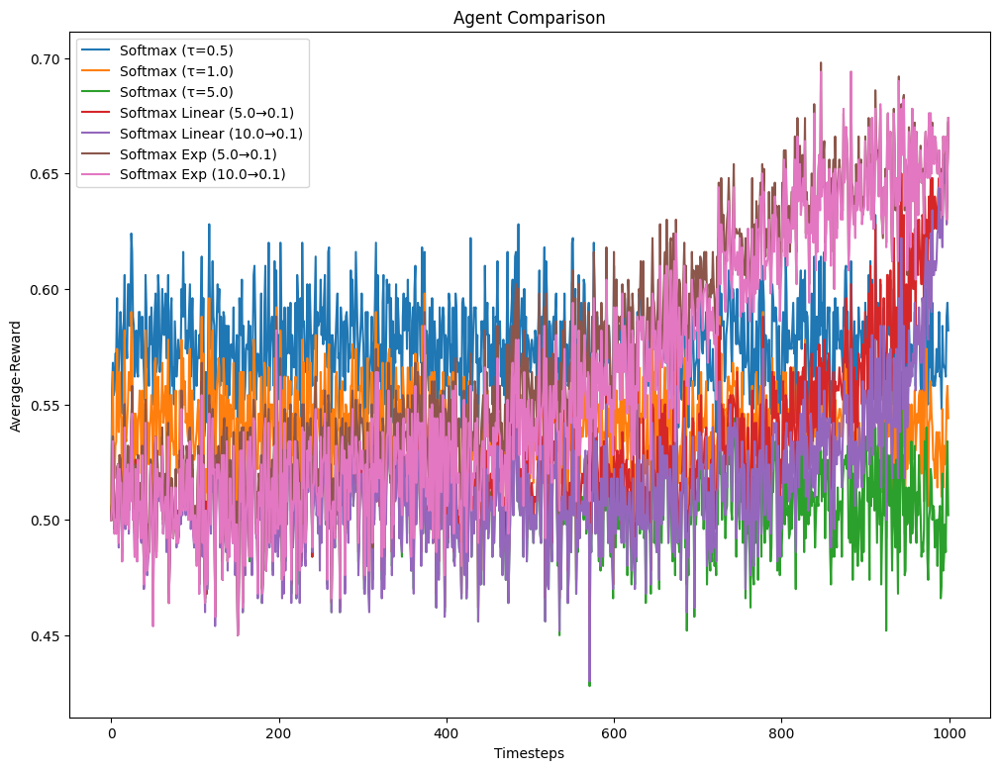

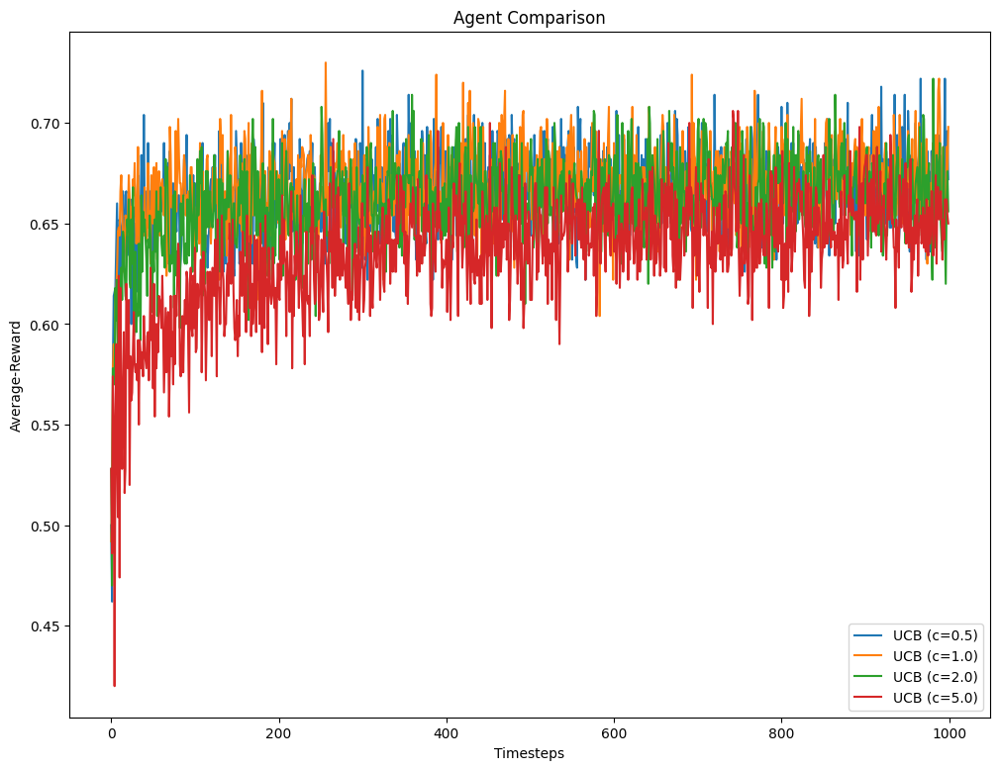

In [24]:

agents_to_test = [
    {
        "name": "Greedy",
        "func": pure_exploitation,
        "params": {}
    },
    {
        "name": "Pure Exploration",
        "func": pure_exploration,
        "params": {}
    },
    {
        "name": "Epsilon-Greedy",
        "func": epsilon_greedy,
        "params": {"epsilon": 0.1}
    },
    {
        "name": "Decaying Epsilon-Greedy",
        "func": decaying_epsilon_greedy,
        "params": {"epsilon_start": 1.0, "epsilon_end": 0.01, "decay_type": "exponential"}
    },
    {
        "name": "Softmax (Decaying)",
        "func": softmax,
        "params": {"temp_start": 100, "temp_end": 0.01, "decay_type": "linear"}
    },
    {
        "name": "UCB",
        "func": ucb_strategy,
        "params": {"c": 0.5}
    }
]

np.random.seed(SEED)
results ={}
for agent in agents_to_test:
    np.random.seed(SEED)
    avg_rewards = run_experiment_bernoulli(agent['func'], agent['params'], num_envs =500)
    results[agent['name']] = avg_rewards

plot_agent_comparison(results, 'experiment1-across-strategies')


agents_epsilon = [
    {"name": "ε=0.01", "func": epsilon_greedy, "params": {"epsilon": 0.01}},
    {"name": "ε=0.05", "func": epsilon_greedy, "params": {"epsilon": 0.05}},
    {"name": "ε=0.1", "func": epsilon_greedy, "params": {"epsilon": 0.1}},
    {"name": "ε=0.5", "func": epsilon_greedy, "params": {"epsilon": 0.5}},
]
results ={}
for agent in agents_epsilon:
    np.random.seed(SEED)
    avg_rewards = run_experiment_bernoulli(agent['func'], agent['params'], num_envs =500)
    results[agent['name']] = avg_rewards

plot_agent_comparison(results, 'experiment2-across-epsilon-values')

agents_decay_epsilon = [
    {"name": "Linear Decay : 1->0.01", "func": decaying_epsilon_greedy,
     "params": {"epsilon_start": 1.0, "epsilon_end": 0.01, "decay_type": "linear"}},
    {"name": "Linear Decay : 1->0.1", "func": decaying_epsilon_greedy,
     "params": {"epsilon_start": 1.0, "epsilon_end": 0.1, "decay_type": "linear"}},
    {"name": "Exponential Decay : 1->0.1", "func": decaying_epsilon_greedy,
     "params": {"epsilon_start": 1.0, "epsilon_end": 0.1, "decay_type": "exponential"}},
    {"name": "Exponential Decay : 1->0.01", "func": decaying_epsilon_greedy,
     "params": {"epsilon_start": 1.0, "epsilon_end": 0.01, "decay_type": "exponential"}},
]
results ={}
for agent in agents_decay_epsilon:
    np.random.seed(SEED)
    avg_rewards = run_experiment_bernoulli(agent['func'], agent['params'], num_envs =500)
    results[agent['name']] = avg_rewards

plot_agent_comparison(results, 'experiment3-decay-epsilon')

agents_softmax = [
    {"name": "Softmax (τ=0.5)", "func": softmax,
     "params": {"temp_start": 0.5, "temp_end": 0.5, "decay_type": "linear"}},
    {"name": "Softmax (τ=1.0)", "func": softmax,
     "params": {"temp_start": 1.0, "temp_end": 1.0, "decay_type": "linear"}},
    {"name": "Softmax (τ=5.0)", "func": softmax,
     "params": {"temp_start": 5.0, "temp_end": 5.0, "decay_type": "linear"}},
    {"name": "Softmax Linear (5.0→0.1)", "func": softmax,
     "params": {"temp_start": 5.0, "temp_end": 0.1, "decay_type": "linear"}},
    {"name": "Softmax Linear (10.0→0.1)", "func": softmax,
     "params": {"temp_start": 10.0, "temp_end": 0.1, "decay_type": "linear"}},
    {"name": "Softmax Exp (5.0→0.1)", "func": softmax,
     "params": {"temp_start": 5.0, "temp_end": 0.1, "decay_type": "exponential"}},
    {"name": "Softmax Exp (10.0→0.1)", "func": softmax,
     "params": {"temp_start": 10.0, "temp_end": 0.1, "decay_type": "exponential"}},
]
results ={}
for agent in agents_softmax:
    np.random.seed(SEED)
    avg_rewards = run_experiment_bernoulli(agent['func'], agent['params'], num_envs =500)
    results[agent['name']] = avg_rewards

plot_agent_comparison(results, 'experiment4-softmax')

agents_ucb = [
    {"name": "UCB (c=0.5)", "func": ucb_strategy, "params": {"c": 0.5}},
    {"name": "UCB (c=1.0)", "func": ucb_strategy, "params": {"c": 1.0}},
    {"name": "UCB (c=2.0)", "func": ucb_strategy, "params": {"c": 2.0}},
    {"name": "UCB (c=5.0)", "func": ucb_strategy, "params": {"c": 5.0}},
]
results ={}
for agent in agents_ucb:
    np.random.seed(SEED)
    avg_rewards = run_experiment_bernoulli(agent['func'], agent['params'], num_envs =500)
    results[agent['name']] = avg_rewards

plot_agent_comparison(results, 'experiment5-ucb')


**Observations:**

Added a `filename` parameter to `plot_agent_comparison()` to save multiple experiment plots with unique names.

---

## Experiment 1: Comparing Different Strategies

**Setup:** Tested six strategies (Greedy, Pure Exploration, ε-Greedy, Decaying ε-Greedy, Softmax, UCB) across 500 environments over 1000 timesteps.

**Observations:**
- Pure Exploration performs worst - randomly choosing arms ignores everything learned
- Greedy gets stuck early, performing poorly despite no exploration cost
- Fixed ε-Greedy (0.1) demonstrates strong performance by incorporating exploaration. 
- Decaying ε-Greedy improves by reducing exploration over time
- UCB demonstrates strong performance.
- Softmax with decay (100→0.01) shows an interesting pattern: maintains high exploration for most of the run due to high initial temperature, then rapidly exploits learned knowledge in the final phase when temperature becomes low

**Takeaway:** Balancing exploration and exploitation (UCB, decaying policies) beats pure approaches. Softmax's behavior is heavily influenced by its temperature schedule - very high initial temperatures delay exploitation.

---

## Experiment 2: Effect of Epsilon Values

**Setup:** Tested ε-greedy with ε ∈ {0.01, 0.05, 0.1, 0.5} to understand the exploration-exploitation tradeoff.

**Observations:**
- ε=0.5 performs worst - half of all pulls wasted on random exploration
- ε=0.1 shows decent performance
- ε=0.05 demonstrates better balance
- ε=0.01 performs best - exploits learned knowledge 99% of the time while maintaining minimal exploration

**Takeaway:** Lower epsilon values lead to better performance in this setting.

---

## Experiment 3: Decaying Epsilon Strategies

**Setup:** Compared linear and exponential decay (both 1.0→0.01 and 1.0→0.1) to see which decay pattern works best.

**Observations:**
- All strategies start with lower performance due to initial random exploration (ε=1.0)
- Exponential decay to 0.01 converges fastest and reaches highest performance
- Strategies ending at ε=0.1 plateau lower
- Exponential decay outperforms linear decay when both have same starting and eneding epsilon values. 

**Takeaway:** Exponential decay with low final epsilon gives the best results - explore aggressively early, then commit strongly to learned estimates.

---

## Experiment 4: Softmax Temperature Values

**Setup:** Tested constant temperatures (τ=0.5, 1.0, 5.0) and decaying strategies (linear/exponential: 5.0→0.1, 10.0→0.1).

**Observations:**
- High constant temperature (τ=5.0) performs poorly - action selection is nearly uniform
- Medium temperature (τ=1.0) shows moderate performance
- Low temperature (τ=0.5) demonstrates stronger exploitation
- All decaying strategies converge to similar final performance
- Starting temperature (5.0 vs 10.0) has minimal impact on outcomes
- Linear vs exponential decay show similar results

**Takeaway:** Temperature decay is essential for good performance. Constant high temperatures waste learning, while constant low temperatures risk premature convergence. Must ensure temperature decreases to enable exploitation.

---

## Experiment 5: UCB Exploration Parameter

**Setup:** Tested UCB with c ∈ {0.5, 1.0, 2.0, 5.0} to see how exploration bonus affects performance.

**Observations:**
- All UCB variants perform well, showing the algorithm is robust
- c=0.5 achieves best performance
- c=1.0 matches it
- c=2.0 shows slightly more exploration with marginally lower performance
- c=5.0 over-explores, reducing overall effectiveness

**Takeaway:** UCB works well across parameter ranges, but lower values (0.5-1.0) are optimal for this problem.



### 5. 10-armed bandit testbed (20 points)
Repeat the same thing as above for 10-armed Gaussian Bandit.

In [25]:
def run_experiment_gaussian(agent_func, agent_params,
                                       num_envs=50, steps=1000, sigma=1.0):
    """
    Runs an agent on multiple 10-armed Gaussian bandit environments and
    returns the average reward per time step.

    Args:
        agent_func: Agent function from Question 3.
        agent_params: Dictionary of agent hyperparameters.
        num_envs: Number of environments.
        steps: Number of steps per environment.
        sigma: Reward noise standard deviation.

    Returns:
        avg_rewards: Array of average rewards (length = steps).

    NOTE: increase the num_envs to get the much smoother curve. maybe 500 or 1000
    """
    np.random.seed(SEED)
    cum_rewards = np.zeros(steps)
    for i in range(num_envs):
        env = TenArmedGaussianBandit(sigma=sigma)
        env.reset(seed=SEED)
        rewards = agent_func(env=env, max_steps=steps, **agent_params)[1]
        cum_rewards += rewards

    return cum_rewards/num_envs


In [26]:
def plot_agent_comparison(results_dict, filename = 'file'):
    """
    same as Q4
    Plots average reward vs time step for multiple agents. (in single graph)

    Args:
        results_dict: Dictionary mapping agent name -> avg reward array.
    """
    plt.figure(figsize=(12,9))
    for agent_name, avg_rewards in results_dict.items():
        plt.plot(avg_rewards, label=agent_name)
    plt.xlabel('Timesteps')
    plt.ylabel('Average-Reward')
    plt.title('Agent Comparison')
    plt.legend()
    plt.savefig(f"{filename}.svg", dpi=300, bbox_inches='tight')
    plt.show()





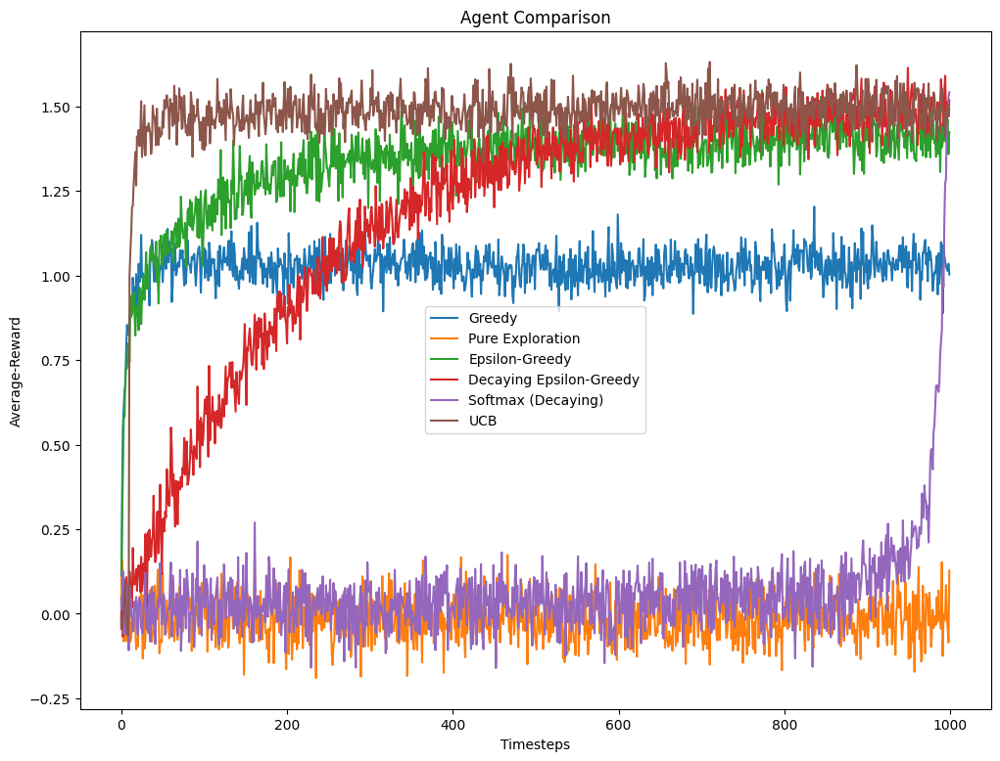

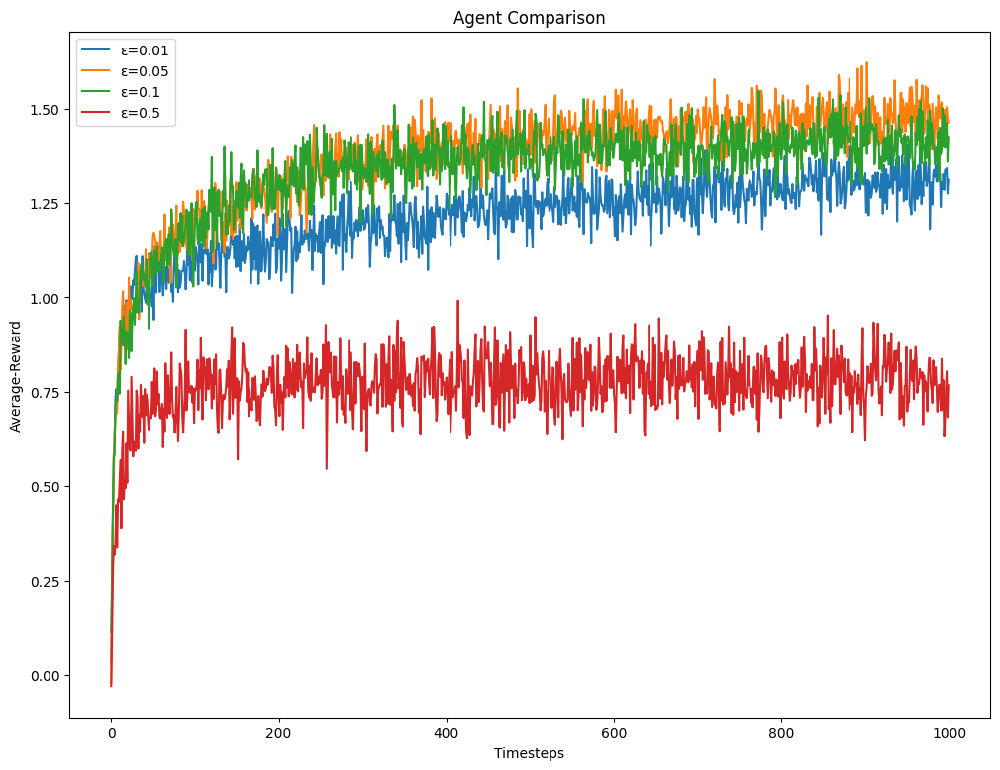

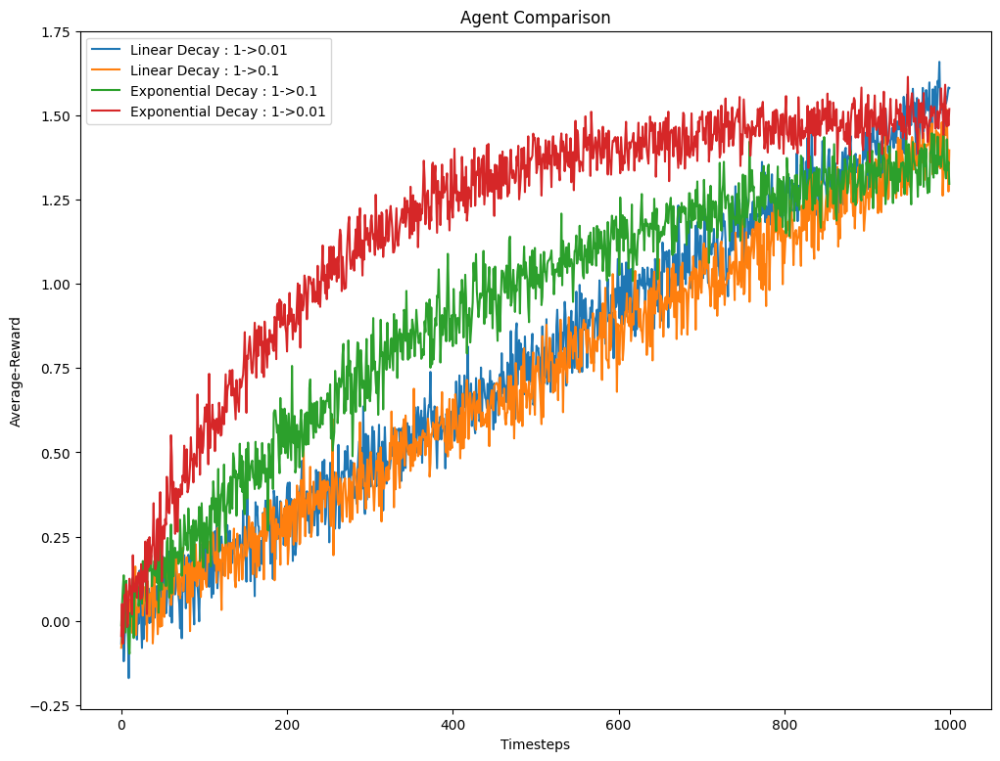

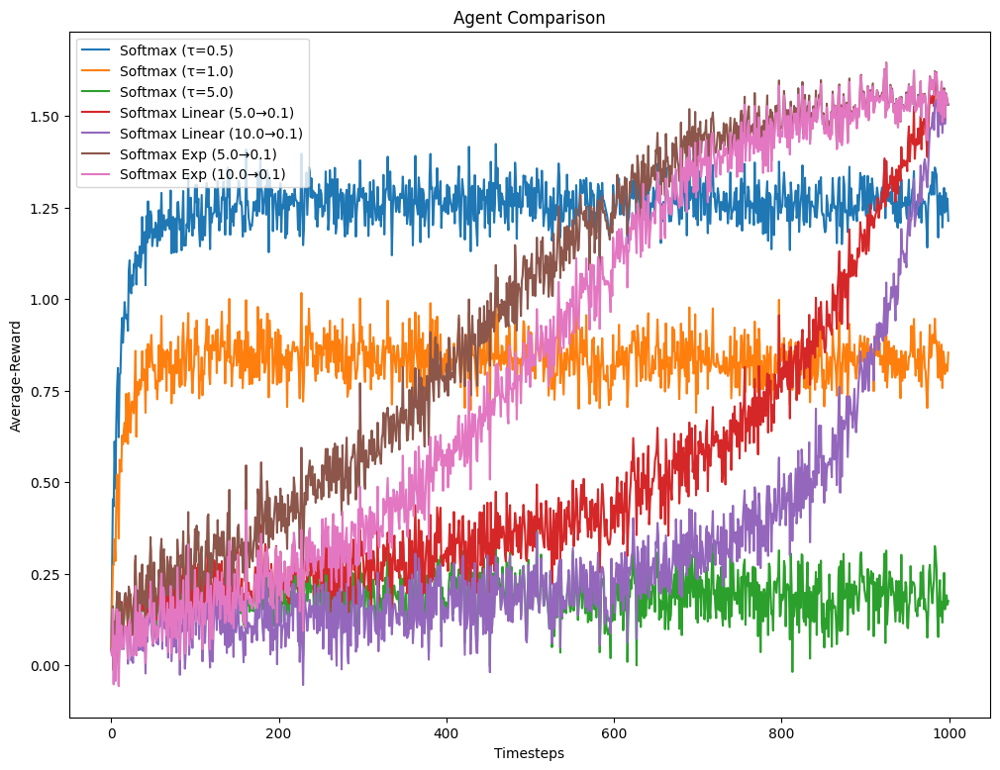

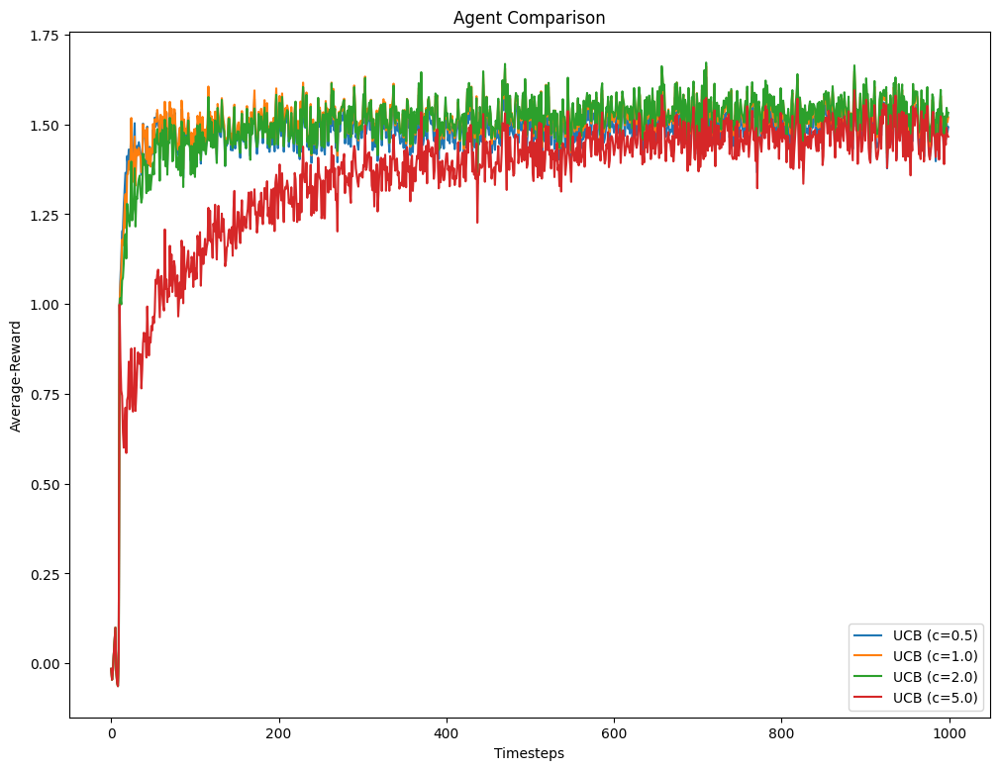

In [27]:
agents_to_test = [
   {
       "name": "Greedy",
       "func": pure_exploitation,
       "params": {}
   },
   {
       "name": "Pure Exploration",
       "func": pure_exploration,
       "params": {}
   },
   {
       "name": "Epsilon-Greedy",
       "func": epsilon_greedy,
       "params": {"epsilon": 0.1}
   },
   {
       "name": "Decaying Epsilon-Greedy",
       "func": decaying_epsilon_greedy,
       "params": {"epsilon_start": 1.0, "epsilon_end": 0.01, "decay_type": "exponential"}
   },
   {
       "name": "Softmax (Decaying)",
       "func": softmax,
       "params": {"temp_start": 100, "temp_end": 0.01, "decay_type": "linear"}
   },
   {
       "name": "UCB",
       "func": ucb_strategy,
       "params": {"c": 0.5}
   }
]


np.random.seed(SEED)
results ={}
for agent in agents_to_test:
   np.random.seed(SEED)
   avg_rewards = run_experiment_gaussian(agent['func'], agent['params'], num_envs =500)
   results[agent['name']] = avg_rewards


plot_agent_comparison(results, 'experiment1-gaussian-across-strategies')





agents_epsilon = [
   {"name": "ε=0.01", "func": epsilon_greedy, "params": {"epsilon": 0.01}},
   {"name": "ε=0.05", "func": epsilon_greedy, "params": {"epsilon": 0.05}},
   {"name": "ε=0.1", "func": epsilon_greedy, "params": {"epsilon": 0.1}},
   {"name": "ε=0.5", "func": epsilon_greedy, "params": {"epsilon": 0.5}},
]
results ={}
for agent in agents_epsilon:
   np.random.seed(SEED)
   avg_rewards = run_experiment_gaussian(agent['func'], agent['params'], num_envs =500)
   results[agent['name']] = avg_rewards


plot_agent_comparison(results, 'experiment2-gaussian-across-epsilon-values')


agents_decay_epsilon = [
   {"name": "Linear Decay : 1->0.01", "func": decaying_epsilon_greedy,
    "params": {"epsilon_start": 1.0, "epsilon_end": 0.01, "decay_type": "linear"}},
   {"name": "Linear Decay : 1->0.1", "func": decaying_epsilon_greedy,
    "params": {"epsilon_start": 1.0, "epsilon_end": 0.1, "decay_type": "linear"}},
   {"name": "Exponential Decay : 1->0.1", "func": decaying_epsilon_greedy,
    "params": {"epsilon_start": 1.0, "epsilon_end": 0.1, "decay_type": "exponential"}},
   {"name": "Exponential Decay : 1->0.01", "func": decaying_epsilon_greedy,
    "params": {"epsilon_start": 1.0, "epsilon_end": 0.01, "decay_type": "exponential"}},
]
results ={}
for agent in agents_decay_epsilon:
   np.random.seed(SEED)
   avg_rewards = run_experiment_gaussian(agent['func'], agent['params'], num_envs =500)
   results[agent['name']] = avg_rewards


plot_agent_comparison(results, 'experiment3-gaussian-decay-epsilon')
agents_softmax = [
   {"name": "Softmax (τ=0.5)", "func": softmax,
    "params": {"temp_start": 0.5, "temp_end": 0.5, "decay_type": "linear"}},
   {"name": "Softmax (τ=1.0)", "func": softmax,
    "params": {"temp_start": 1.0, "temp_end": 1.0, "decay_type": "linear"}},
   {"name": "Softmax (τ=5.0)", "func": softmax,
    "params": {"temp_start": 5.0, "temp_end": 5.0, "decay_type": "linear"}},
   {"name": "Softmax Linear (5.0→0.1)", "func": softmax,
    "params": {"temp_start": 5.0, "temp_end": 0.1, "decay_type": "linear"}},
   {"name": "Softmax Linear (10.0→0.1)", "func": softmax,
    "params": {"temp_start": 10.0, "temp_end": 0.1, "decay_type": "linear"}},
   {"name": "Softmax Exp (5.0→0.1)", "func": softmax,
    "params": {"temp_start": 5.0, "temp_end": 0.1, "decay_type": "exponential"}},
   {"name": "Softmax Exp (10.0→0.1)", "func": softmax,
    "params": {"temp_start": 10.0, "temp_end": 0.1, "decay_type": "exponential"}},
]
results ={}
for agent in agents_softmax:
   np.random.seed(SEED)
   avg_rewards = run_experiment_gaussian(agent['func'], agent['params'], num_envs =500)
   results[agent['name']] = avg_rewards


plot_agent_comparison(results, 'experiment4-gaussian-softmax')
agents_ucb = [
   {"name": "UCB (c=0.5)", "func": ucb_strategy, "params": {"c": 0.5}},
   {"name": "UCB (c=1.0)", "func": ucb_strategy, "params": {"c": 1.0}},
   {"name": "UCB (c=2.0)", "func": ucb_strategy, "params": {"c": 2.0}},
   {"name": "UCB (c=5.0)", "func": ucb_strategy, "params": {"c": 5.0}},
]
results ={}
for agent in agents_ucb:
   np.random.seed(SEED)
   avg_rewards = run_experiment_gaussian(agent['func'], agent['params'], num_envs =500)
   results[agent['name']] = avg_rewards


plot_agent_comparison(results, 'experiment5-gaussian-ucb')


**Observations:**


## Experiment 1: Comparing Different Strategies

**Setup:** Tested six strategies to compare fundamental exploration approaches.

**Observations:**
- Pure Exploration converges near zero (expected when randomly picking from 10 arms with mean 0)
- Greedy improves quickly but gets stuck on suboptimal arms
- Fixed ε-Greedy (0.1) steadily improves, beating greedy through continued exploration
- Decaying ε-Greedy shows smooth, strong convergence
- UCB achieves highest performance with systematic exploration
- Softmax (100→0.01) maintains high exploration until the final phase

**vs Bernoulli:** With 10 arms instead of 2, poor exploration hurts much more. UCB's advantage is clearer, and greedy fails as getting stuck early is costlier when there are more arms to choose from.

---

## Experiment 2: Effect of Epsilon Values

**Setup:** Tested ε-greedy with ε ∈ {0.01, 0.05, 0.1, 0.5}.

**Observations:**
- ε=0.5 performs poorly
- ε=0.1 shows improved performance
- ε=0.05 matches the performance for ε=0.1 
- ε=0.01 performs best

**vs Bernoulli:** Performance gaps are larger. Random exploration is less efficient with 10 arms as each random pull has only 10% chance of hitting the best arm vs 50% with 2 arms.

---

## Experiment 3: Decaying Epsilon Strategies

**Setup:** Compared linear and exponential decay (1.0→0.01 and 1.0→0.1).

**Observations:**
- All start low due to ε=1.0 initial exploration
- Strategies converge to the same performance level
- Exponential decay shows steeper improvement in the middle phase

**vs Bernoulli:** The convergence pattern is similar, but the speed advantage of exponential decay is more visible with 10 arms.

---

## Experiment 4: Softmax Temperature Values

**Setup:** Tested constant temperatures (τ=0.5, 1.0, 5.0) and decaying strategies (5.0→0.1, 10.0→0.1).

**Observations:**
- High constant τ=5.0 performs poorly
- Medium τ=1.0 is moderate
- Low τ=0.5 shows better exploitation
- All decaying strategies converge approximately to the same point, exponential being faster

**vs Bernoulli:** Constant high temperatures hurt more with 10 arms. Temperature decay becomes more essential—staying exploratory is costlier when there are more suboptimal arms to waste pulls on.

---

## Experiment 5: UCB Exploration Parameter

**Setup:** Tested UCB with c ∈ {0.5, 1.0, 2.0, 5.0}.

**Observations:**
- All variants perform well
- c=5.0 explores more initially but still maintains good performance

**vs Bernoulli:** Optimal c value is higher than in bernoulli case as with 10 arms, more exploration is beneficial due to higher uncertainty. Even c=5.0 doesn't hurt as much.


### 6. 2-armed Regret (20 points)
In the lecture we defined *Regret* as $\sum_{e=1}^{E} \mathbb{E}[v_* - q_*(A_e)]$, i.e. episode wise sum of the expected value of the difference between optimal action value ($v_*$) and true value ($q_*$) of taking an action $A_e$. For the 2-armed Bernoulli Bandit plot the regret vs episodes for each of the agent. Use the same setting of 50 environment instances as in the previous part. What do you observe? How do regrets evolve for different methods? Describe your observations in details.



In [28]:
def run_regret_experiment_bernoulli(agent_func, agent_params,
                                    num_envs=50, steps=1000):
    """
    Runs a bandit agent on multiple 2-armed Bernoulli environments and
    computes the average cumulative regret.

    Args:
        agent_func: Agent function (from Question 3).
        agent_params: Dictionary of agent hyperparameters.
        num_envs: Number of environments to average over.
        steps: Number of episodes per environment.

    Returns:
        avg_cumulative_regret: Cumulative expected regret (length = steps).
    """
    np.random.seed(SEED)
    alphas = np.random.uniform(low = 0, high = 1, size=num_envs)
    betas = np.random.uniform(low = 0, high = 1, size=num_envs)
    opt_v = np.maximum(alphas,betas)
    cum_regret = np.zeros(steps)
    for i in range(num_envs):
          env = TwoArmedBernoulliBandit(alphas[i],betas[i])
          env.reset(seed=SEED)
          actions = agent_func(env=env, max_steps=steps, **agent_params)[0]
          q_star = np.array([alphas[i] if action == 0 else betas[i] for action in actions])
          cum_regret += np.cumsum(opt_v[i] - q_star)

    return cum_regret/num_envs



In [29]:
def plot_regret_comparison(results_dict, filename='file-regret'):
    """
    Plots cumulative regret vs episodes for multiple agents.

    Args:
        results_dict: Mapping agent name -> cumulative regret array.
    """
    plt.figure(figsize=(12,9))
    for agent_name, avg_regret in results_dict.items():
        plt.plot(avg_regret, label=agent_name)
    plt.xlabel('Timesteps')
    plt.ylabel('Average-Regret')
    plt.title('Agent Comparison')
    plt.legend()
    plt.savefig(f"{filename}.svg", dpi=300, bbox_inches='tight')
    plt.show()


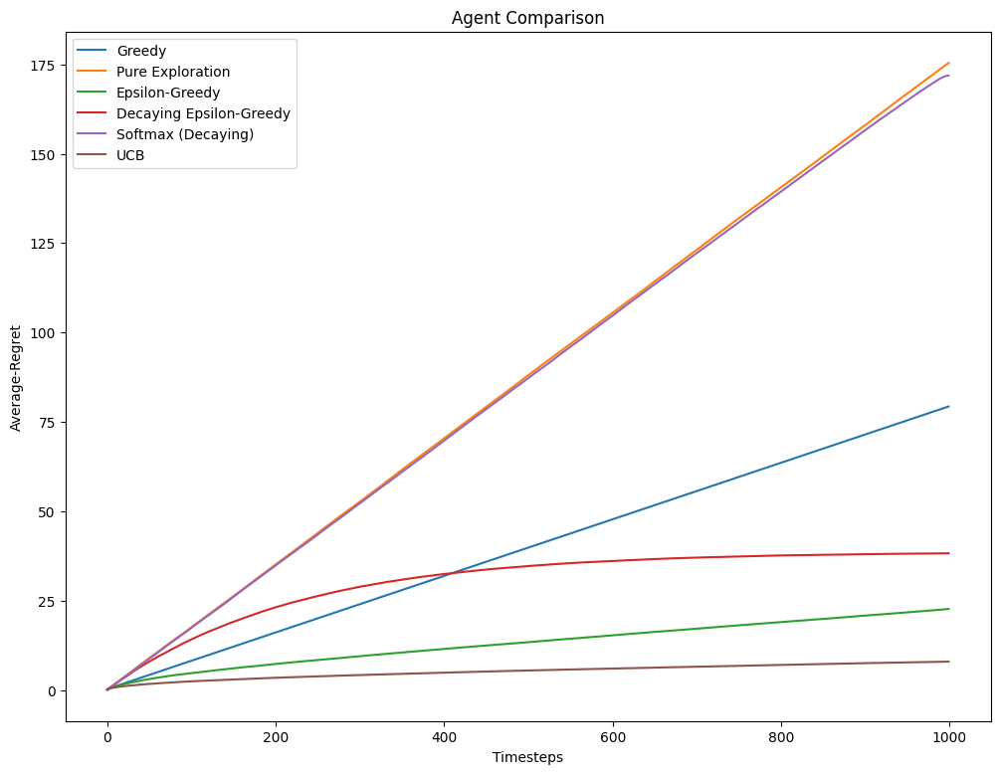

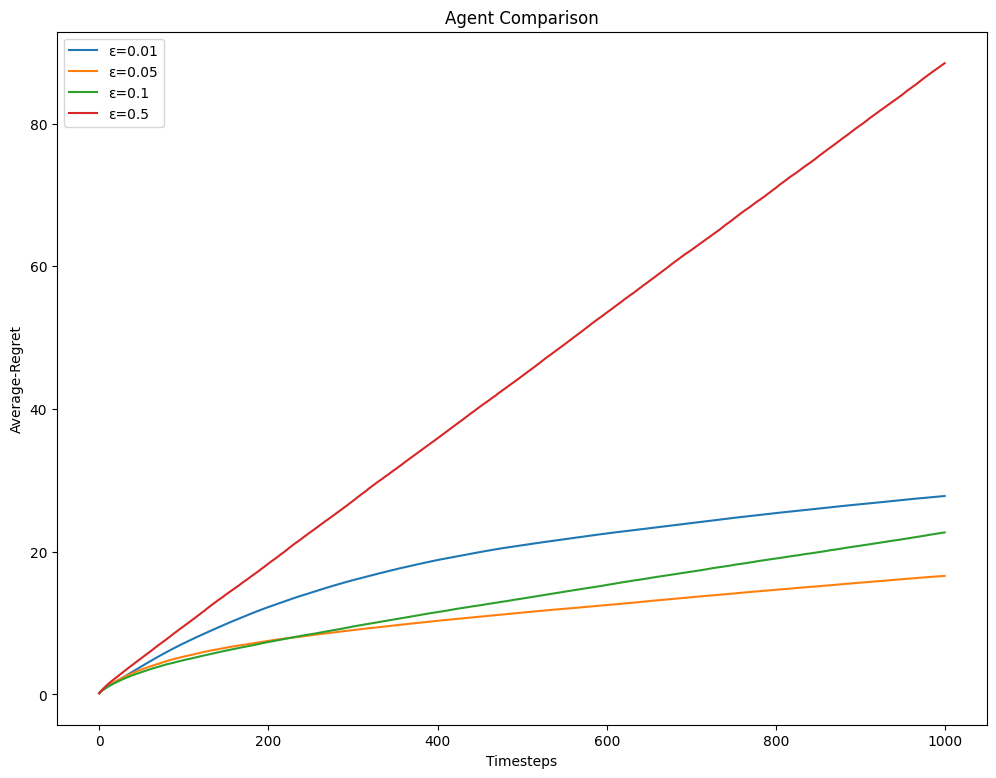

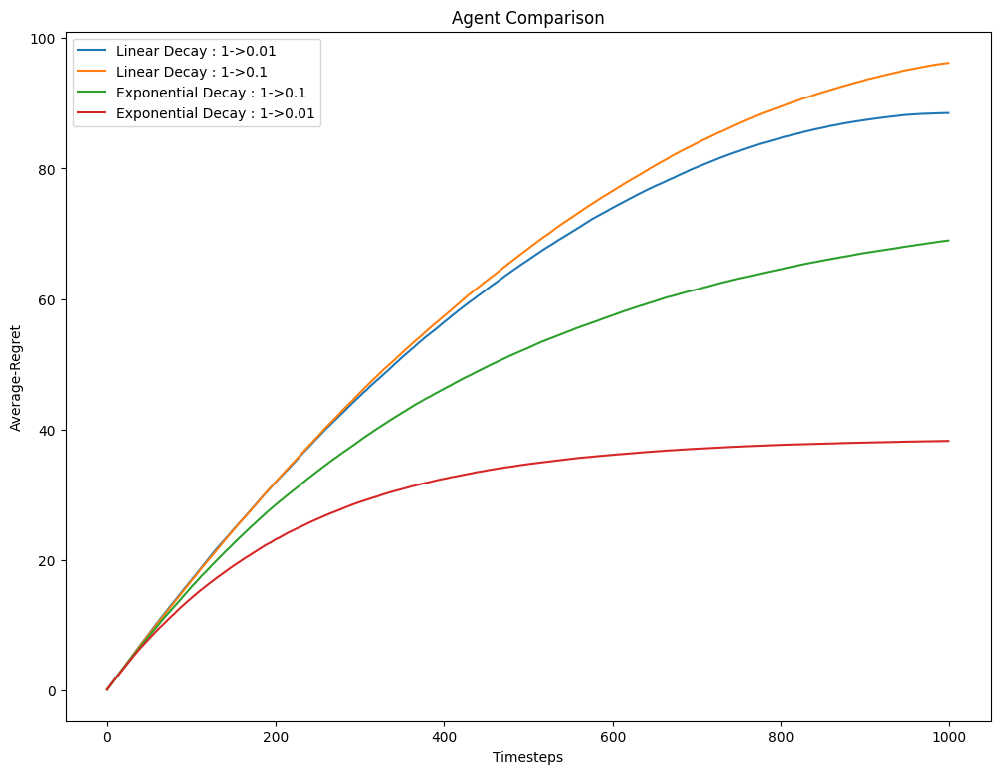

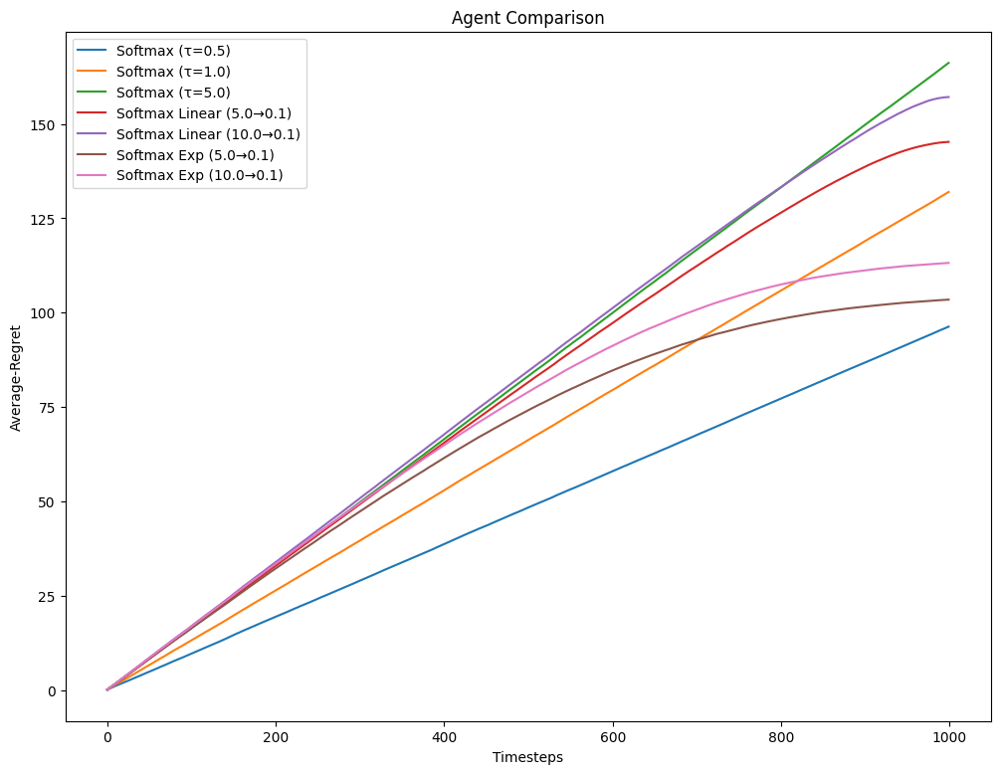

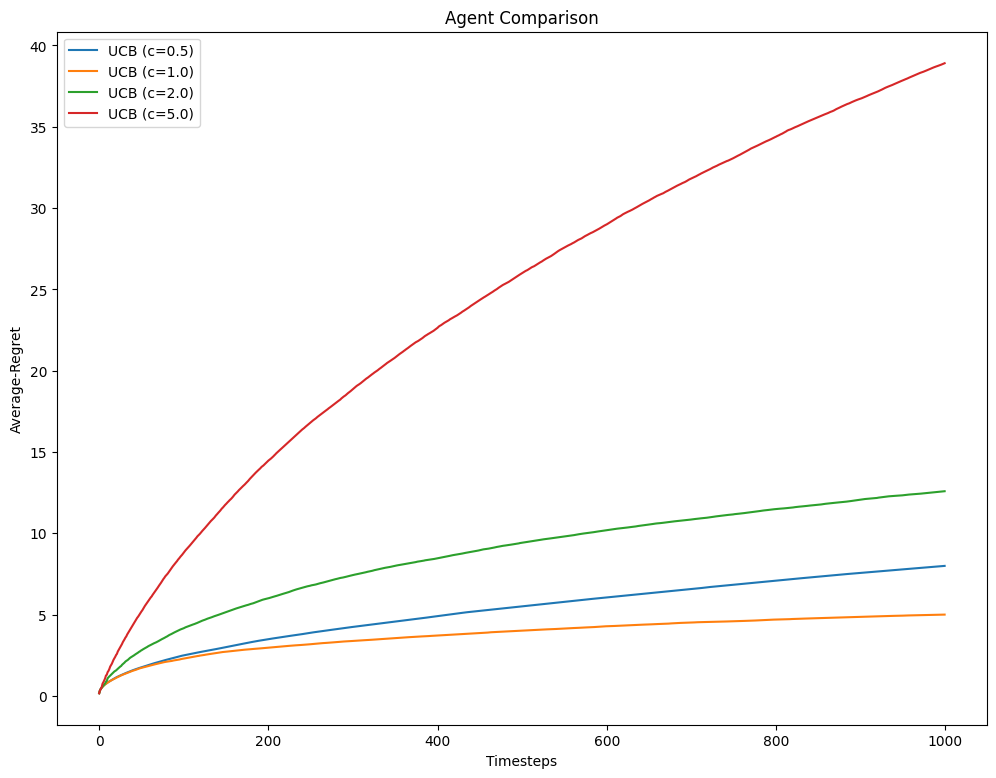

In [30]:
agents_to_test = [
  {
      "name": "Greedy",
      "func": pure_exploitation,
      "params": {}
  },
  {
      "name": "Pure Exploration",
      "func": pure_exploration,
      "params": {}
  },
  {
      "name": "Epsilon-Greedy",
      "func": epsilon_greedy,
      "params": {"epsilon": 0.1}
  },
  {
      "name": "Decaying Epsilon-Greedy",
      "func": decaying_epsilon_greedy,
      "params": {"epsilon_start": 1.0, "epsilon_end": 0.01, "decay_type": "exponential"}
  },
  {
      "name": "Softmax (Decaying)",
      "func": softmax,
      "params": {"temp_start": 100, "temp_end": 0.01, "decay_type": "linear"}
  },
  {
      "name": "UCB",
      "func": ucb_strategy,
      "params": {"c": 0.5}
  }
]

np.random.seed(SEED)
results ={}
for agent in agents_to_test:
  np.random.seed(SEED)
  avg_regret = run_regret_experiment_bernoulli(agent['func'], agent['params'], num_envs =500)
  results[agent['name']] = avg_regret




plot_regret_comparison(results, 'experiment1-regret-across-strategies')



agents_epsilon = [
  {"name": "ε=0.01", "func": epsilon_greedy, "params": {"epsilon": 0.01}},
  {"name": "ε=0.05", "func": epsilon_greedy, "params": {"epsilon": 0.05}},
  {"name": "ε=0.1", "func": epsilon_greedy, "params": {"epsilon": 0.1}},
  {"name": "ε=0.5", "func": epsilon_greedy, "params": {"epsilon": 0.5}},
]
results ={}
for agent in agents_epsilon:
  np.random.seed(SEED)
  avg_regret = run_regret_experiment_bernoulli(agent['func'], agent['params'], num_envs =500)
  results[agent['name']] = avg_regret




plot_regret_comparison(results, 'experiment2-regret-across-epsilon-values')




agents_decay_epsilon = [
  {"name": "Linear Decay : 1->0.01", "func": decaying_epsilon_greedy,
   "params": {"epsilon_start": 1.0, "epsilon_end": 0.01, "decay_type": "linear"}},
  {"name": "Linear Decay : 1->0.1", "func": decaying_epsilon_greedy,
   "params": {"epsilon_start": 1.0, "epsilon_end": 0.1, "decay_type": "linear"}},
  {"name": "Exponential Decay : 1->0.1", "func": decaying_epsilon_greedy,
   "params": {"epsilon_start": 1.0, "epsilon_end": 0.1, "decay_type": "exponential"}},
  {"name": "Exponential Decay : 1->0.01", "func": decaying_epsilon_greedy,
   "params": {"epsilon_start": 1.0, "epsilon_end": 0.01, "decay_type": "exponential"}},
]
results ={}
for agent in agents_decay_epsilon:
  np.random.seed(SEED)
  avg_regret = run_regret_experiment_bernoulli(agent['func'], agent['params'], num_envs =500)
  results[agent['name']] = avg_regret




plot_regret_comparison(results, 'experiment3-regret-decay-epsilon')
agents_softmax = [
  {"name": "Softmax (τ=0.5)", "func": softmax,
   "params": {"temp_start": 0.5, "temp_end": 0.5, "decay_type": "linear"}},
  {"name": "Softmax (τ=1.0)", "func": softmax,
   "params": {"temp_start": 1.0, "temp_end": 1.0, "decay_type": "linear"}},
  {"name": "Softmax (τ=5.0)", "func": softmax,
   "params": {"temp_start": 5.0, "temp_end": 5.0, "decay_type": "linear"}},
  {"name": "Softmax Linear (5.0→0.1)", "func": softmax,
   "params": {"temp_start": 5.0, "temp_end": 0.1, "decay_type": "linear"}},
  {"name": "Softmax Linear (10.0→0.1)", "func": softmax,
   "params": {"temp_start": 10.0, "temp_end": 0.1, "decay_type": "linear"}},
  {"name": "Softmax Exp (5.0→0.1)", "func": softmax,
   "params": {"temp_start": 5.0, "temp_end": 0.1, "decay_type": "exponential"}},
  {"name": "Softmax Exp (10.0→0.1)", "func": softmax,
   "params": {"temp_start": 10.0, "temp_end": 0.1, "decay_type": "exponential"}},
]
results ={}
for agent in agents_softmax:
  np.random.seed(SEED)
  avg_regret = run_regret_experiment_bernoulli(agent['func'], agent['params'], num_envs =500)
  results[agent['name']] = avg_regret




plot_regret_comparison(results, 'experiment4-regret-softmax')
agents_ucb = [
  {"name": "UCB (c=0.5)", "func": ucb_strategy, "params": {"c": 0.5}},
  {"name": "UCB (c=1.0)", "func": ucb_strategy, "params": {"c": 1.0}},
  {"name": "UCB (c=2.0)", "func": ucb_strategy, "params": {"c": 2.0}},
  {"name": "UCB (c=5.0)", "func": ucb_strategy, "params": {"c": 5.0}},
]
results ={}
for agent in agents_ucb:
  np.random.seed(SEED)
  avg_regret = run_regret_experiment_bernoulli(agent['func'], agent['params'], num_envs =500)
  results[agent['name']] = avg_regret




plot_regret_comparison(results, 'experiment5-regret-ucb')


**Observations:**


## Experiment 1: Regret Across Different Strategies
**Setup:** Tested different strategies to understand their effect on cumulative regret.

**Observations:**
- Pure Exploration accumulates highest regret—linear growth since it never exploits learned knowledge
- Greedy accumulates less regret as compared to Pure Exploration and has a linear growth as it favours one arm throughout
- Fixed ε-Greedy (0.1) shows steady linear regret growth—continuous 10% random exploration adds constant cost
- Decaying ε-Greedy shows sublinear regret growth(higher than Fixed ε-Greedy) as exploration cost is high initially
- UCB demonstrates best performance with lowest regret accumulation
- Softmax with decay shows regret comparable to pure exploration, this is attributed to temperature start = 100, leading to a high exploration. It is also observed that the regret starts to plateau(as temperature decreases at last)

**Takeaway:** Strategies that reduce exploration over time (decaying policies, UCB) achieve sublinear regret, while fixed exploration rates lead to linear regret growth.

---

## Experiment 2: Regret for Different Epsilon Values

**Setup:** Tested ε-greedy with ε ∈ {0.01, 0.05, 0.1, 0.5} to understand how exploration rate affects cumulative regret.

**Observations:**
- **ε=0.5** accumulates regret faster than all others—the steep red line, it can be inferred that cost of wasting half of the pulls on random exploration is wasteful.
- **ε=0.05 and ε=0.1** achieve the lowest regret growth. Their curves are nearly flat.
- **ε=0.01** surprisingly performs worse than ε=0.05 and ε=0.1, showing higher regret accumulation despite exploiting 99% of the time
- All strategies start similarly at zero, but diverge over time as their exploration strategies compound different mistakes

**Takeaway:** There's a sweet spot for epsilon—too high (0.5) wastes pulls on exploration, but too low (0.01) doesn't explore enough to find the truly optimal arm.

---

## Experiment 3: Regret for Decaying Epsilon

**Setup:** Compared linear and exponential decay (1.0→0.01 and 1.0→0.1) to see how decay type and final epsilon affect regret.

**Observations:**
- All strategies start together near zero with high initial exploration (ε=1.0)
- **Exponential decay to 0.01** achieves lowest final regret and flattest curve—it's clearly the best performer
- **Exponential decay to 0.1** shows moderate performance with steady growth
- **Linear decay strategies** perform worst, accumulating highest regret
- Linear decay to 0.01 and 0.1 are very similar to each other, both significantly worse than exponential
- All curves show sublinear growth—they start steep but flatten over time as exploration decreases
- The gap between exponential and linear decay is substantial, showing decay type matters significantly

**Takeaway:** Exponential decay dramatically outperforms linear decay for the same final epsilon. Exponential decay reduces exploration faster in the early-mid phase, which helps identify the optimal arm sooner while still exploring enough initially. Linear decay encourages exploration for a longer duration, accumulating unnecessary regret.

---

## Experiment 4: Regret for Softmax Temperature

**Setup:** Tested constant temperatures (τ=0.5, 1.0, 5.0) and decaying strategies (linear/exponential: 5.0→0.1, 10.0→0.1).

**Observations:**
- **τ=0.5** achieves lowest regret with nearly linear, slow growth—low temperature exploits well from the start
- **τ=1.0** shows moderate regret, starting to curve upward in the later phase
- **Exponential decay 10.0→0.1** performs best among decaying strategies with relatively flat growth
- **Exponential decay 5.0→0.1** shows similar performance, slightly higher regret
- **Linear decay strategies** perform worse than exponential, with steeper regret accumulation
- **τ=5.0** accumulates highest regret, showing  cost of high constant temperature
- All curves start together but diverge quickly based on their temperature schedules

**Takeaway:** Surprisingly, constant low temperature (τ=0.5) outperforms all decaying strategies in terms of regret. This suggests that for this 2-armed problem, exploiting from the start works better than extended exploration. Among decaying strategies, exponential decay performs better than linear.

---

## Experiment 5: Regret for UCB Parameter Values

**Setup:** Tested UCB with c ∈ {0.5, 1.0, 2.0, 5.0} to see how exploration bonus affects regret.

**Observations:**
- **c=1.0** achieves lowest regret with extremely flat growth, best overall performance
- **c=0.5** performs nearly as well
- **c=2.0** shows moderate regret accumulation
- **c=5.0** accumulates highest regret among all other c-values
- Lower c values (0.5, 1.0) have remarkably flat curves after the initial phase

**Takeaway:** UCB with c=1.0 achieves the lowest regret of any strategy tested across all experiments—even better than the best decaying ε-greedy. c=0.5 performs nearly as well.Higher c values over-explore: c=5.0's regret matches the worst performing softmax strategies. 

### 7. 10-armed Regret (20 points)

Repeat the same thing as above for 10-armed Gaussian Bandit.



In [31]:
def run_regret_experiment_gaussian(agent_func, agent_params,
                                   num_envs=50, steps=1000, sigma = 1.0):
    """
    Runs a bandit agent on multiple 10-armed Gaussian environments and
    computes the average cumulative regret.

    Args:
        agent_func: Agent function.
        agent_params: Dictionary of agent hyperparameters.
        num_envs: Number of environments to average over.
        steps: Number of episodes per environment.

    Returns:
        avg_cumulative_regret: Cumulative expected regret (length = steps).
    """
    np.random.seed(SEED)
    cum_regret = np.zeros(steps)
    for i in range(num_envs):
          env = TenArmedGaussianBandit(sigma=sigma)
          means = env.means
          env.reset(seed=SEED)
          actions = agent_func(env=env, max_steps=steps, **agent_params)[0]
          q_star = np.array([means[action] for action in actions])
          opt_v = np.max(means)
          cum_regret += np.cumsum(opt_v - q_star)

    return cum_regret/num_envs


In [32]:
def plot_regret_comparison(results_dict, filename='file-regret'):
    """
    same as q6
    Plots cumulative regret vs episodes for multiple agents.

    Args:
        results_dict: Mapping agent name -> cumulative regret array.
    """
    plt.figure(figsize=(12,9))
    for agent_name, avg_regret in results_dict.items():
        plt.plot(avg_regret, label=agent_name)
    plt.xlabel('Timesteps')
    plt.ylabel('Average-Regret')
    plt.title('Agent Comparison')
    plt.legend()
    plt.savefig(f"{filename}.svg", dpi=300, bbox_inches='tight')
    plt.show()

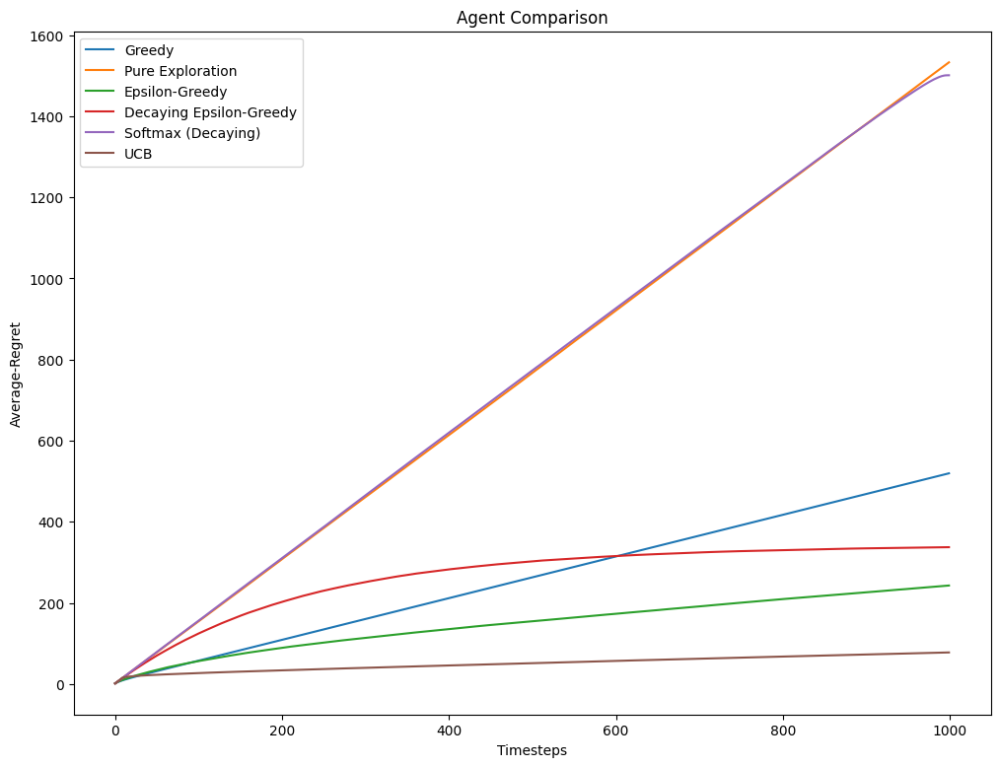

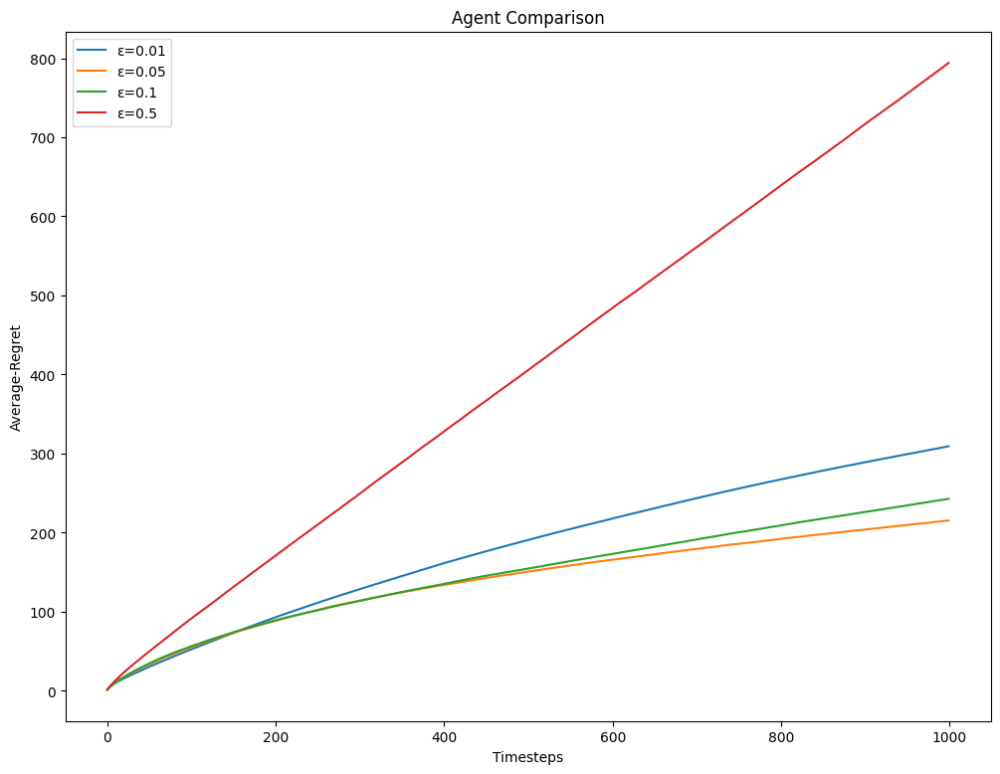

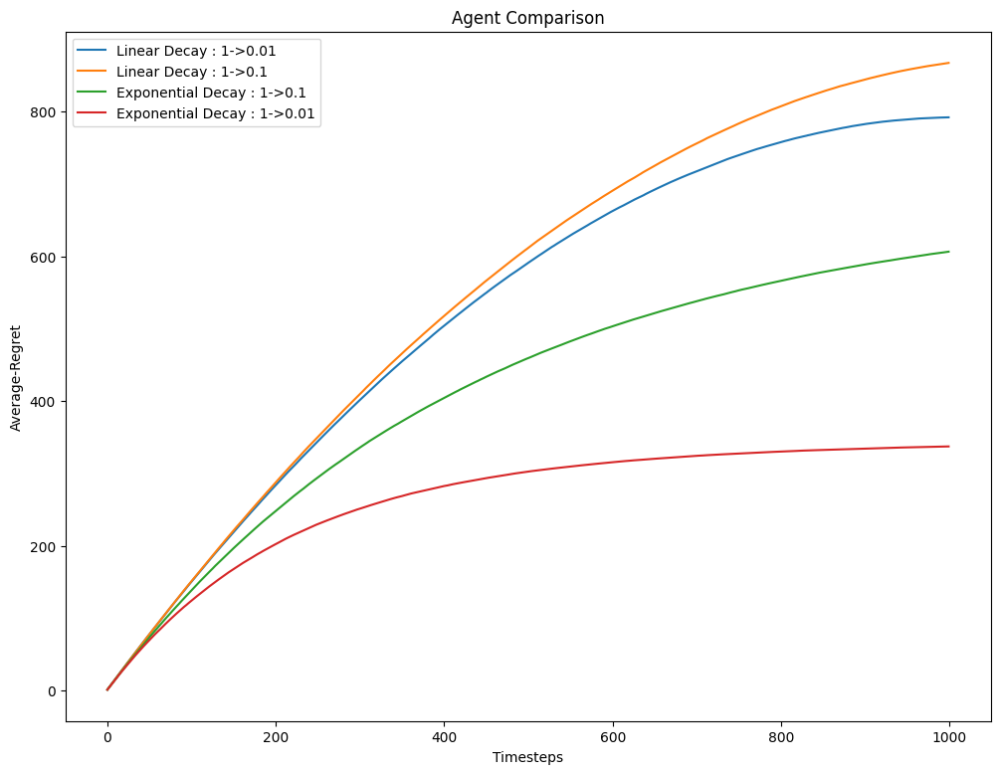

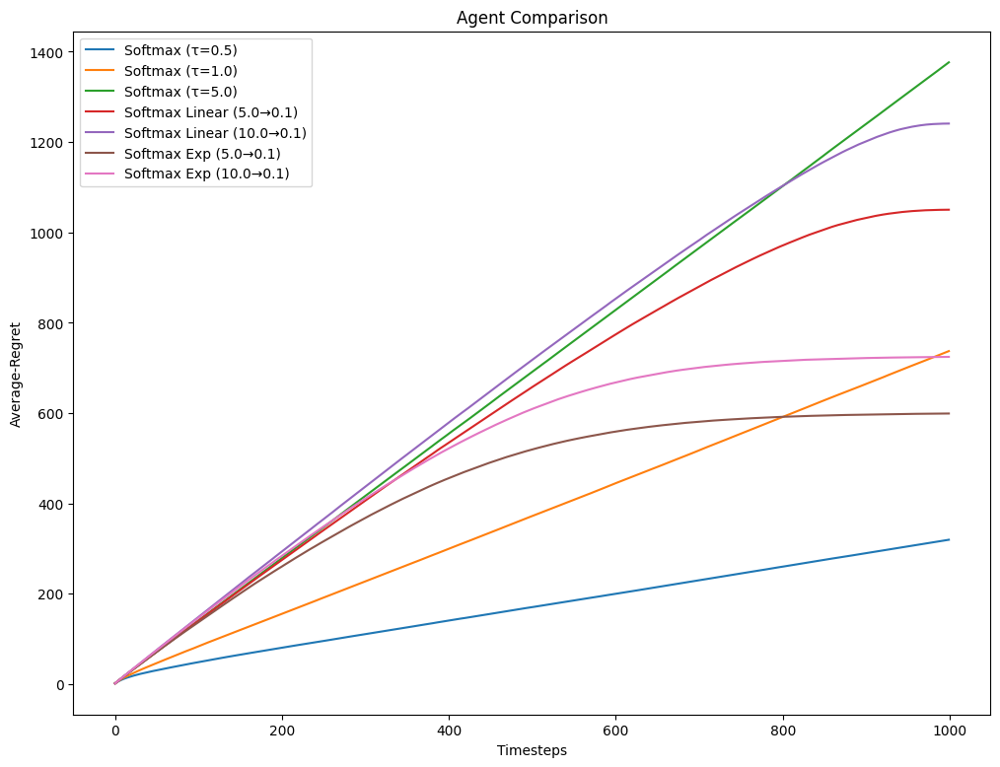

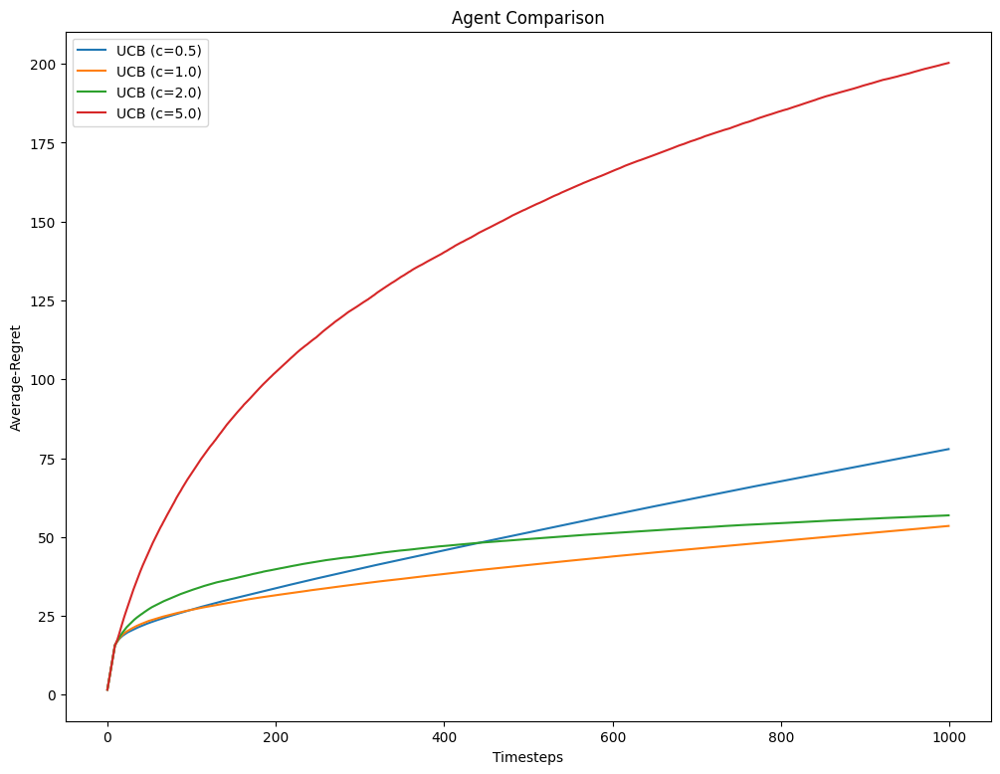

In [33]:
agents_to_test = [
  {
      "name": "Greedy",
      "func": pure_exploitation,
      "params": {}
  },
  {
      "name": "Pure Exploration",
      "func": pure_exploration,
      "params": {}
  },
  {
      "name": "Epsilon-Greedy",
      "func": epsilon_greedy,
      "params": {"epsilon": 0.1}
  },
  {
      "name": "Decaying Epsilon-Greedy",
      "func": decaying_epsilon_greedy,
      "params": {"epsilon_start": 1.0, "epsilon_end": 0.01, "decay_type": "exponential"}
  },
  {
      "name": "Softmax (Decaying)",
      "func": softmax,
      "params": {"temp_start": 100, "temp_end": 0.01, "decay_type": "linear"}
  },
  {
      "name": "UCB",
      "func": ucb_strategy,
      "params": {"c": 0.5}
  }
]

np.random.seed(SEED)
results ={}
for agent in agents_to_test:
  np.random.seed(SEED)
  avg_regret = run_regret_experiment_gaussian(agent['func'], agent['params'], num_envs =500)
  results[agent['name']] = avg_regret




plot_regret_comparison(results, 'experiment1-gaussian-regret-across-strategies')

agents_epsilon = [
  {"name": "ε=0.01", "func": epsilon_greedy, "params": {"epsilon": 0.01}},
  {"name": "ε=0.05", "func": epsilon_greedy, "params": {"epsilon": 0.05}},
  {"name": "ε=0.1", "func": epsilon_greedy, "params": {"epsilon": 0.1}},
  {"name": "ε=0.5", "func": epsilon_greedy, "params": {"epsilon": 0.5}},
]
results ={}
for agent in agents_epsilon:
  np.random.seed(SEED)
  avg_regret = run_regret_experiment_gaussian(agent['func'], agent['params'], num_envs =500)
  results[agent['name']] = avg_regret




plot_regret_comparison(results, 'experiment2-gaussian-regret-across-epsilon-values')




agents_decay_epsilon = [
  {"name": "Linear Decay : 1->0.01", "func": decaying_epsilon_greedy,
   "params": {"epsilon_start": 1.0, "epsilon_end": 0.01, "decay_type": "linear"}},
  {"name": "Linear Decay : 1->0.1", "func": decaying_epsilon_greedy,
   "params": {"epsilon_start": 1.0, "epsilon_end": 0.1, "decay_type": "linear"}},
  {"name": "Exponential Decay : 1->0.1", "func": decaying_epsilon_greedy,
   "params": {"epsilon_start": 1.0, "epsilon_end": 0.1, "decay_type": "exponential"}},
  {"name": "Exponential Decay : 1->0.01", "func": decaying_epsilon_greedy,
   "params": {"epsilon_start": 1.0, "epsilon_end": 0.01, "decay_type": "exponential"}},
]
results ={}
for agent in agents_decay_epsilon:
  np.random.seed(SEED)
  avg_regret = run_regret_experiment_gaussian(agent['func'], agent['params'], num_envs =500)
  results[agent['name']] = avg_regret




plot_regret_comparison(results, 'experiment3-gaussianregret-decay-epsilon')
agents_softmax = [
  {"name": "Softmax (τ=0.5)", "func": softmax,
   "params": {"temp_start": 0.5, "temp_end": 0.5, "decay_type": "linear"}},
  {"name": "Softmax (τ=1.0)", "func": softmax,
   "params": {"temp_start": 1.0, "temp_end": 1.0, "decay_type": "linear"}},
  {"name": "Softmax (τ=5.0)", "func": softmax,
   "params": {"temp_start": 5.0, "temp_end": 5.0, "decay_type": "linear"}},
  {"name": "Softmax Linear (5.0→0.1)", "func": softmax,
   "params": {"temp_start": 5.0, "temp_end": 0.1, "decay_type": "linear"}},
  {"name": "Softmax Linear (10.0→0.1)", "func": softmax,
   "params": {"temp_start": 10.0, "temp_end": 0.1, "decay_type": "linear"}},
  {"name": "Softmax Exp (5.0→0.1)", "func": softmax,
   "params": {"temp_start": 5.0, "temp_end": 0.1, "decay_type": "exponential"}},
  {"name": "Softmax Exp (10.0→0.1)", "func": softmax,
   "params": {"temp_start": 10.0, "temp_end": 0.1, "decay_type": "exponential"}},
]
results ={}
for agent in agents_softmax:
  np.random.seed(SEED)
  avg_regret = run_regret_experiment_gaussian(agent['func'], agent['params'], num_envs =500)
  results[agent['name']] = avg_regret




plot_regret_comparison(results, 'experiment4-gaussian-regret-softmax')
agents_ucb = [
  {"name": "UCB (c=0.5)", "func": ucb_strategy, "params": {"c": 0.5}},
  {"name": "UCB (c=1.0)", "func": ucb_strategy, "params": {"c": 1.0}},
  {"name": "UCB (c=2.0)", "func": ucb_strategy, "params": {"c": 2.0}},
  {"name": "UCB (c=5.0)", "func": ucb_strategy, "params": {"c": 5.0}},
]
results ={}
for agent in agents_ucb:
  np.random.seed(SEED)
  avg_regret = run_regret_experiment_gaussian(agent['func'], agent['params'], num_envs =500)
  results[agent['name']] = avg_regret




plot_regret_comparison(results, 'experiment5-gaussian-regret-ucb')

**Observations:**
## Experiment 1: Regret Across Different Strategies

**Setup:** Tested different strategies on 10-armed Gaussian bandits to understand their effect on cumulative regret.

**Observations:**
- **Pure Exploration and Softmax (decaying)** are nearly identical, both accumulating massive regret (~1500)
- **Greedy** performs moderately 
- **ε-Greedy (0.1)** achieves strong performance
- **Decaying ε-Greedy** shows initially steep growth but flattens significantly
- **UCB** demonstrates best performance with lowest regret, remarkably flat curve after initial phase

**vs Bernoulli:** 
- Regret scales much higher (1500 max vs ~160)—more arms amplify mistakes
- UCB's advantage is dramatically larger

**Takeaway:** With 10 arms, UCB dominates with systematic exploration.ε-Greedy (0.1) surprisingly outperforms decaying ε-greedy, suggesting moderate constant exploration works better than starting at ε=1.0 with many arms.

---

## Experiment 2: Regret for Different Epsilon Values

**Setup:** Tested ε-greedy with ε ∈ {0.01, 0.05, 0.1, 0.5} on 10-armed Gaussian bandits.

**Observations:**
- **ε=0.5** accumulates massive regret, steeper than all others, wasting half of pulls across 10 arms is very costly
- **ε=0.05** achieves lowest regret, performing best overall
- **ε=0.1** performs nearly as well, very close to ε=0.05
- **ε=0.01** shows higher regret due to insufficient exploration with 10 arms leading to suboptimal arm commitment


**vs Bernoulli:** 
- Same pattern holds: ε=0.05 and ε=0.1 outperform ε=0.01
- The penalty for ε=0.01 is more severe with 10 arms as insufficient exploration is costlier

**Takeaway:** With 10 arms, the optimal ε=0.05 performs best, as very low exploration (ε=0.01) doesn't provide enough information to identify the best among many options.

---

## Experiment 3: Regret for Decaying Epsilon

**Setup:** Compared linear and exponential decay (1.0→0.01 and 1.0→0.1) on 10-armed Gaussian bandits.

**Observations:**
- **Exponential decay to 0.01** performs best with strong flattening after initial steep phase
- **Exponential decay to 0.1** shows moderate performance with clear sublinear growth
- **Linear decay strategies** perform significantly worse, with both 0.01 and 0.1 endpoints showing similar poor performance
- The gap between exponential and linear decay is substantial

**vs Bernoulli:** 
- Same pattern: exponential decay dominates linear decay
- The advantage of exponential decay is even more pronounced with 10 arms
- The difference between ending at 0.01 vs 0.1 matters more than in the 2-armed case.

**Takeaway:** Exponential decay to 0.01 is clearly superior with 10 arms. Linear decay encourages exploration for a longer duration, which is costly when random pulls are spread across 10 options. 

---
## Experiment 4: Regret for Softmax Temperature

**Setup:** Tested constant temperatures (τ=0.5, 1.0, 5.0) and decaying strategies (linear/exponential: 5.0→0.1, 10.0→0.1) on 10-armed Gaussian bandits.

**Observations:**
- **τ=0.5** achieves best performance with slowest regret growth—low constant temperature works well
- **τ=1.0** shows moderate performance with steady growth
- **Exponential decay 5.0→0.1** performs best among decaying strategies, showing strong flattening
- **Exponential decay 10.0→0.1** performs similarly to exponential 5.0→0.1
- **Linear decay strategies** show significantly worse performance than exponential, accumulating much higher regret
- **τ=5.0** performs worst

**vs Bernoulli:** 
- Pattern changes: constant τ=0.5 still performs best, but the gap to other strategies is larger
- High temperature (τ=5.0) is costlier with 10 arms
- Decaying strategies show more pronounced differences between linear and exponential

**Takeaway:** With 10 arms, constant low temperature (τ=0.5) remains the best softmax strategy. Among decaying approaches, exponential decay significantly outperforms linear. However, all softmax variants accumulate substantial regret.

---

## Experiment 5: Regret for UCB Parameter Values

**Setup:** Tested UCB with c ∈ {0.5, 1.0, 2.0, 5.0} on 10-armed Gaussian bandits.

**Observations:**
- **c=1.0** performs best with slowest regret growth and flattest curve after initial phase
- **c=2.0** performs nearly identically to c=1.0, showing almost overlapping curves
- **c=0.5** shows slightly higher regret than c=1.0 and c=2.0, but still maintains strong sublinear growth
- **c=5.0** accumulates significantly more regret

**vs Bernoulli:** 
- Optimal c shifts higher: c=1.0-2.0 work best (vs c=0.5-1.0 in Bernoulli)
- With 10 arms, moderate c values are more important for adequate exploration

**Takeaway:** UCB with c=1.0 or c=2.0 achieves best performance on 10-armed Gaussian bandits. The optimal exploration parameter is higher than in the 2-armed case—more arms as 10 arms require more exploration.

![plot](https://i.postimg.cc/k4NtGvZP/Screenshot-2026-01-18-at-2-55-16-PM.png)

### 8. Reward vs episodes for all agents (20 points)

Plot average rewards vs episodes for each of the 6 agents in the same plot. Basically, for each agent, run 50 instances of 2-armed Bernoulli Bandit environment, run the agent for 1000 episodes; calculate the average reward at each step across all 50 instances and plot the average reward vs episodes. Just to give an example of the plot see the top plot in Figure 2.


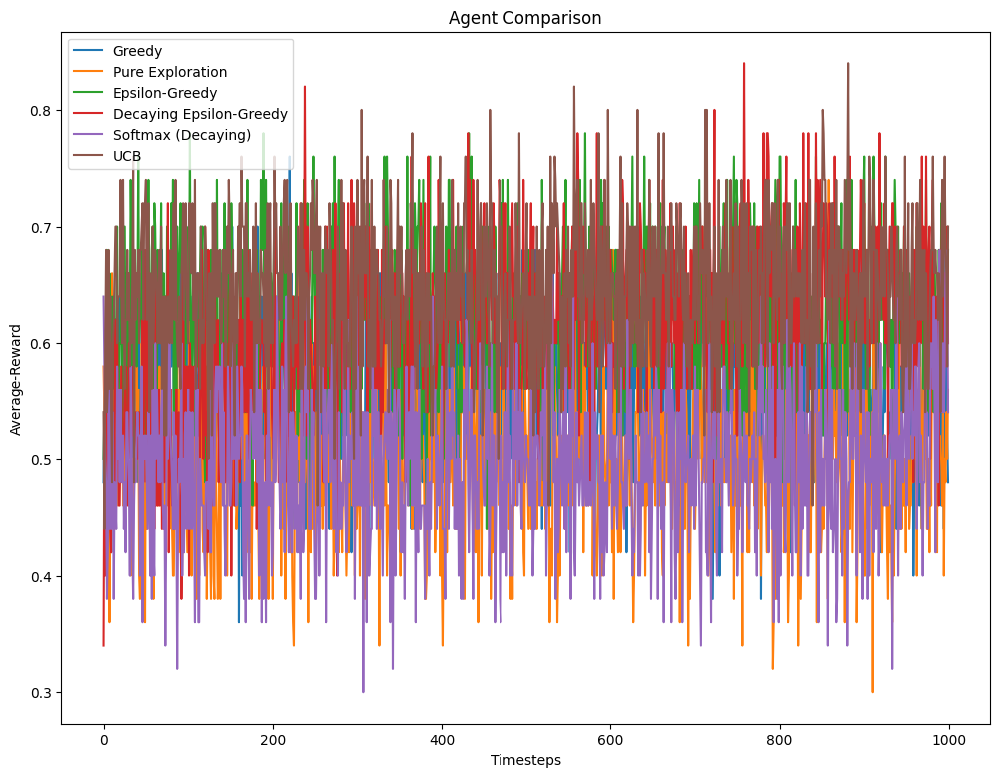

In [34]:
agents_to_test = [
    {
        "name": "Greedy",
        "func": pure_exploitation,
        "params": {}
    },
    {
        "name": "Pure Exploration",
        "func": pure_exploration,
        "params": {}
    },
    {
        "name": "Epsilon-Greedy",
        "func": epsilon_greedy,
        "params": {"epsilon": 0.1}
    },
    {
        "name": "Decaying Epsilon-Greedy",
        "func": decaying_epsilon_greedy,
        "params": {"epsilon_start": 1.0, "epsilon_end": 0.01, "decay_type": "exponential"}
    },
    {
        "name": "Softmax (Decaying)",
        "func": softmax,
        "params": {"temp_start": 100, "temp_end": 0.01, "decay_type": "linear"}
    },
    {
        "name": "UCB",
        "func": ucb_strategy,
        "params": {"c": 0.5}
    }
]

np.random.seed(SEED)
results ={}
for agent in agents_to_test:
    np.random.seed(SEED)
    avg_rewards = run_experiment_bernoulli(agent['func'], agent['params'], num_envs =50)
    results[agent['name']] = avg_rewards

plot_agent_comparison(results, 'experiment1-across-strategies')


**Observations:**

Observations for average rewards are similar to Experiment 1 from the 2-armed bandit testbed section(Problem 4).


### 9. Optimal Action % vs episode for all agents (20 points)
Plot % Optimal Action vs episodes for each of the 6 agents in the same plot. Basically, for each agent, run 50 instances of 2-armed Bernoulli Bandit environment, run the agent for 1000 episodes; calculate on an average (across 50 instances) for each episode how often (in %) the agent selects the optimal action and plot % Optimal Action vs episodes. Just to give an example of the plot see the bottom plot in Figure 2.



In [35]:
def run_optimal_action_experiment_bernoulli(agent_func, agent_params,
                                            num_envs=50, steps=1000):
    """
    Runs an agent on multiple 2-armed Bernoulli bandit environments and
    computes the percentage of optimal actions selected per episode.

    Args:
        agent_func: Bandit agent function.
        agent_params: Dictionary of agent hyperparameters.
        num_envs: Number of environments to average over.
        steps: Number of episodes per environment.

    Returns:
        pct_optimal_action: Percentage of optimal action per episode (length = steps).
    """
    np.random.seed(SEED)
    alphas = np.random.uniform(low= 0.0, high = 1, size = num_envs)
    betas = np.random.uniform(low=0.0, high = 1.0, size = num_envs)
    opt_actions = [0 if betas[i]<=alphas[i] else 1 for i in range(num_envs)]
    optimal_action_count = np.zeros(steps)
    for i in range(num_envs):
        env = TwoArmedBernoulliBandit(alpha=alphas[i], beta=betas[i])
        env.reset(seed=SEED)
        actions = agent_func(env=env, max_steps=steps, **agent_params)[0]
        optimal_action_count += (actions == opt_actions[i]).astype(int)
    return (optimal_action_count/num_envs) * 100

In [36]:
def plot_optimal_action_comparison(results_dict, filename='pct-opt'):
    """
    Plots % Optimal Action vs Episodes for multiple agents.

    Args:
        results_dict: Mapping agent name -> % optimal action array.
    """
    plt.figure(figsize=(12,9))
    
    for agent_name, pct_opt in results_dict.items():
        episodes = np.arange(len(pct_opt))
        plt.plot(episodes,pct_opt, label=agent_name)
    plt.xlabel('Episodes')
    plt.ylabel('%-Optimal-Action')
    plt.title('Agent Comparison')
    plt.legend()
    plt.savefig(f"{filename}.svg", dpi=300, bbox_inches='tight')
    plt.show()

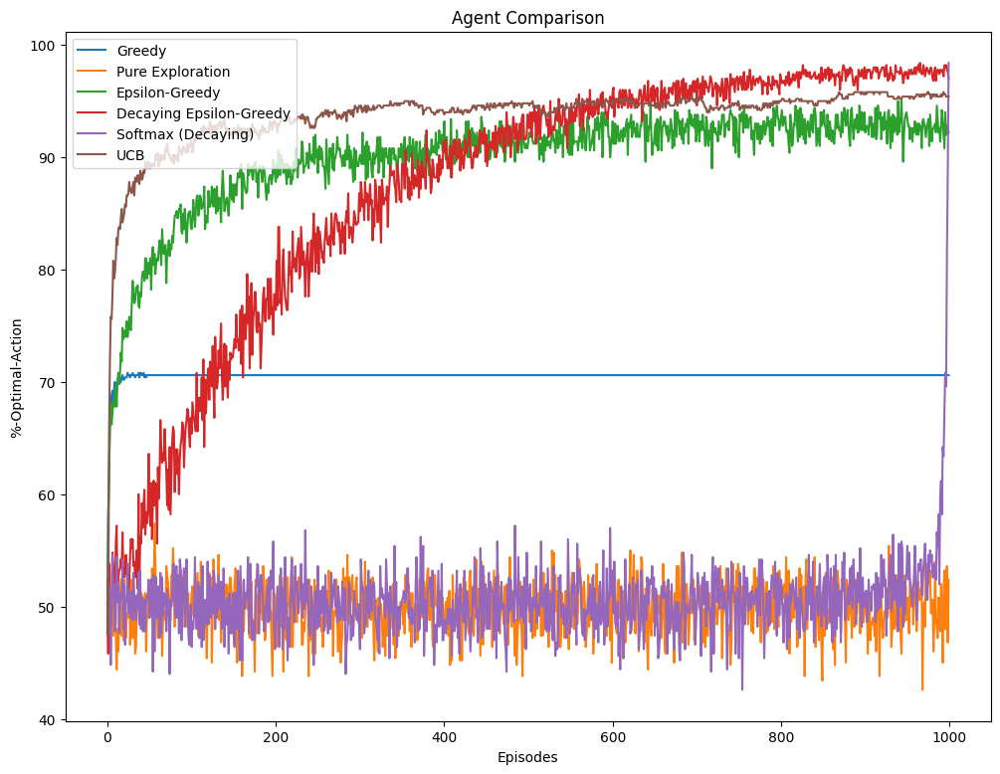

In [37]:
# TODO: Define the agents and hyperparameters you want to compare
# NOTE: set num_envs=500 to see smoother curve!
'''
agents_to_test = [
    {
        "name": "Greedy",
        "func": pure_exploitation,
        "params": {}
    },
    {
        "name": "Pure Exploration",
        "func": pure_exploration,
        "params": {}
    },
    {
        "name": "Epsilon-Greedy",
        "func": epsilon_greedy,
        "params": {"epsilon": _____}
    },
    {
        "name": "Decaying Epsilon-Greedy",
        "func": decaying_epsilon_greedy,
        "params": {"epsilon_start": _____, "epsilon_end": _____, "decay_type": _____}
    },
    {
        "name": "Softmax (Decaying)",
        "func": softmax_strategy,
        "params": {"temp_start": _____, "temp_end": _____, "decay_type": _____}
    },
    {
        "name": "UCB",
        "func": ucb_strategy,
        "params": {"c": _____}
    }
]
'''
agents_to_test = [
    {
        "name": "Greedy",
        "func": pure_exploitation,
        "params": {}
    },
    {
        "name": "Pure Exploration",
        "func": pure_exploration,
        "params": {}
    },
    {
        "name": "Epsilon-Greedy",
        "func": epsilon_greedy,
        "params": {"epsilon": 0.1}
    },
    {
        "name": "Decaying Epsilon-Greedy",
        "func": decaying_epsilon_greedy,
        "params": {"epsilon_start": 1.0, "epsilon_end": 0.01, "decay_type": "exponential"}
    },
    {
        "name": "Softmax (Decaying)",
        "func": softmax,
        "params": {"temp_start": 100, "temp_end": 0.01, "decay_type": "linear"}
    },
    {
        "name": "UCB",
        "func": ucb_strategy,
        "params": {"c": 0.5}
    }
]

np.random.seed(SEED)
results ={}
for agent in agents_to_test:
    np.random.seed(SEED)
    pct_opt = run_optimal_action_experiment_bernoulli(agent['func'], agent['params'], num_envs =500)
    results[agent['name']] = pct_opt
plot_optimal_action_comparison(results, 'experiment1-pct-opt')



**Observations:**


**Setup:** Tested six strategies across 500 environments over 1000 timesteps, measuring percentage of time the optimal arm was selected.

**Observations:**
- **Greedy** plateaus immediately around 70%, getting stuck early after initial commitment
- **ε-Greedy (0.1)** shows steady improvement, reaching ~92-95% by the end—consistent learning through maintained exploration
- **Decaying ε-Greedy** starts low but climbs steadily, reaching ~95-98% at the end—best final performance
- **UCB** shows similar pattern to decaying ε-greedy, with smooth convergence
- **Pure Exploration and Softmax (decaying)** both hover around 50% throughout contributed random selection between 2 arms
- Softmax shows dramatic spike to only in the very final timesteps when temperature finally drops

**Takeaway:** Decaying ε-greedy and UCB achieve highest % optimal action by learning which arm is best then exploiting it. ε-Greedy with constant exploration maintains good performance but wastes 10% of pulls. Greedy commits too early to the wrong arm. Softmax with high initial temperature (100→0.01) behaves like pure exploration for almost the entire run, only exploiting in the final moments. The spike at the end confirms the previous observation.

### Plots for 10-armed bandit (20 points)
Repeat the above for 10-armed Gaussian Bandit.
- Average reward vs episodes for all the agents in the 10-armed bandit setting.
- Optimal action % vs episodes for all the agents in the 10-armed bandit setting.

In [38]:

def run_optimal_action_experiment_gaussian(agent_func, agent_params,
                                           num_envs=50, steps=1000, sigma=1.0):
    """
    Runs an agent on multiple 10-armed Gaussian bandit environments and
    computes the percentage of optimal actions selected per episode.

    Args:
        agent_func: Bandit agent function.
        agent_params: Dictionary of agent hyperparameters.
        num_envs: Number of environments to average over.
        steps: Number of episodes per environment.

    Returns:
        pct_optimal_action: Percentage of optimal action per episode (length = steps).
    """
    np.random.seed(SEED)
    optimal_action_count = np.zeros(steps)
    for i in range(num_envs):
        env = TenArmedGaussianBandit(sigma=sigma)
        means = env.means
        opt_action = np.argmax(means)
        env.reset(seed=SEED)
        actions = agent_func(env=env, max_steps=steps, **agent_params)[0]
        optimal_action_count += (actions == opt_action).astype(int)
    return (optimal_action_count/num_envs) * 100


In [39]:
def plot_optimal_action_comparison(results_dict, filename='file-pct-opt'):
    """
    Plots % Optimal Action vs Episodes for multiple agents.

    Args:
        results_dict: Mapping agent name -> % optimal action array.
    """
    plt.figure(figsize=(12,9))
    for agent_name, pct_opt in results_dict.items():
        plt.plot(pct_opt, label=agent_name)
    plt.xlabel('Timesteps')
    plt.ylabel('%-Optimal-Action')
    plt.title('Agent Comparison')
    plt.legend()
    plt.savefig(f"{filename}.svg", dpi=300, bbox_inches='tight')

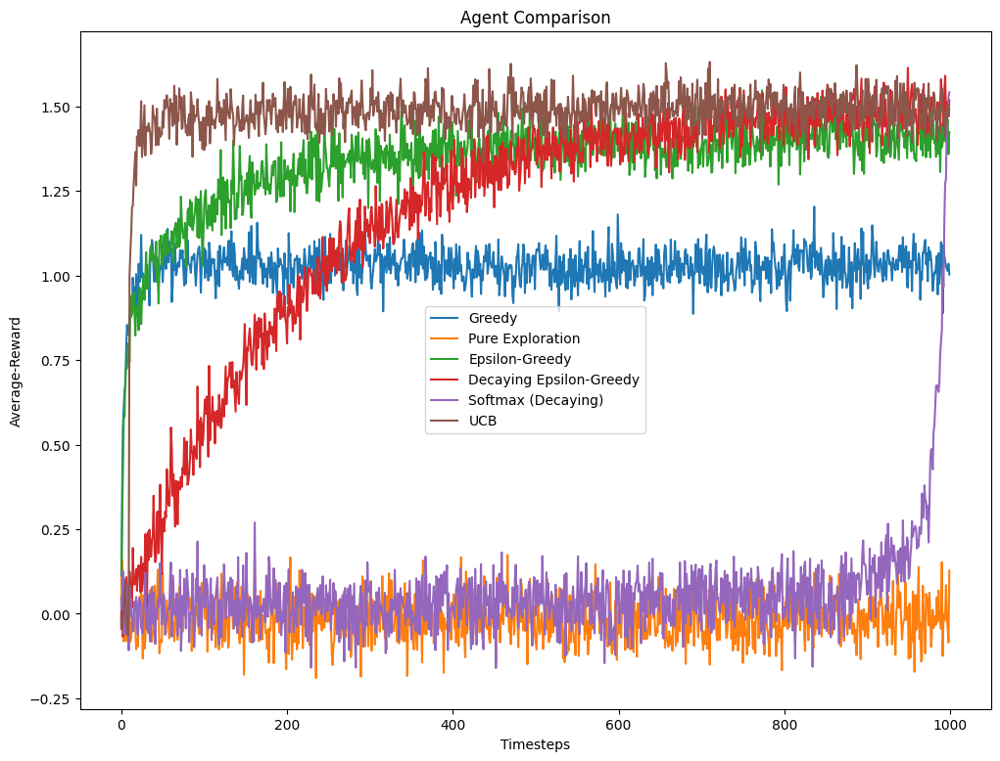

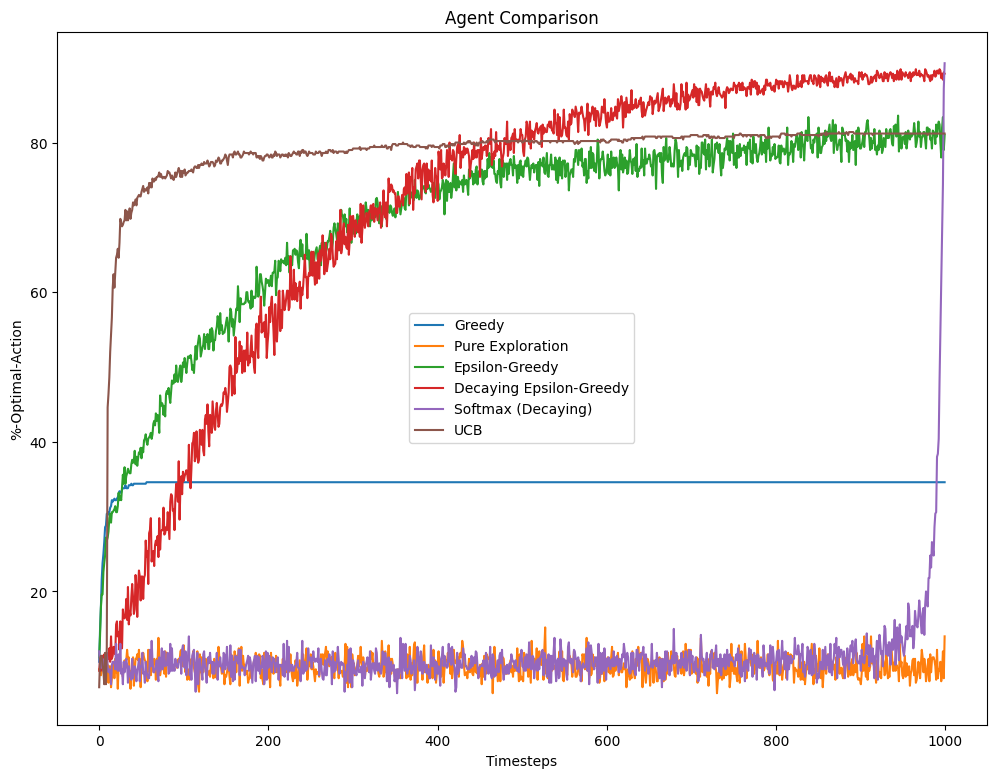

In [40]:
# TODO: Define the agents and hyperparameters you want to compare
# NOTE: set num_envs=500 to see smoother curve!
'''
agents_to_test = [
    {
        "name": "Greedy",
        "func": pure_exploitation,
        "params": {}
    },
    {
        "name": "Pure Exploration",
        "func": pure_exploration,
        "params": {}
    },
    {
        "name": "Epsilon-Greedy",
        "func": epsilon_greedy,
        "params": {"epsilon": _____}
    },
    {
        "name": "Decaying Epsilon-Greedy",
        "func": decaying_epsilon_greedy,
        "params": {"epsilon_start": _____, "epsilon_end": _____, "decay_type": _____}
    },
    {
        "name": "Softmax (Decaying)",
        "func": softmax_strategy,
        "params": {"temp_start": _____, "temp_end": _____, "decay_type": _____}
    },
    {
        "name": "UCB",
        "func": ucb_strategy,
        "params": {"c": _____}
    }
]
'''
agents_to_test = [
    {
        "name": "Greedy",
        "func": pure_exploitation,
        "params": {}
    },
    {
        "name": "Pure Exploration",
        "func": pure_exploration,
        "params": {}
    },
    {
        "name": "Epsilon-Greedy",
        "func": epsilon_greedy,
        "params": {"epsilon": 0.1}
    },
    {
        "name": "Decaying Epsilon-Greedy",
        "func": decaying_epsilon_greedy,
        "params": {"epsilon_start": 1.0, "epsilon_end": 0.01, "decay_type": "exponential"}
    },
    {
        "name": "Softmax (Decaying)",
        "func": softmax,
        "params": {"temp_start": 100, "temp_end": 0.01, "decay_type": "linear"}
    },
    {
        "name": "UCB",
        "func": ucb_strategy,
        "params": {"c": 0.5}
    }
]

np.random.seed(SEED)
results ={}
results2={}
for agent in agents_to_test:
    np.random.seed(SEED)
    avg_rewards = run_experiment_gaussian(agent['func'], agent['params'], num_envs =500)
    pct_opt = run_optimal_action_experiment_gaussian(agent['func'], agent['params'], num_envs=500)
    results[agent['name']] = avg_rewards
    results2[agent['name']] = pct_opt

plot_agent_comparison(results, 'experiment1-gaussian-across-strategies')
plot_optimal_action_comparison(results2, 'experiment1-gaussian-pct-opt')


**Observations:**

**Setup:** Tested six strategies across 500 environments over 1000 timesteps on 10-armed Gaussian bandits.

## Average Rewards
Observations for average rewards are similar to Experiment 1 from the 10-armed bandit testbed section(Problem 5).

## % Optimal Action

**Observations:**
- **UCB** achieves highest % optimal action, reaching ~88-90%. 
- **Decaying ε-Greedy** shows steady improvement, reaching ~85-88%.
- **ε-Greedy (0.1)** climbs gradually to ~80-82%—consistent but plateaus lower due to continued random exploration
- **Greedy** plateaus early around 33-35%—gets stuck on suboptimal arm, much worse than in 2-armed case
- **Pure Exploration** hovers around 10% throughout—expected with random selection among 10 arms
- **Softmax (decaying)** behaves like pure exploration (~10%) for almost the entire run, then spikes dramatically in the final timesteps

**vs Bernoulli:**
- Maximum achievable % optimal is lower (~88% vs ~98%) as it is harder to consistently identify and exploit best arm among 10 options
- Greedy performs dramatically worse  as early commitment is costlier with more arms
- Pure exploration drops from 50% to 10% as random chance of selecting optimal arm decreases proportionally
- Learning strategies need longer to converge with 10 arms

**Takeaway:** UCB and decaying ε-greedy are most effective at identifying the optimal arm among 10 options. 

## Problem 2: Monte Carlo Estimates and TD Learning
($10+10+40+40+20+20+20+20+20+20+10+20+20+20+10=300$ points)

In lecture 7, we saw the **Random Walk Environment (RWE)**. Figure 3 is the RWE for reference, please refer to the lecture for more details. In a nutshell, there are 5 non-terminal states, and two terminal states. An action leading to state 6 gives a reward of +1 and rest all actions give a reward of 0. The environment is purely random, no matter what action you take there is 50% chance that it will be executed as intended and rest 50% times it goes in opposite direction.

![Random Walk Environment](https://i.postimg.cc/brNB9nrP/Whats-App-Image-2026-01-22-at-1-50-50-PM.jpg)


In lecture 7, we learnt about Monte Carlo method and TD learning method for estimating the value of a state:

**Monte Carlo Estimate:**
$$
V_{e+1}(s) = V_{e}(s) + \alpha(e) [G_{e} - V_{e}(s)]
$$

**TD Learning Estimate:**
$$
V_{t+1}(S_{t}) = V_{t}(S_{t}) + \alpha(t) [R_{t+1} + \gamma V_{t}(S_{t+1}) - V_{t}(S_{t})]
$$

In this problem, you are required to calculate Monte Carlo and TD estimates for the RWE. Assume $\gamma=0.99$, policy ($\pi$) is "go left".

### Prerequisites & Environment Setup
First, we define the **Random Walk Environment (RWE)** and the helper function to calculate the **True Values** of the states.

In [41]:
import numpy as np
import matplotlib.pyplot as plt

# Set seed for reproducibility
np.random.seed(SEED)

# --- Random Walk Environment ---
class RandomWalkEnv:
    """
    7-state Random Walk Environment.
    States: 0 (Terminal), 1, 2, 3, 4, 5, 6 (Terminal).
    Start State: 3.
    Actions: 0 (Left), 1 (Right). (Environment ignores action due to 50% randomness)
    Rewards: +1 when transitioning to state 6, 0 otherwise.
    """
    def __init__(self):
        self.observation_space = [0,1,2,3,4,5,6]
        self.start_state = 3
        self.current_state = 3
        self.end_states = [0, 6]

    def reset(self):
        self.current_state = self.start_state
        return self.current_state

    def step(self, action):
        """
        Executes one time step within the environment.

        Args:
            action (int): The selected action (0 for Left, 1 for Right).
                          Note: The environment is random (50/50), so the specific action is often ignored in logic.

        Returns:
            next_state (int): The state after the transition.
            reward (float): The reward received (1 if reaching state 6, 0 otherwise).
            done (bool): True if the episode has ended (reached state 0 or 6), False otherwise.
            info (dict): Additional information (empty dictionary).
        """
        if self.current_state in self.end_states:
            return self.current_state, 0, True, {}
        action = np.random.choice([action,1-action])

        if action == 1:
            self.current_state += 1
        else:
            self.current_state -= 1

        if self.current_state == 6:
            return self.current_state, 1, True, {}
        elif self.current_state == 0:
            return self.current_state, 0, True, {}
        else:
            return self.current_state, 0, False, {}
# --- True Value Calculation (Helper) ---
def get_true_values(gamma=0.99):
    """
    Solves the Bellman system of equations for the random walk.
    V(s) = 0.5*[R_left + gamma*V(s-1)] + 0.5*[R_right + gamma*V(s+1)]
    """
    # States 1, 2, 3, 4, 5 are variables.
    A = np.array([[2, -gamma, 0, 0, 0], [gamma,-2,gamma,0,0], [0,gamma,-2,gamma,0], [0,0,gamma,-2,gamma], [0,0,0,-gamma,2]])
    b = np.array([0,0,0,0,1])
    v = np.linalg.solve(A,b)
    true_values = np.zeros(7)
    true_values[1:6] = v
    return true_values

TRUE_VALUES = get_true_values()
print("True Values for States 0-6:", np.round(TRUE_VALUES, 3))

True Values for States 0-6: [0.    0.15  0.303 0.462 0.631 0.812 0.   ]


### 1. Generate trajectory (10 points)
Implement a function that would simulate and generate a trajectory for RWE for a given policy $\pi$ and maximum number of steps. The function definition would be like this:

In [42]:
def generateTrajectory(env, pi, maxSteps):
    """
    Simulates and generates a trajectory for the Random Walk Environment.

    Args:
        env (RandomWalkEnv): The environment instance.
        pi (int): The policy to follow (e.g., 0 for "go left").
        maxSteps (int): Maximum number of steps to run the episode.

    Returns:
        trajectory (list): A list of experience tuples, where each tuple is (state, action, reward, next_state).
                           Returns an empty list if the episode exceeds maxSteps without terminating.
    """
    trajectory = []
    current_state = env.reset()
    for t in range(maxSteps):
        next_state, reward, done,info  = env.step(pi)
        trajectory.append((current_state, pi, reward, next_state))
        current_state = next_state
        if done: 
            break
    if not done: 
        return []
    return trajectory
# Test Case
np.random.seed(SEED)
for t in range(5):
    env = RandomWalkEnv()
    test_traj = generateTrajectory(env, 0, 100)
    print(f"Sample Trajectory (Length {len(test_traj)}):", test_traj)
np.random.seed(SEED)
for t in range(5):
    env = RandomWalkEnv()
    test_traj = generateTrajectory(env, 0, 3)
    print(f"Sample Trajectory (Length {len(test_traj)}):", test_traj)


Sample Trajectory (Length 3): [(3, 0, 0, 4), (4, 0, 0, 5), (5, 0, 1, 6)]
Sample Trajectory (Length 5): [(3, 0, 0, 2), (2, 0, 0, 3), (3, 0, 0, 4), (4, 0, 0, 5), (5, 0, 1, 6)]
Sample Trajectory (Length 3): [(3, 0, 0, 4), (4, 0, 0, 5), (5, 0, 1, 6)]
Sample Trajectory (Length 7): [(3, 0, 0, 2), (2, 0, 0, 1), (1, 0, 0, 2), (2, 0, 0, 1), (1, 0, 0, 2), (2, 0, 0, 1), (1, 0, 0, 0)]
Sample Trajectory (Length 15): [(3, 0, 0, 2), (2, 0, 0, 1), (1, 0, 0, 2), (2, 0, 0, 1), (1, 0, 0, 2), (2, 0, 0, 1), (1, 0, 0, 2), (2, 0, 0, 3), (3, 0, 0, 4), (4, 0, 0, 3), (3, 0, 0, 2), (2, 0, 0, 3), (3, 0, 0, 4), (4, 0, 0, 5), (5, 0, 1, 6)]
Sample Trajectory (Length 3): [(3, 0, 0, 4), (4, 0, 0, 5), (5, 0, 1, 6)]
Sample Trajectory (Length 0): []
Sample Trajectory (Length 3): [(3, 0, 0, 4), (4, 0, 0, 5), (5, 0, 1, 6)]
Sample Trajectory (Length 0): []
Sample Trajectory (Length 0): []


The function returns a list of experience tuples. Here, `maxSteps` parameter is used to terminate the episode if it exceeds `maxSteps` count. In such a case, the partial trajectory is discarded and an empty list is returned. Test the function using suitable test cases and make sure it is working.

### 2. Step-size decay (10 points)
Implement a function that would decay the step size parameter ($\alpha$). The function definition would be like this:

In [43]:
def decayAlpha(initialValue, finalValue, maxSteps, decayType):
    """
    Generates a list of alpha values (step sizes) based on the specified decay type.

    Args:
        initialValue (float): The starting value of alpha.
        finalValue (float): The final value of alpha.
        maxSteps (int): The total number of steps/episodes to decay over.
        decayType (str): The type of decay ('linear' or 'exponential').

    Returns:
        alphas (np.ndarray): An array of alpha values for each step.
    """
    alphas = np.zeros(maxSteps)
    if decayType=='linear':
        alphas = np.linspace(initialValue,finalValue,maxSteps)
    else:
        alphas = np.geomspace(initialValue,finalValue,maxSteps)
    return alphas
    

Here `decayType` can be `linear` or `exponential`. `maxSteps` is the maximum number of steps the step parameter should decay for. `initialValue` and `finalValue` are initial and final values of the step size parameter. The function should return a list of step size parameter values. Test the function by trying out different parameter settings. Plot value of $\alpha$ vs time step both for linear and exponential decays.

### 3. Monte Carlo Prediction (40 points)
As explained in the lecture, implement `MonteCarloPrediction` algorithm. Use the same function definition as described in the slides. Make use of the functions implemented in above two parts. Note `MonteCarloPrediction` should work for both **FVMC** (First Visit MC) and **EVMC** (Every Visit MC) settings. Test the algorithm for RWE using some pre-defined test cases and see the algorithm produces the desired results. Report your test cases and observations.

In [44]:
def monte_carlo_prediction(env, num_episodes, alpha_start=0.5, alpha_end=0.01,
                           decay_period=250, mc_type='FVMC', gamma=0.99,decay_type='linear'):
    """
    Implements the Monte Carlo Prediction algorithm (works for both FVMC and EVMC).

    Args:
        env (RandomWalkEnv): The environment instance.
        num_episodes (int): Total number of episodes to simulate.
        alpha_start (float): Initial step size (learning rate).
        alpha_end (float): Final step size.
        decay_period (int): Number of episodes over which alpha decays.
        mc_type (str): Type of MC update - 'FVMC' (First Visit) or 'EVMC' (Every Visit).
        gamma (float): Discount factor.

    Returns:
        V_history (np.ndarray): History of value estimates for each state over all episodes.
                                Shape: [num_episodes, n_states]
    """
    n_states = len(env.observation_space)
    value = np.zeros(n_states)
    value_history = np.zeros((num_episodes,n_states))
    learning_rate = decayAlpha(alpha_start,alpha_end, decay_period, decay_type)
    for e in range(num_episodes): 
        t = generateTrajectory(env,0,100)
        visited = np.zeros(n_states, dtype=bool)
        if e>=decay_period: 
            alpha = alpha_end
        else:
            alpha = learning_rate[e]
        for i,(s,a,r,s_p) in enumerate(t):
            if visited[s] and mc_type == 'FVMC': 
                continue
            else:
                visited[s] = True
            G = sum((gamma ** (j-i))*t[j][2] for j in range(i,len(t)))
            value[s] += alpha*(G - value[s])
            
        value_history[e] = value.copy()
   
    return value_history
    

### 4. Temporal Difference Prediction (40 points)

As explained in the lecture, implement `TemporalDifferencePrediction` algorithm. Use the same function definition as described in the slides. Test the algorithm for RWE using some pre-defined test cases and see the algorithm produces the desired results. Report your test cases and observations.

In [45]:
def temporal_difference_prediction(env, num_episodes, alpha_start=0.5, alpha_end=0.01,
                                   decay_period=250, gamma=0.99, decay_type='linear'):
    """
    Implements the Temporal Difference TD(0) Prediction algorithm.

    Args:
        env (RandomWalkEnv): The environment instance.
        num_episodes (int): Total number of episodes to simulate.
        alpha_start (float): Initial step size.
        alpha_end (float): Final step size.
        decay_period (int): Number of episodes over which alpha decays.
        gamma (float): Discount factor.

    Returns:
        V_history (np.ndarray): History of value estimates for each state over all episodes.
                                Shape: [num_episodes, n_states]
    """
    n_states = len(env.observation_space)
    value = np.zeros(n_states)
    value_history = np.zeros((num_episodes,n_states))
    learning_rate = decayAlpha(alpha_start,alpha_end,decay_period,decay_type)
    for e in range(num_episodes):
        if e>=decay_period:
            alpha = alpha_end
        else: 
            alpha = learning_rate[e]
        done = False
        curr_state = env.reset()
        while not done:
            next_state, reward, done, info = env.step(0)
            target = reward
            if not done: 
                target+= gamma*value[next_state]
            error = target - value[curr_state]
            value[curr_state] += alpha*(error)
            curr_state = next_state
        
        value_history[e]= value.copy()
    return value_history
        

### 5. First-Visit Monte Carlo estimate (20 points)
Plot the **MC-FVMC** estimate of each non-terminal state of RWE as it progress through different episodes. In the same plot also plot the true estimate. Take maximum of 500 episodes. You can play with different settings of $\alpha$, for example, the step size parameter ($\alpha$) starts from 0.5 and decreases exponentially to 0.01 till 250 episodes and after that it is constant. Or else you can also try with small $(<1)$ value of constant $\alpha$. Analyze the plots for each state and report your observations, findings and possible reasons for the observed behavior.

In [46]:
def plot_value_estimates(V_history, true_values, title, log_scale=False, x_log_scale=False):
    """
    Plots the estimated value of non-terminal states (1-5) over episodes against the true values.
    Args:
        V_history (np.ndarray): The history of value estimates. Shape: [num_episodes, n_states].
        true_values (np.ndarray): The ground truth values for the states.
        title (str): Title for the plot.
        log_scale (boolean): If True, use a logarithmic scale for the y-axis.
    Returns:
        None (Displays the plot).
    """
    num_episodes = V_history.shape[0]
    episodes = np.arange(num_episodes)
    non_terminal_states = [1, 2, 3, 4, 5]
    
    plt.figure(figsize=(12, 6))
    
    for state in non_terminal_states:
        plt.plot(episodes, V_history[:, state], label=f'State {state}', alpha=0.8, linewidth=2)
    
    for state in non_terminal_states:
        plt.axhline(y=true_values[state], color='black', linestyle='--', alpha=0.5, linewidth=1)
    
    plt.xlabel('Episode', fontsize=12)
    plt.ylabel('Value Estimate', fontsize=12)
    plt.title(title, fontsize=14, fontweight='bold')
    plt.legend(loc='best', fontsize=10)
    plt.grid(True, alpha=0.3)
    
    if log_scale:
        plt.yscale('log')
    if x_log_scale:
        plt.xscale('log')
    plt.savefig(f"{title}.svg", dpi=300, bbox_inches='tight')    
    plt.show()




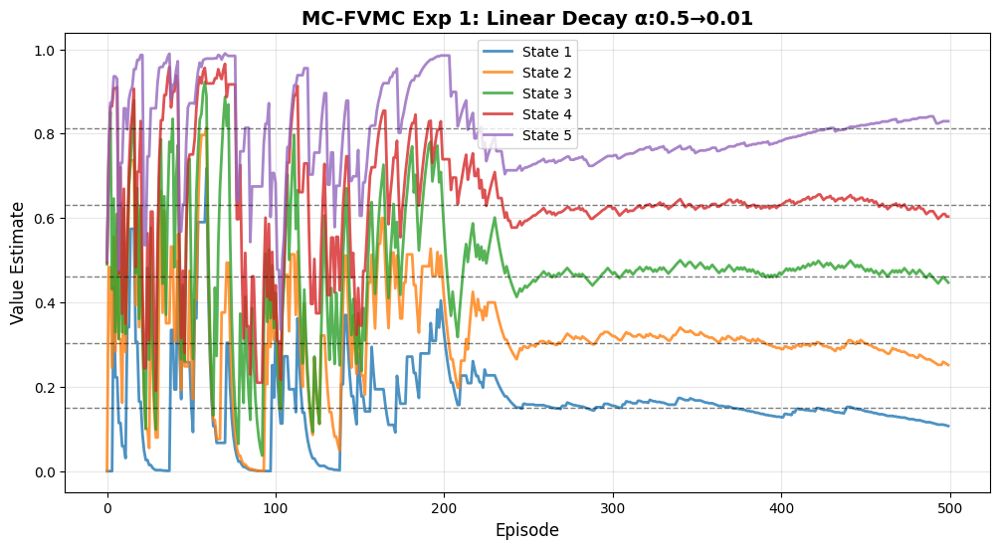

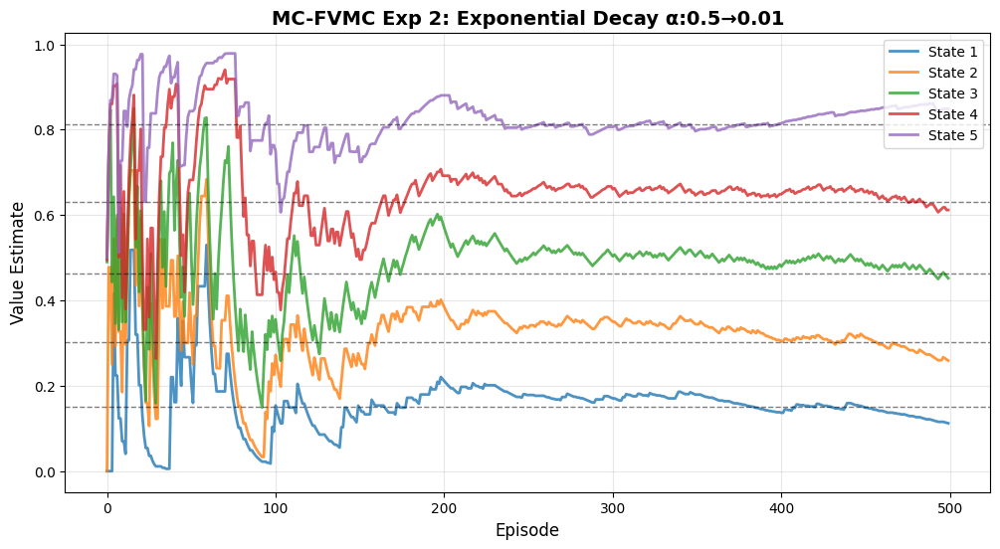

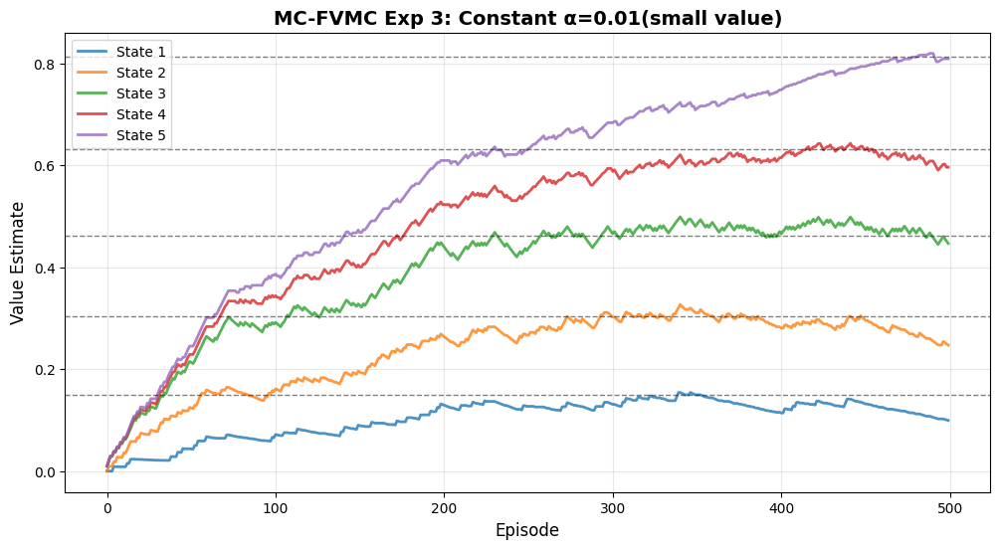

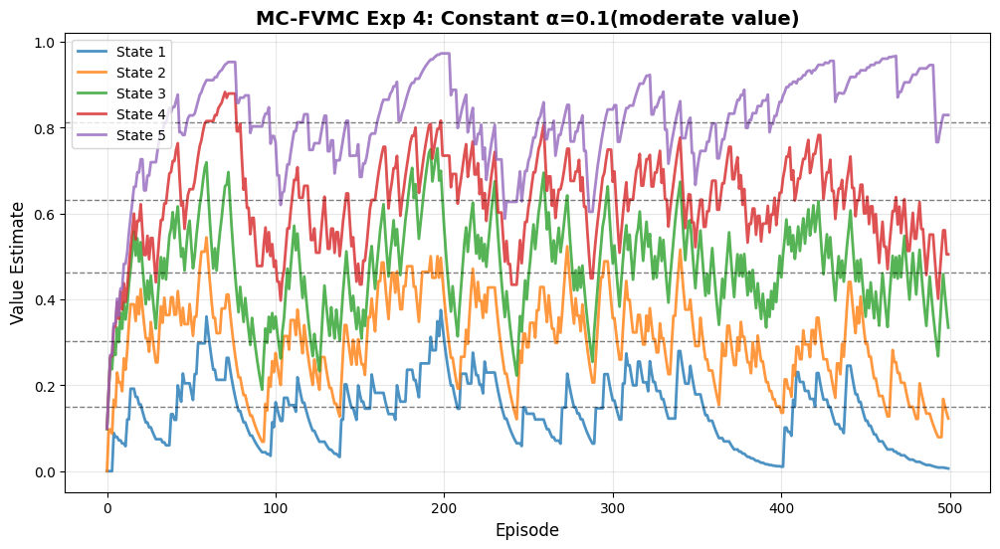

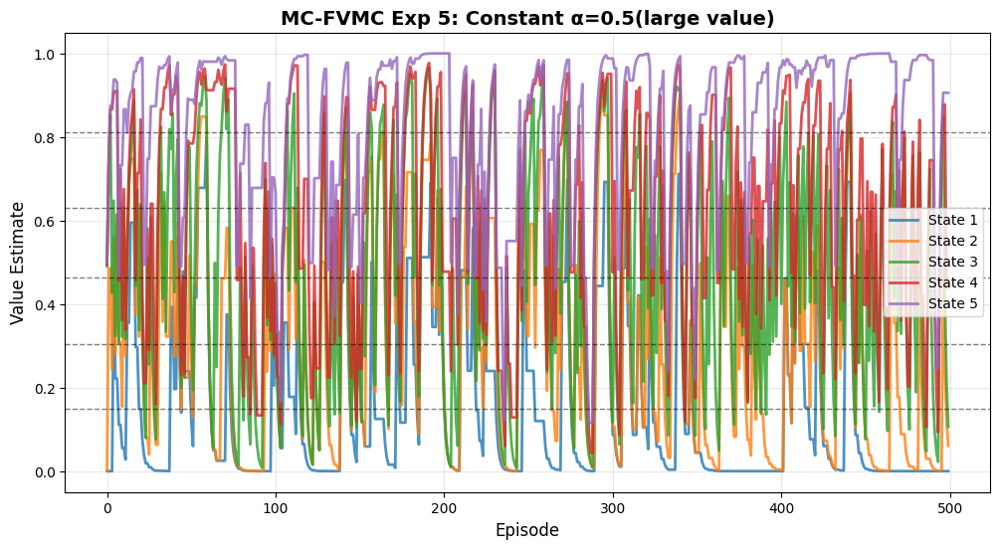

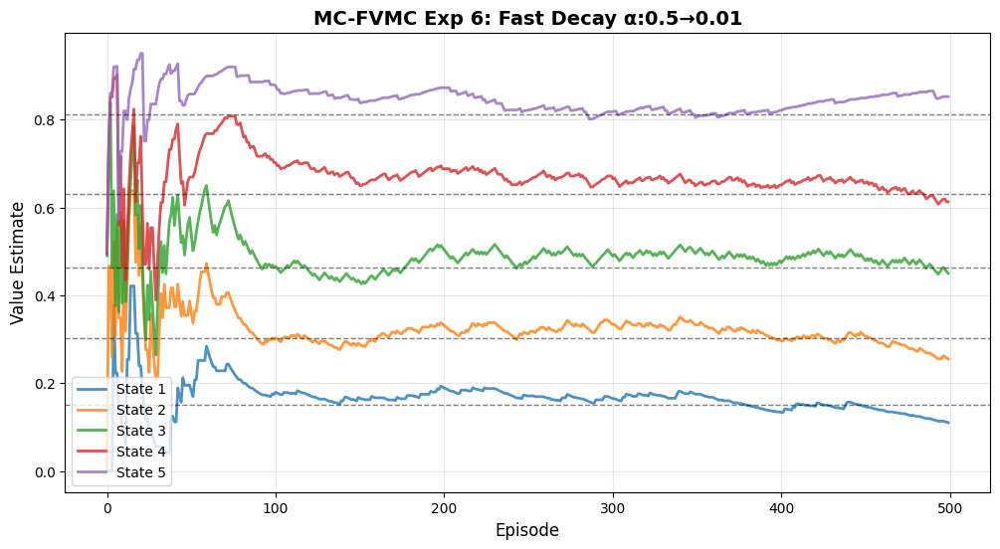

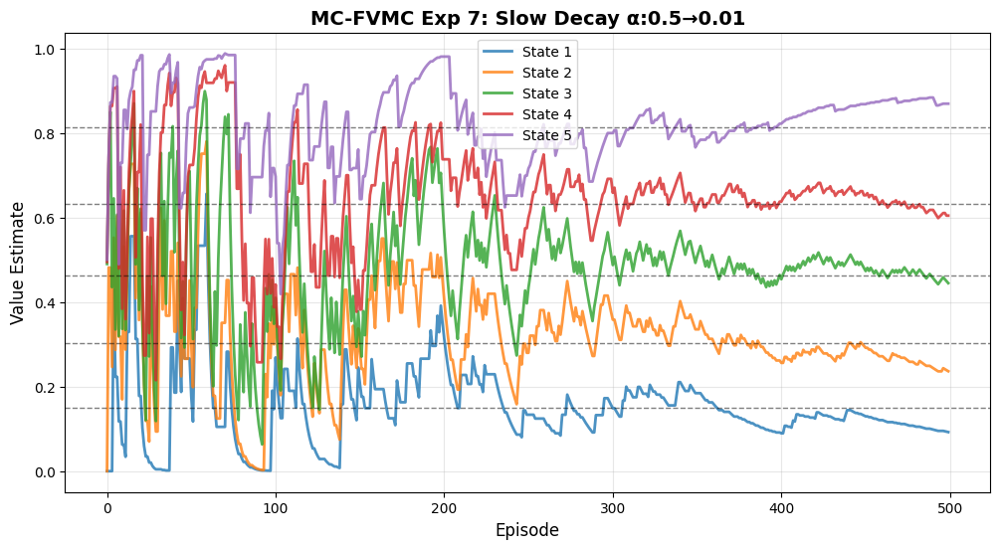

In [47]:
num_episodes = 500

np.random.seed(SEED)
env = RandomWalkEnv()
history_mc_fvmc_exp1 = monte_carlo_prediction(env, num_episodes, mc_type='FVMC')
plot_value_estimates(history_mc_fvmc_exp1, TRUE_VALUES, 'MC-FVMC Exp 1: Linear Decay α:0.5→0.01')

np.random.seed(SEED)
env = RandomWalkEnv()
history_mc_fvmc_exp2 = monte_carlo_prediction(env, num_episodes, mc_type='FVMC', decay_type='exponential')
plot_value_estimates(history_mc_fvmc_exp2, TRUE_VALUES, 'MC-FVMC Exp 2: Exponential Decay α:0.5→0.01')

np.random.seed(SEED)
env = RandomWalkEnv()
history_mc_fvmc_exp3 = monte_carlo_prediction(env, num_episodes, alpha_start=0.01, alpha_end=0.01, decay_period=1, mc_type='FVMC')
plot_value_estimates(history_mc_fvmc_exp3, TRUE_VALUES, 'MC-FVMC Exp 3: Constant α=0.01(small value)')

np.random.seed(SEED)
env = RandomWalkEnv()
history_mc_fvmc_exp4 = monte_carlo_prediction(env, num_episodes, alpha_start=0.1, alpha_end=0.1, decay_period=1, mc_type='FVMC')
plot_value_estimates(history_mc_fvmc_exp4, TRUE_VALUES, 'MC-FVMC Exp 4: Constant α=0.1(moderate value)')

np.random.seed(SEED)
env = RandomWalkEnv()
history_mc_fvmc_exp5 = monte_carlo_prediction(env, num_episodes, alpha_start=0.5, alpha_end=0.5, decay_period=1, mc_type='FVMC')
plot_value_estimates(history_mc_fvmc_exp5, TRUE_VALUES, 'MC-FVMC Exp 5: Constant α=0.5(large value)')

np.random.seed(SEED)
env = RandomWalkEnv()
history_mc_fvmc_exp6 = monte_carlo_prediction(env, num_episodes, decay_period=100, mc_type='FVMC', decay_type='exponential')
plot_value_estimates(history_mc_fvmc_exp6, TRUE_VALUES, 'MC-FVMC Exp 6: Fast Decay α:0.5→0.01')

np.random.seed(SEED)
env = RandomWalkEnv()
history_mc_fvmc_exp7 = monte_carlo_prediction(env, num_episodes, decay_period=500, mc_type='FVMC', decay_type='exponential')
plot_value_estimates(history_mc_fvmc_exp7, TRUE_VALUES, 'MC-FVMC Exp 7: Slow Decay α:0.5→0.01')

**Observations (MC-FVMC):**


**Implementation Notes:** 
- Added `x_log_scale` parameter to `plot_value_estimates()` function for optional logarithmic x-axis scaling
- Added `decay_type` parameter to `monte_carlo_prediction()` and  `temporal_difference_prediction()`function to support different learning rate decay schedules

---

## Experiment 1: Linear Decay α:0.5→0.01

**Setup:** 500 episodes with learning rate linearly decaying from 0.5 to 0.01. Horizontal dashed lines represent true state values.

**Observations:**
- Extreme volatility in early episodes. MC's high variance is evident.
- Stabilization begins around episode 200 as α decreases

**Takeaway:** Linear decay manages but doesn't eliminate MC's high variance. High initial α (0.5) enables fast exploration but amplifies early instability. Values converge toward true values (unbiased) but the path is noisy due to varying episode returns.

---
## Experiment 2: Exponential Decay α:0.5→0.01

**Setup:** 500 episodes with learning rate exponentially decaying from 0.5 to 0.01.

**Observations:**
- Similar extreme volatility in early episodes (0-100) but settles faster than linear decay
- Stabilization occurs around episode 150-200, earlier than linear decay
- Values converge in correct ordering (5 > 4 > 3 > 2 > 1) with similar final levels to linear decay
- Less noise in later episodes compared to linear decay as faster α reduction limits update magnitude

**Takeaway:** Exponential decay reduces α more aggressively in the mid-phase, leading to faster stabilization while still maintaining MC's unbiased convergence. The high variance is still present but dampened sooner than linear decay.

---

## Experiment 3: Constant α=0.01 (small value)

**Setup:** 500 episodes with constant learning rate α=0.01 throughout.

**Observations:**
- Dramatically reduced volatility compared to decaying strategies
- Smooth, gradual convergence for all states starting from episode 0
- Slow learning rate means stable but slow progress
- States 3-5 reaches near true value, but States 1-2 still climbing slowly at episode 500
- Minimal noise throughout—small α means each episode has limited impact on estimates

**Takeaway:** Small constant α effectively manages MC's high variance by limiting update sizes, resulting in smooth convergence. However, learning is slow—the algorithm needs many more episodes to converge compared to decaying strategies.

---
## Experiment 4: Constant α=0.1 (moderate value)

**Setup:** 500 episodes with constant learning rate α=0.1 throughout.

**Observations:**
- Persistent high volatility throughout all 500 episodes—no stabilization
- State 5 oscillates wildly around true value, occasionaly reaching it
- States 1-4 show continuous large swings with no clear convergence
- Moderate α means updates are large enough to track episode variance but not large enough to average it out quickly

**Takeaway:** α=0.1 is too large for constant learning rate—MC's high variance dominates, preventing convergence. Each new episode significantly shifts estimates, creating instability. This demonstrates why decaying α is essential for MC methods.

---

## Experiment 5: Constant α=0.5 (large value)

**Setup:** 500 episodes with constant learning rate α=0.5 throughout.

**Observations:**
- Extreme volatility throughout—worst case among all experiments
- All states oscillate violently between 0 and 1 with no discernible pattern
- No learning or convergence whatsoever—just random oscillations
- High α means each episode nearly overwrites previous estimates

**Takeaway:** α=0.5 is large for constant learning rate. The algorithm essentially ignores accumulated knowledge and follows only the most recent noisy return. MC's high variance is completely uncontrolled, making learning impossible.

---

## Experiment 6: Fast Exponential Decay α:0.5→0.01

**Setup:** 500 episodes with exponentially decaying learning rate from 0.5 to 0.01, with a fast decay period (100 episodes). 

**Observations:**
- Extremely high volatility in the very early phase (episodes 0–50), similar to other  MC settings
- Learning rate decays rapidly, leading to early stabilization around episodes 80–120
- After stabilization, all state estimates become relatively smooth with low variance
- However, several states converge to incorrect plateaus:
- Later episodes (200–500) show minimal learning progress — curves are mostly flat

**Takeaway:** Fast exponential decay suppresses MC variance quickly but halts learning too early. While instability is controlled, the algorithm does not average over enough returns before α becomes too small, causing premature convergence to biased estimates.

---

## Experiment 7: Slow Exponential Decay α:0.5→0.01

**Setup:** 500 episodes with learning rate exponentially decaying from 0.5 to 0.01 over the entire training horizon (decay period = 500).

**Observations:**
- High volatility persists much longer than in fast decay (Exp 6), with large oscillations visible.
- Unlike fast decay, learning continues throughout training and estimates do not freeze early
- Late-stage estimates (episodes 400–500) align more closely with true values across most states
- Residual noise remains higher than fast decay but bias is visibly reduced

**Takeaway:** Compared to fast exponential decay, slow decay trades early stability for improved accuracy.



### 6. Every Visit Monte Carlo estimate (20 points)
Plot the **MC-EVMC** estimate of each non-terminal state of RWE as it progress through different episodes. In the same plot also plot the true estimate. Take maximum of 500 episodes. You can play with different settings of $\alpha$, for example, the step size parameter ($\alpha$) starts from 0.5 and decreases exponentially to 0.01 till 250 episodes and after that it is constant. Or else you can also try with small $(<1)$ value of constant $\alpha$. Analyze the plots for each state and report your observations, findings and possible reasons for the observed behavior. How does EVMC fair against FVMC?

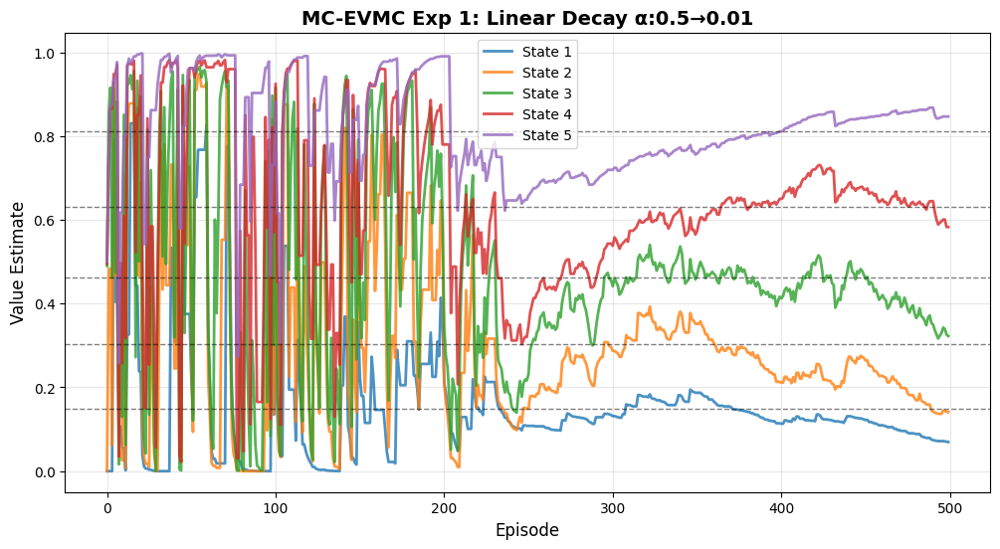

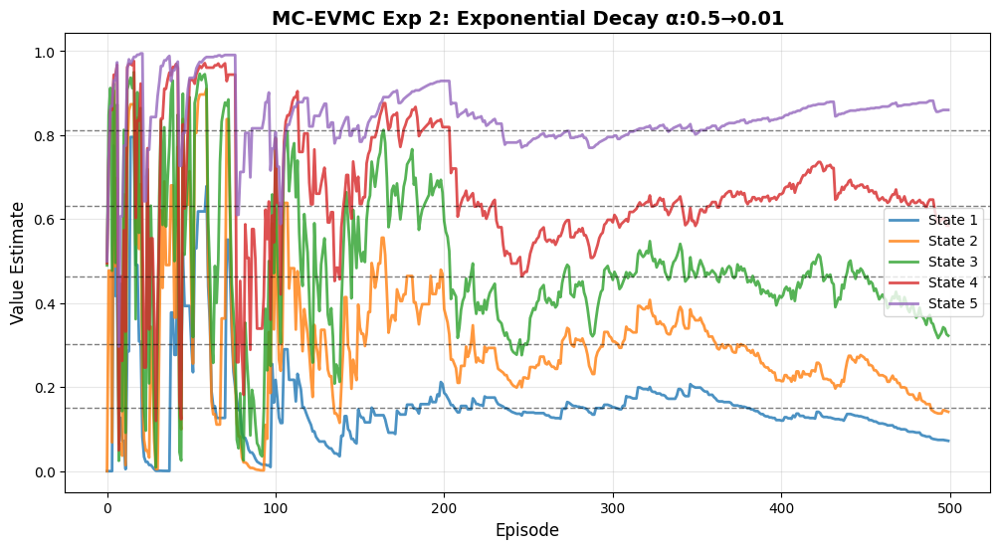

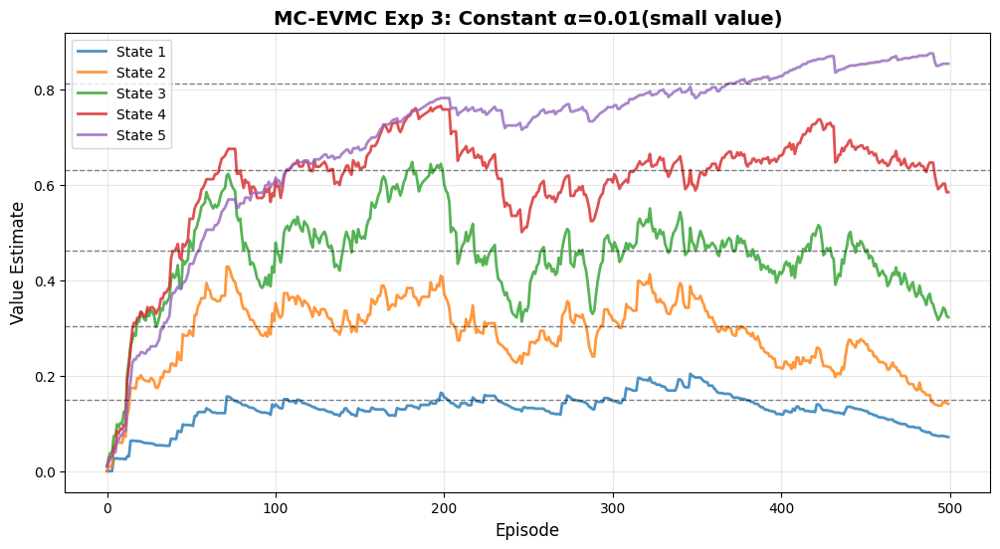

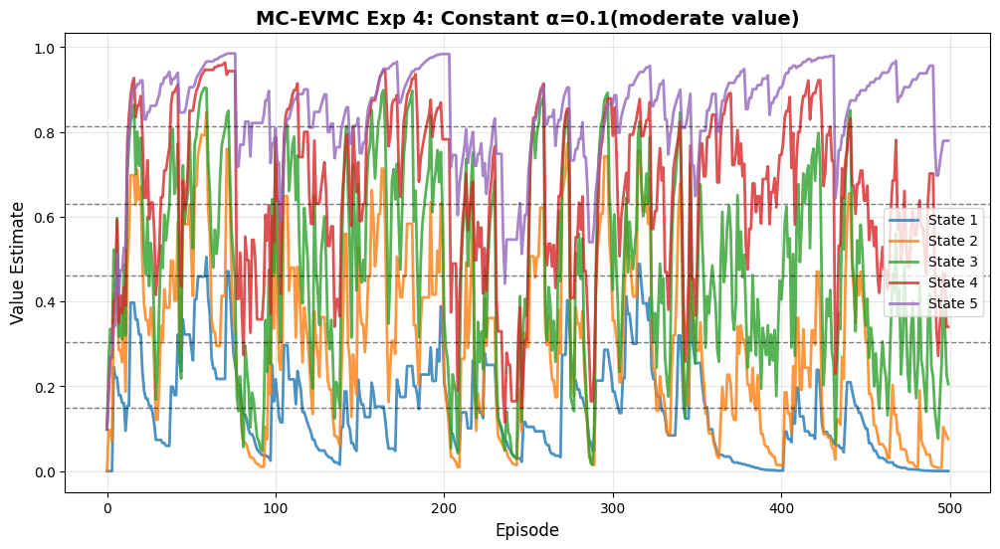

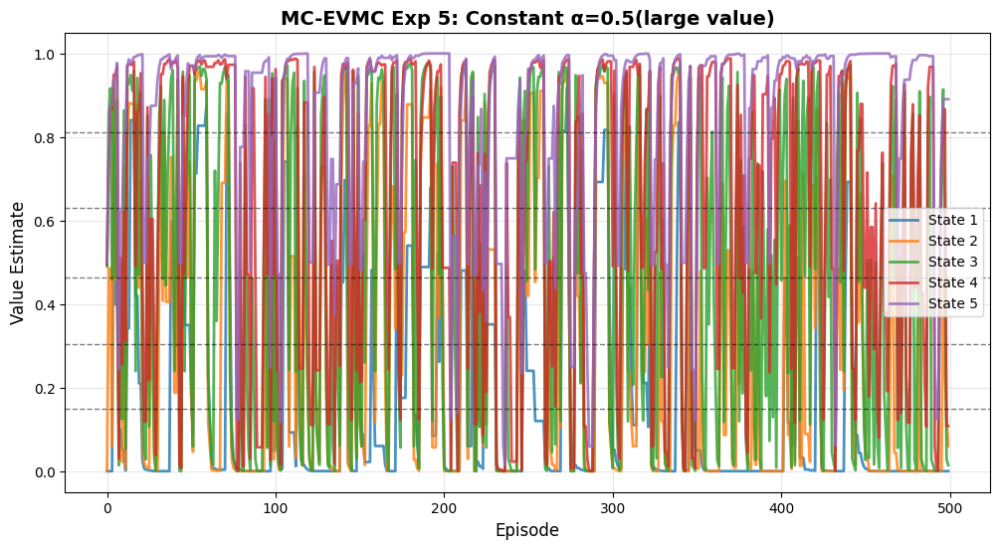

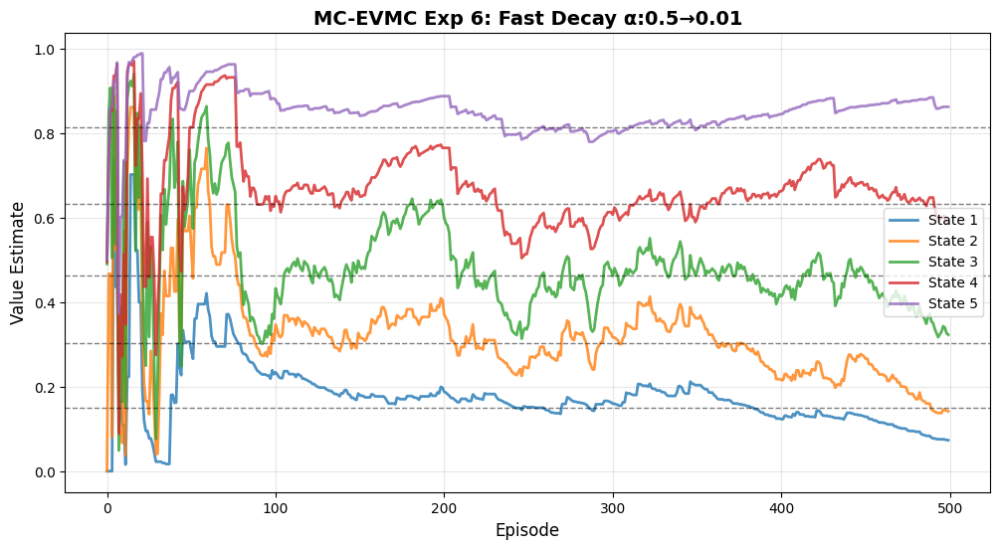

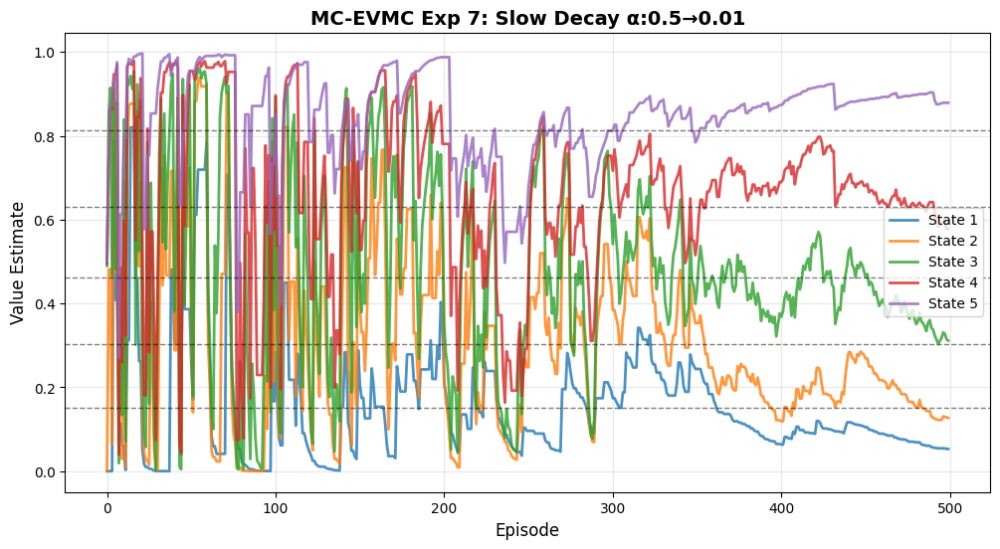

In [48]:
num_episodes = 500

np.random.seed(SEED)
env = RandomWalkEnv()
history_mc_evmc_exp1 = monte_carlo_prediction(env, num_episodes, mc_type='EVMC')
plot_value_estimates(history_mc_evmc_exp1, TRUE_VALUES, 'MC-EVMC Exp 1: Linear Decay α:0.5→0.01')

np.random.seed(SEED)
env = RandomWalkEnv()
history_mc_evmc_exp2 = monte_carlo_prediction(env, num_episodes, mc_type='EVMC', decay_type='exponential')
plot_value_estimates(history_mc_evmc_exp2, TRUE_VALUES, 'MC-EVMC Exp 2: Exponential Decay α:0.5→0.01')

np.random.seed(SEED)
env = RandomWalkEnv()
history_mc_evmc_exp3 = monte_carlo_prediction(env, num_episodes, alpha_start=0.01, alpha_end=0.01, decay_period=1, mc_type='EVMC')
plot_value_estimates(history_mc_evmc_exp3, TRUE_VALUES, 'MC-EVMC Exp 3: Constant α=0.01(small value)')

np.random.seed(SEED)
env = RandomWalkEnv()
history_mc_evmc_exp4 = monte_carlo_prediction(env, num_episodes, alpha_start=0.1, alpha_end=0.1, decay_period=1, mc_type='EVMC')
plot_value_estimates(history_mc_evmc_exp4, TRUE_VALUES, 'MC-EVMC Exp 4: Constant α=0.1(moderate value)')

np.random.seed(SEED)
env = RandomWalkEnv()
history_mc_evmc_exp5 = monte_carlo_prediction(env, num_episodes, alpha_start=0.5, alpha_end=0.5, decay_period=1, mc_type='EVMC')
plot_value_estimates(history_mc_evmc_exp5, TRUE_VALUES, 'MC-EVMC Exp 5: Constant α=0.5(large value)')

np.random.seed(SEED)
env = RandomWalkEnv()
history_mc_evmc_exp6 = monte_carlo_prediction(env, num_episodes, decay_period=100, mc_type='EVMC', decay_type='exponential')
plot_value_estimates(history_mc_evmc_exp6, TRUE_VALUES, 'MC-EVMC Exp 6: Fast Decay α:0.5→0.01')

np.random.seed(SEED)
env = RandomWalkEnv()
history_mc_evmc_exp7 = monte_carlo_prediction(env, num_episodes, decay_period=500, mc_type='EVMC', decay_type='exponential')
plot_value_estimates(history_mc_evmc_exp7, TRUE_VALUES, 'MC-EVMC Exp 7: Slow Decay α:0.5→0.01')

**Observations (MC-EVMC):**

## Experiment 1 (MC-EVMC): Linear Decay α:0.5→0.01

**Setup:** 500 episodes with learning rate linearly decaying from 0.5 to 0.01. Horizontal dashed lines represent true state values.

**Observations:**
- Extreme volatility persists, higher than FVMC
- States don't converge to the true values. 

**Takeaway:** Although linear decay reduces variance over time, EVMC still exhibits misalignment for index states, indicating insufficient correction before α becomes small.

## Experiment 2 (MC-EVMC): Exponential Decay α:0.5→0.01

**Setup:** 500 episodes with learning rate exponentially decaying from 0.5 to 0.01.

**Observations:**
- Very high volatility persists well beyond 200 episodes despite exponential decay
- None of the states cleanly converge to their corresponding true values


**Takeaway:** Although exponential decay reduces the learning rate faster, EVMC still exhibits high variance(although lower than Linear due to faster decay of α) and misaligned convergence across states.

---

## Experiment 3 (MC-EVMC): Constant α = 0.01 (small value)

**Setup:** 500 episodes with constant learning rate α = 0.01 throughout.

**Observations:**
- Smooth and stable learning with low variance across all states
- Value estimates rise gradually from episode 0 without large oscillations
- Several states converge to incorrect levels
- Lower-index states (State 1 and 2) remain noticeably biased even at episode 500


---

## Experiment 4 (MC-EVMC): Constant α = 0.1 (moderate value)

**Setup:** 500 episodes with constant learning rate α = 0.1 throughout.

**Observations:**
- Persistent extreme volatility across all 500 episodes with no stabilization
- Value estimates repeatedly jump between near-0 and near-1 for multiple states
- No state remains near its true value for sustained periods
- Later episodes look as noisy as early episodes, indicating no convergence trend

**Takeaway:** With constant α = 0.1, EVMC updates remain too aggressive, causing estimates to oscillate, preventing meaningful learning.

---

## Experiment 5 (MC-EVMC): Constant α = 0.5 (large value)

**Setup:** 500 episodes with constant learning rate α = 0.5 throughout. Horizontal dashed lines represent true state values.

**Observations:**
- Extreme instability throughout all 500 episodes with no sign of convergence
- Value estimates for most states repeatedly flip between near-0 and near-1
- Curves are dominated by sharp spikes and collapses, showing near-complete overwriting of estimates
- No state stays near its true value for any sustained interval

**Takeaway:** With α = 0.5, EVMC updates remain too aggressive, causing estimates to oscillate, preventing meaningful learning.

---

## Experiment 6 (MC-EVMC): Fast Decay Rate
**Setup:** 500 episodes with exponentially decaying learning rate from 0.5 to 0.01, with a fast decay period (100 episodes). 

**Observations**
- Faster Decay rate controls chaotic oscillations.
- Value estimates don't converge to true values.

---

## Experiment 7 (MC-EVMC): Slow Decay Rate
**Setup:** 500 episodes with learning rate exponentially decaying from 0.5 to 0.01 over the entire training horizon (decay period = 500).

**Observations**
- Slower Decay rate prolongs chaotic oscillations.
- Value estimates don't converge to true values.

### 7. TD esitmate (20 points)
Plot the **TD** estimate of each non-terminal state of RWE as it progress through different episodes. In the same plot also plot the true estimate. Take maximum of 500 episodes. You can play with different settings of $\alpha$, for example, the step size parameter ($\alpha$) starts from 0.5 and decreases exponentially to 0.01 till 250 episodes and after that it is constant. Or else you can also try with small $(<1)$ value of constant $\alpha$. Analyze the plots for each state and report your observations, findings and possible reasons for the observed behavior.

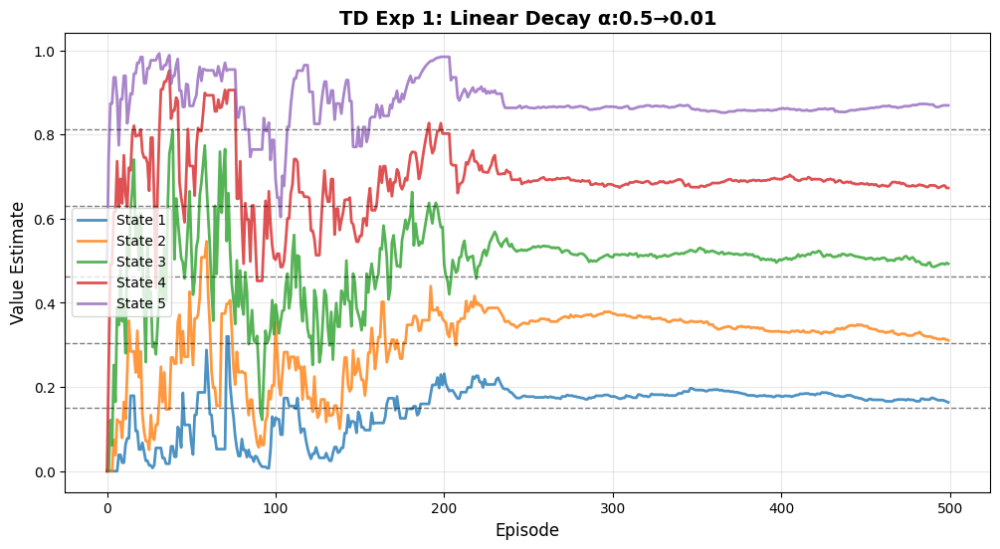

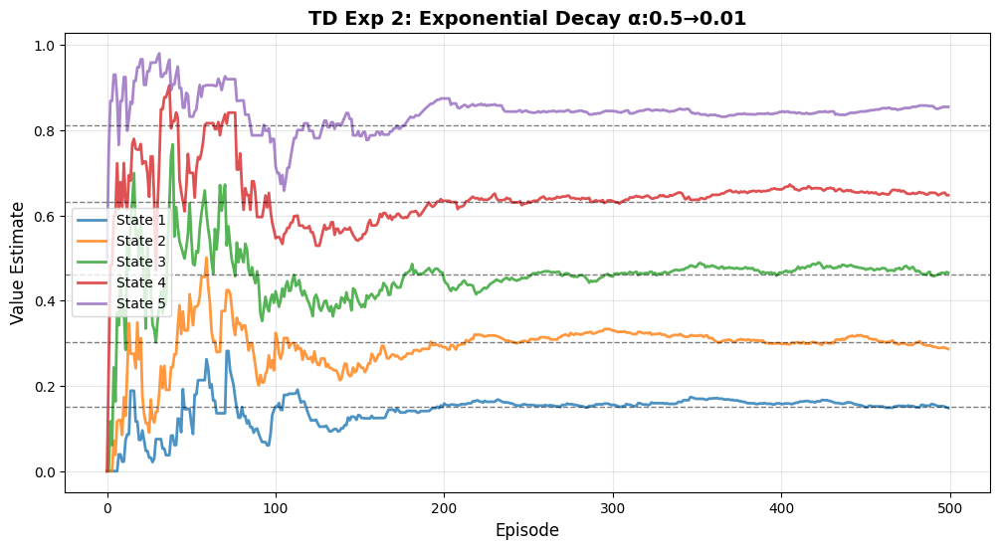

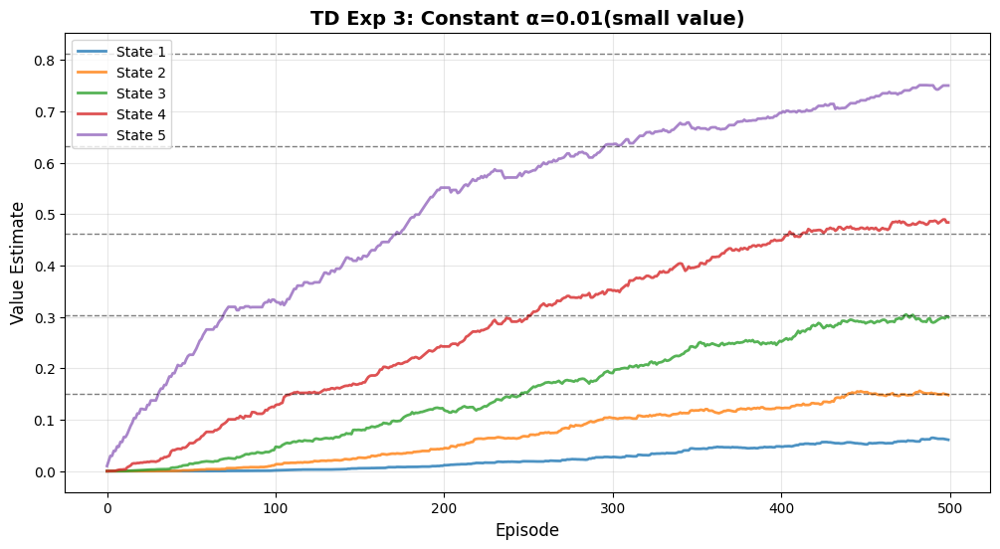

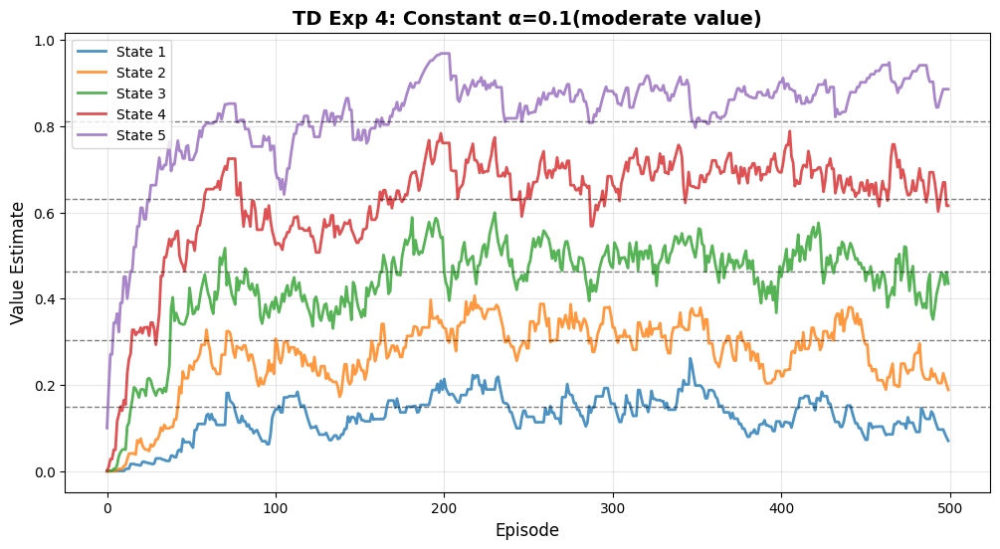

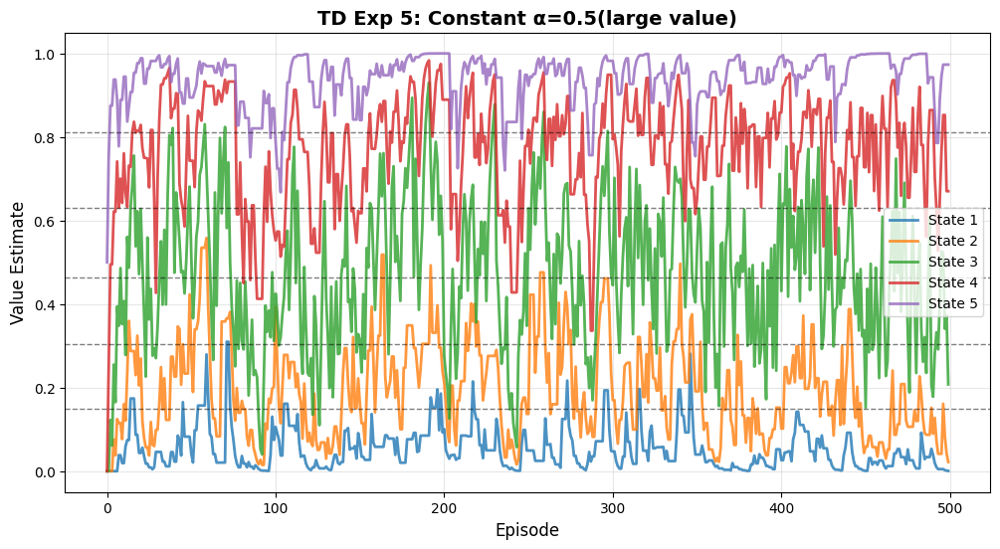

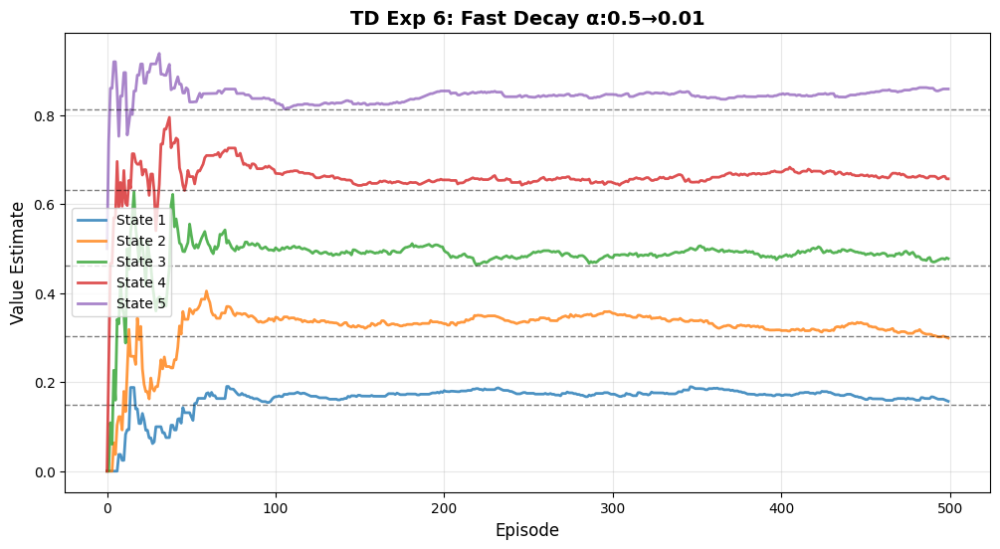

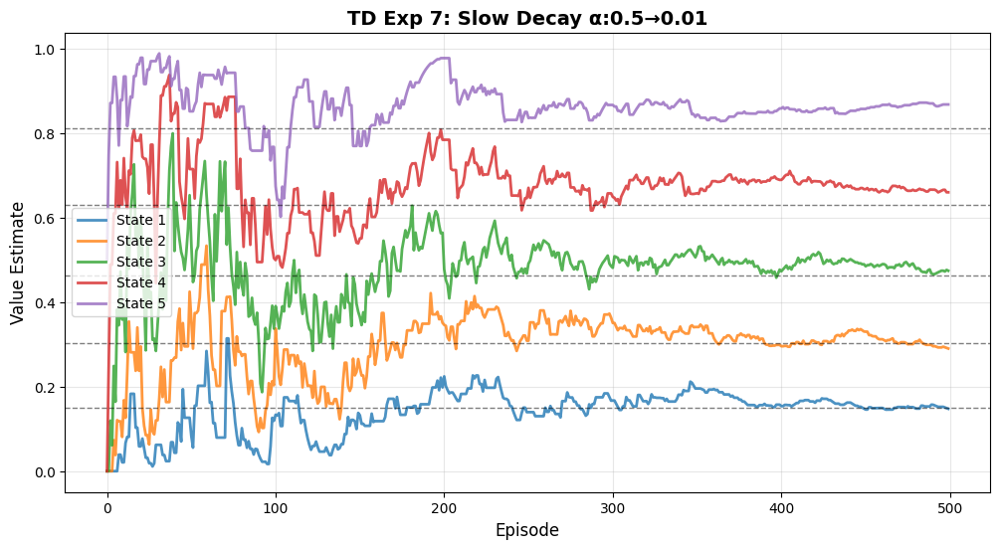

In [49]:
num_episodes = 500

np.random.seed(SEED)
env = RandomWalkEnv()
history_td_exp1 = temporal_difference_prediction(env, num_episodes)
plot_value_estimates(history_td_exp1, TRUE_VALUES, 'TD Exp 1: Linear Decay α:0.5→0.01')

np.random.seed(SEED)
env = RandomWalkEnv()
history_td_exp2 = temporal_difference_prediction(env, num_episodes, decay_type='exponential')
plot_value_estimates(history_td_exp2, TRUE_VALUES, 'TD Exp 2: Exponential Decay α:0.5→0.01')

np.random.seed(SEED)
env = RandomWalkEnv()
history_td_exp3 = temporal_difference_prediction(env, num_episodes, alpha_start=0.01, alpha_end=0.01, decay_period=1)
plot_value_estimates(history_td_exp3, TRUE_VALUES, 'TD Exp 3: Constant α=0.01(small value)')

np.random.seed(SEED)
env = RandomWalkEnv()
history_td_exp4 = temporal_difference_prediction(env, num_episodes, alpha_start=0.1, alpha_end=0.1, decay_period=1)
plot_value_estimates(history_td_exp4, TRUE_VALUES, 'TD Exp 4: Constant α=0.1(moderate value)')

np.random.seed(SEED)
env = RandomWalkEnv()
history_td_exp5 = temporal_difference_prediction(env, num_episodes, alpha_start=0.5, alpha_end=0.5, decay_period=1)
plot_value_estimates(history_td_exp5, TRUE_VALUES, 'TD Exp 5: Constant α=0.5(large value)')

np.random.seed(SEED)
env = RandomWalkEnv()
history_td_exp6 = temporal_difference_prediction(env, num_episodes, decay_period=100, decay_type='exponential')
plot_value_estimates(history_td_exp6, TRUE_VALUES, 'TD Exp 6: Fast Decay α:0.5→0.01')

np.random.seed(SEED)
env = RandomWalkEnv()
history_td_exp7 = temporal_difference_prediction(env, num_episodes, decay_period=500, decay_type='exponential')
plot_value_estimates(history_td_exp7, TRUE_VALUES, 'TD Exp 7: Slow Decay α:0.5→0.01')

**Observations (TD):**

## Experiment 1 (TD): Linear Decay α:0.5→0.01

**Setup:** 500 episodes with learning rate linearly decaying from 0.5 to 0.01. Horizontal dashed lines represent true state values.

**Observations:**
- Early episodes show some variance (0–150), but updates are more controlled than MC due to TD’s lower-variance bootstrapping
- Stabilization begins around ~200 episodes as α becomes smaller
- After stabilization, trajectories are smooth and remain stable with low variance
- Several states settle at biased plateaus (e.g., State 5 and State 4 above their dashed lines; State 2 and State 1 below), showing TD’s bias from bootstrapping

---

## Experiment 2 (TD): Exponential Decay α:0.5→0.01

**Setup:** 500 episodes with learning rate exponentially decaying from 0.5 to 0.01.

**Observations:**
- Early episodes show some variance (0–150), stabilization happens earlier than linear decay due to faster α reduction
- After ~150 episodes, trajectories become very smooth and remain stable (low-variance bootstrapped updates)
- Several states settle at biased plateaus State 5 and State 4 remain above their true values, however, it is important to note that the bias is significantly less than the Experiment 1.


---

## Experiment 3 (TD): Constant α = 0.01 (small value)

**Setup:** 500 episodes with constant learning rate α = 0.01 throughout.

**Observations:**
- Very smooth learning curves with extremely low variance across all states (stable bootstrapped updates)
- None of the states reach their corresponding true values within 500 episodes; all remain significantly below the dashed lines
- Values increase monotonically/gradually, indicating slow propagation of value information
- The gap from true values is largest for lower-index states (State 1 and State 2), showing slow learning under high bias + small α

---

## Experiment 4 (TD): Constant α = 0.1 (moderate value)

**Setup:** 500 episodes with constant learning rate α = 0.1 throughout.

**Observations:**
- Rapid initial learning followed by high variance (higher variance than α=0.01 due to larger step size)
- None of the states settle on the true values.
- State 5 remains consistently above its true value, while State 1 and State 2 remain below their true values
- Variance remains present throughout training since α does not decay, preventing any stabilization
---

## Experiment 5 (TD): Constant α = 0.5 (large value)

**Setup:** 500 episodes with constant learning rate α = 0.5 throughout.

**Observations:**
- Extremely high variance throughout training in all state estimates
- No stabilization is observed, trajectories keep fluctuating even in late episodes
- Estimates frequently overshoot and undershoot the true values due to overly aggressive bootstrapped updates

---

## Experiment 6 (TD): Fast Decay α:0.5→0.01

**Setup:** 500 episodes with exponentially decaying learning rate from 0.5 to 0.01, with a fast decay period (100 episodes). Horizontal dashed lines represent true state values.

**Observations:**
- Stabilizes very early (~60–100 episodes) with low-variance, nearly flat trajectories afterward
- Estimates lock into biased plateaus: State 5 and State 4 remain above true values, while State 2 and State 1 remain below
- Higher Bias at cost of early stabilization

---

## Experiment 7 (TD): Slow Decay α:0.5→0.01

**Setup:** 500 episodes with learning rate exponentially decaying from 0.5 to 0.01 over the entire training horizon (decay period = 500). Horizontal dashed lines represent true state values.

**Observations:**
- High variance persists longer (roughly 0–200 episodes) since α stays large for more time
- After ~250 episodes, trajectories become smoother and more stable while still allowing gradual corrections
- Bias reduces compared to fast decay: mid-states move closer to their dashed lines, but State 5 remains above and State 1 remains below true values. Lower Bias due to increased learning. 







### 8. Smoothing variation (20 points)
As you might notice, the above plots may have lot of variance and look very noisy. One way to overcome this is to create several different instances of the environment using different seeds and then average out the results across these and plot these (this is similar to the Bandit setting). Plot MC-FVMC, MC-EVMC and TD with this averaged out version. This will give you smoother plots. The plot will be similar to shown in lecture 7. Record your seeds and report these along with the plots.

Averaging complete over 50 runs.
Sample Seeds (TD): [101, 102, 103, 104, 105]


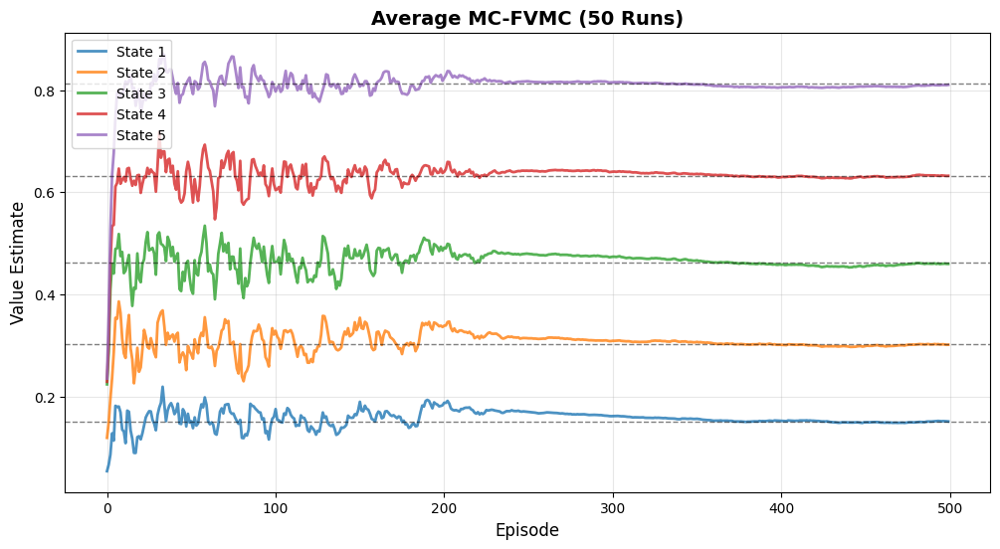

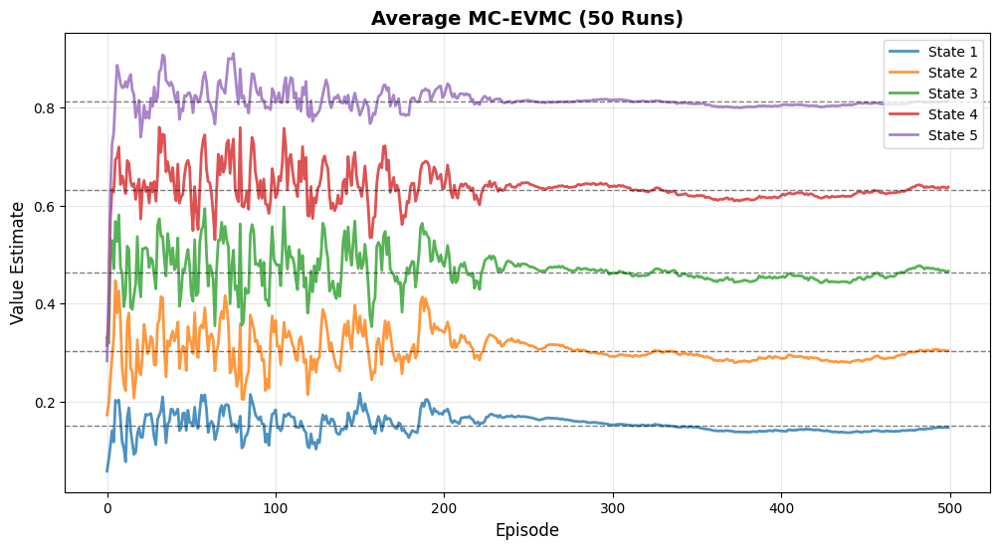

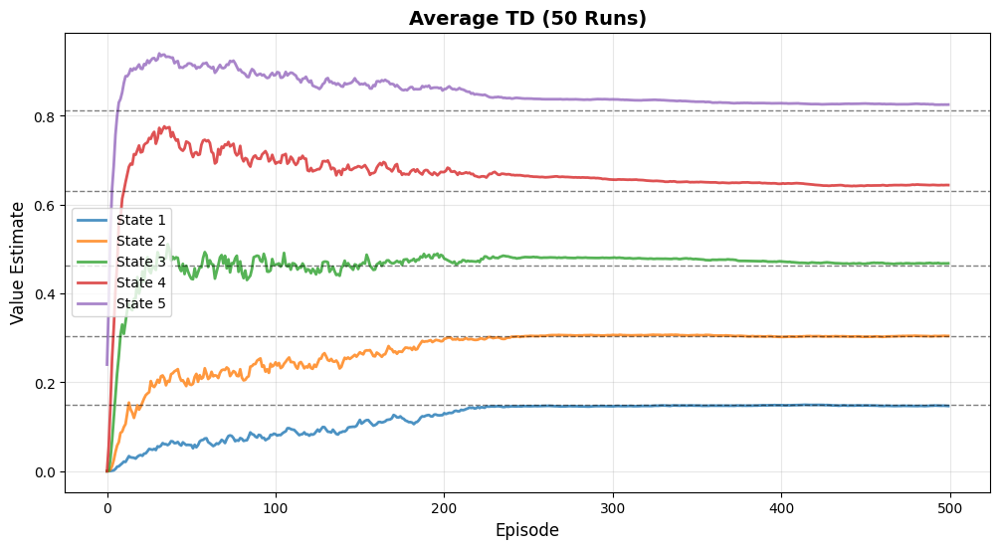

In [50]:
# TODO: Average value estimates over multiple runs
# Methods: MC-FVMC, MC-EVMC, TD

num_runs = 50
num_episodes = 500


def run_averaged_experiment(agent_func, env, num_runs=50, num_episodes=500, **kwargs):
    """
    Runs an RL agent/algorithm multiple times on a given environment to compute
    averaged value estimates. Each run uses a different random seed for reproducibility.

    Args:
        agent_func (callable): The agent function to execute (e.g., monte_carlo_prediction,
                               temporal_difference_prediction).
                               Expected signature: func(env, num_episodes, **kwargs) -> V
        env (gym.Env): The environment instance to run the experiment on.
        num_runs (int, optional): Number of independent runs to perform. Defaults to 50.
        num_episodes (int, optional): Number of episodes per run. Defaults to 500.
        **kwargs: Arbitrary keyword arguments passed directly to the agent_func
                  (e.g., mc_type='FVMC', alpha=0.1, gamma=0.99).

    Returns:
        avg_estimates (np.ndarray): The estimated value function averaged over `num_runs`.
                                    Shape should correspond to the number of non-terminal states.
        seeds (list of int): A list of the random seeds used for each run.
    """
    n_states = len(env.observation_space)
    all_histories = np.zeros((num_runs, num_episodes, n_states))
    seeds = []
    
    for run in range(num_runs):
        seed = SEED + run 
        seeds.append(seed)
        np.random.seed(seed)
        V_history = agent_func(env, num_episodes, **kwargs)
        all_histories[run] = V_history  
        
    avg_estimates = np.mean(all_histories, axis=0)
    return avg_estimates, seeds



# Run Averaged Experiments
avg_fvmc, seeds_fvmc = run_averaged_experiment(monte_carlo_prediction, env, mc_type='FVMC')
avg_evmc, seeds_evmc = run_averaged_experiment(monte_carlo_prediction, env, mc_type='EVMC')
avg_td, seeds_td = run_averaged_experiment(temporal_difference_prediction, env)

print("Averaging complete over 50 runs.")
print("Sample Seeds (TD):", seeds_td[:5])



plot_value_estimates(avg_fvmc, TRUE_VALUES, 'Average MC-FVMC (50 Runs)')
plot_value_estimates(avg_evmc, TRUE_VALUES, 'Average MC-EVMC (50 Runs)')
plot_value_estimates(avg_td, TRUE_VALUES, 'Average TD (50 Runs)')



**Observations:**
**Seeds Used:** For run `r ∈ {0,...,49}`, seed = `SEED + r` → `{SEED, SEED+1, ..., SEED+49}`.

## Averaged Runs: MC-FVMC (50 Runs)

**Setup:** 50 independent runs, each of 500 episodes. At every episode, value estimates are averaged across runs. 

**Observations:**
- The averaged curves are significantly smoother than single-run plots; early MC noise is largely cancelled out by averaging.
- All states quickly move into the correct ordering and remain well separated (State 5 > 4 > 3 > 2 > 1).
- By ~200 episodes, each state forms a stable plateau close to its true value with only small residual fluctuations.


## Averaged Runs: MC-EVMC (50 Runs)

**Setup:** 50 independent runs, each of 500 episodes. At every episode, value estimates are averaged across runs. 

**Observations:**
- Averaging strongly smoothens EVMC trajectories; early oscillations are visible but far less chaotic than single-run plots.
- All states preserve the correct ordering (State 5 > 4 > 3 > 2 > 1) and settle into stable bands by ~200 episodes.
- Final plateaus lie close to true values; residual bias is small.

## Averaged Runs: TD (50 Runs)

**Setup:** 50 independent runs, each of 500 episodes. At every episode, TD value estimates are averaged across runs.

**Observations:**
- Curves become very smooth quickly (low variance); most of the learning happens in the first ~50–150 episodes.
- Estimates stabilize early but settle with noticeable bias: State 4 and State 5 stay consistently above their dashed true values, while State 1/2 remain slightly below.
- After ~200 episodes, trajectories are almost flat (minimal variance).


### 9. FVMC estimate in log-scale (20 points)
Plot the **MC-FVMC** estimate of each non-terminal state of RWE as it progress through different episodes. But this time, the **x-axis (episodes) should be log-scale**. In the same plot also plot the true estimate. The plot will be similar to shown in lecture 7. Take maximum of 500 episodes. You can play with different settings of $\alpha$, for example, the step size parameter ($\alpha$) starts from 0.5 and decreases exponentially to 0.01 till 250 episodes and after that it is constant. Or else you can also try with small $(<1)$ value of constant $\alpha$. This plot will help to zoom in and observe the behavior of the estimates in the initial stages. Analyze the plots for each state and report your observations, findings and possible reasons for the observed behavior.

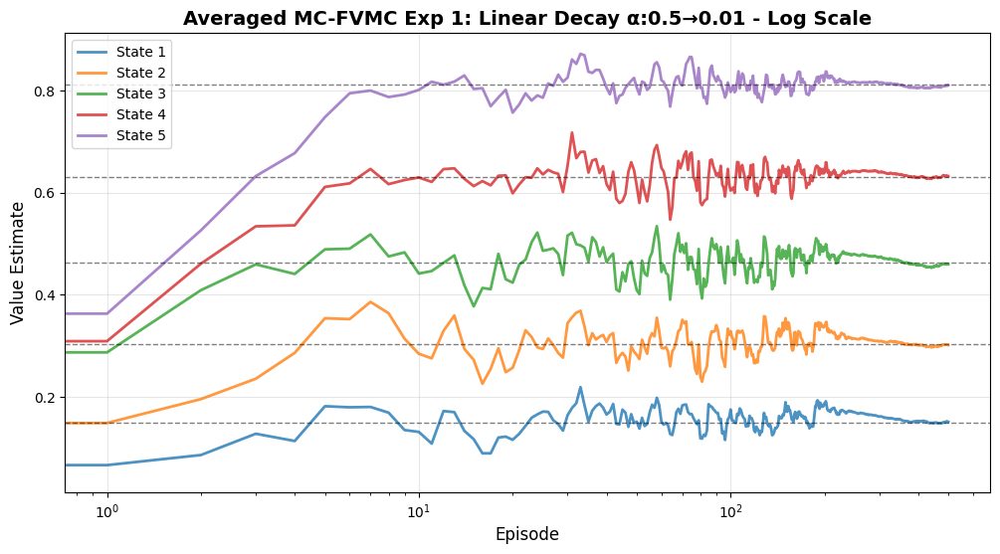

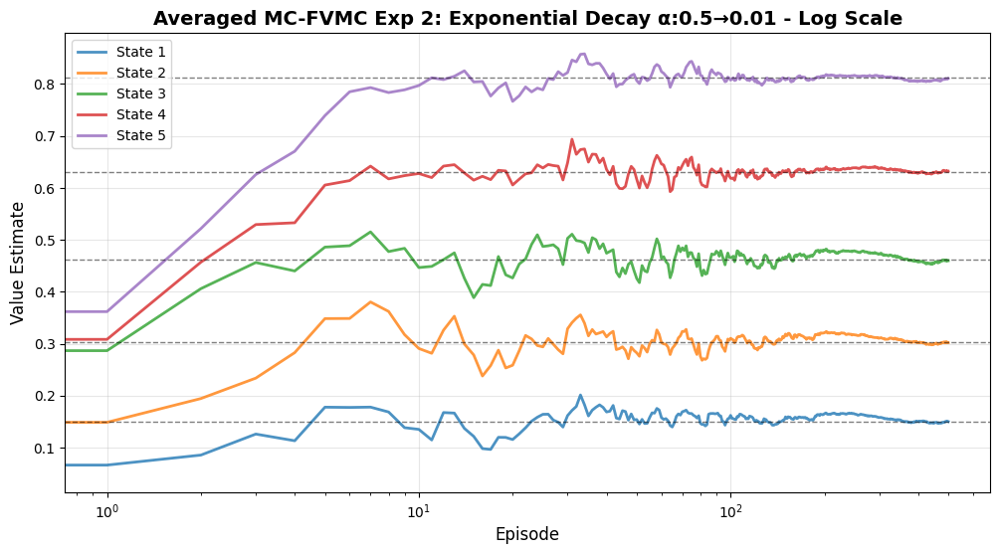

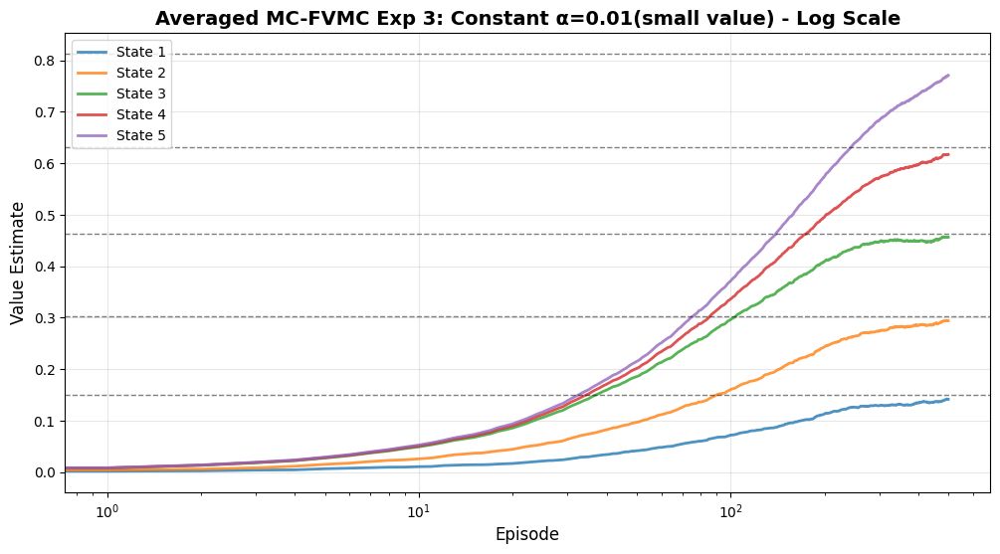

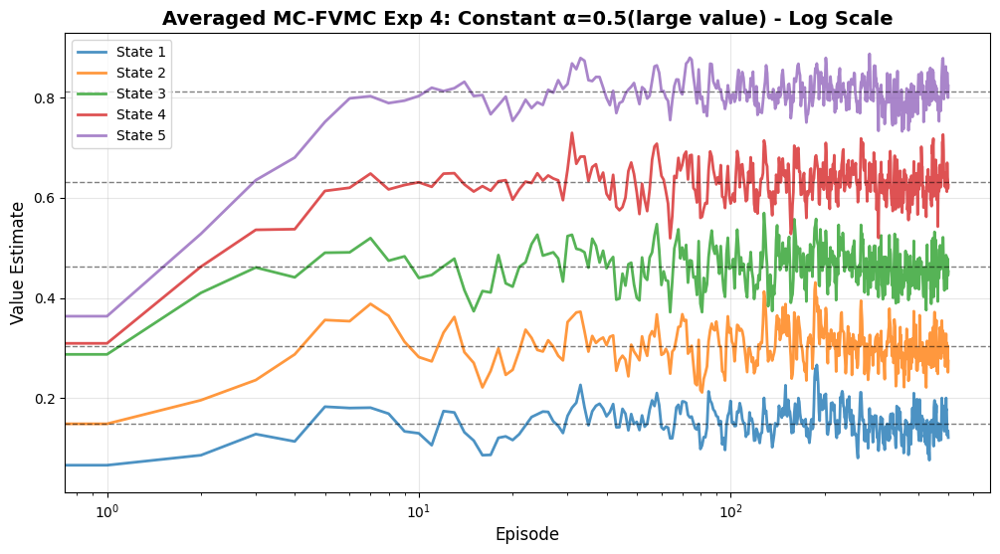

In [51]:
num_episodes = 500

np.random.seed(SEED)
env = RandomWalkEnv()
avg_fvmc_exp1, seeds_fvmc = run_averaged_experiment(monte_carlo_prediction, env, mc_type='FVMC')
plot_value_estimates(avg_fvmc_exp1, TRUE_VALUES, 'Averaged MC-FVMC Exp 1: Linear Decay α:0.5→0.01 - Log Scale', x_log_scale=True)

np.random.seed(SEED)
env = RandomWalkEnv()
avg_fvmc_exp2, seeds_fvmc = run_averaged_experiment(monte_carlo_prediction, env, mc_type='FVMC', decay_type='exponential')
plot_value_estimates(avg_fvmc_exp2, TRUE_VALUES, 'Averaged MC-FVMC Exp 2: Exponential Decay α:0.5→0.01 - Log Scale', x_log_scale=True)

np.random.seed(SEED)
env = RandomWalkEnv()
avg_fvmc_exp3, seeds_fvmc = run_averaged_experiment(monte_carlo_prediction, env, mc_type='FVMC',alpha_start=0.01, alpha_end=0.01, decay_period=1)
plot_value_estimates(avg_fvmc_exp3, TRUE_VALUES, 'Averaged MC-FVMC Exp 3: Constant α=0.01(small value) - Log Scale', x_log_scale=True)

np.random.seed(SEED)
env = RandomWalkEnv()
avg_fvmc_exp4, seeds_fvmc = run_averaged_experiment(monte_carlo_prediction, env, mc_type='FVMC',alpha_start=0.5, alpha_end=0.5, decay_period=1)
plot_value_estimates(avg_fvmc_exp4, TRUE_VALUES, 'Averaged MC-FVMC Exp 4: Constant α=0.5(large value) - Log Scale', x_log_scale=True)



                                      

**Observations:**

### Averaged MC-FVMC Exp 1: Linear Decay α: 0.5 → 0.01 (Log x-scale)

**Setup:** 50-run averaged MC-FVMC over 500 episodes, α linearly decays from 0.5 to 0.01, x-axis is log-scaled.

**Observations:**
- Estimates jump quickly toward the steady ranges due to large initial α.
- Mid-training shows small residual oscillations, but the ordering stays stable (S5 > S4 > S3 > S2 > S1).
- Later episodes flatten out, converging towards the true values.

---

### Averaged MC-FVMC Exp 2: Exponential Decay α: 0.5 → 0.01 (Log x-scale)

**Setup:** 50-run averaged MC-FVMC over 500 episodes, α decays exponentially from 0.5 to 0.01, x-axis is log-scaled.

**Observations:**
- All states rise quickly in the first few (log-scaled) episodes due to high initial α.
- After the initial steps, updates become conservative (α drops fast), so curves stabilize earlier and show smaller late-stage movement.
- Ordering remains consistent throughout (S5 > S4 > S3 > S2 > S1), with mild mid-episode variance before convergence.

---
### Averaged MC-FVMC Exp 3: Constant α = 0.01 (small value) (Log x-scale)

**Setup:** 50-run averaged MC-FVMC over 500 episodes, constant step-size α=0.01, x-axis is log-scaled.

**Observations:**
- All state estimates increase gradually (small α → small updates per episode).
- Curves are extremely smooth/low-variance after averaging, but they still haven’t fully flattened by 500 episodes (still drifting upward).

---

### Averaged MC-FVMC Exp 4: Constant α = 0.5 (large value) (Log x-scale)
**Setup:** 50-run averaged MC-FVMC over 500 episodes, constant step-size α=0.5, x-axis is log-scaled.

**Observations:**
- Estimates jump quickly in the first few (log-scale) episodes because α is large (aggressive updates).
- Even after averaging 50 runs, the curves remain visibly noisy, large α keeps injecting high variance in the updates.
- Estimates hover around a steady level but keep fluctuating rather than smoothly flattening.





### 10. EVMC estimate in log-scale (20 points)

Plot the **MC-EVMC** estimate of each non-terminal state of RWE as it progress through different episodes. But this time, the **x-axis (episodes) should be log-scale**. In the same plot also plot the true estimate. Take maximum of 500 episodes. You can play with different settings of $\alpha$. This plot will help to zoom in and observe the behavior of the estimates in the initial stages. Analyze the plots for each state and report your observations, findings and possible reasons for the observed behavior. How does EVMC fair against FVMC?

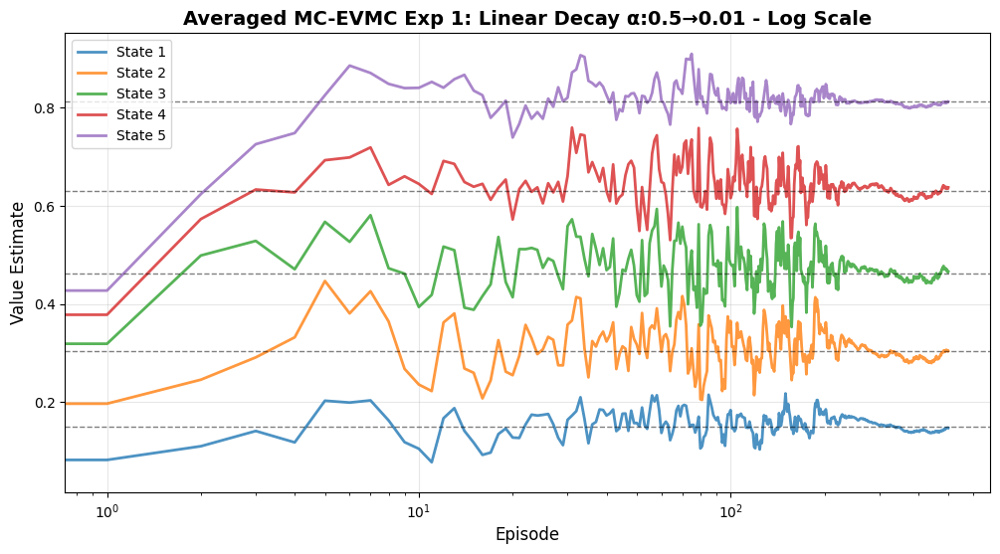

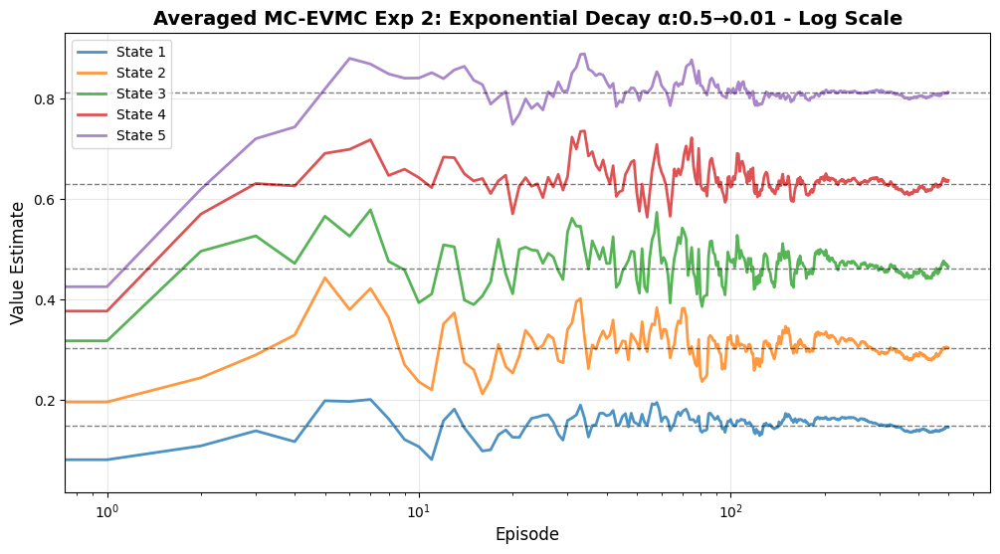

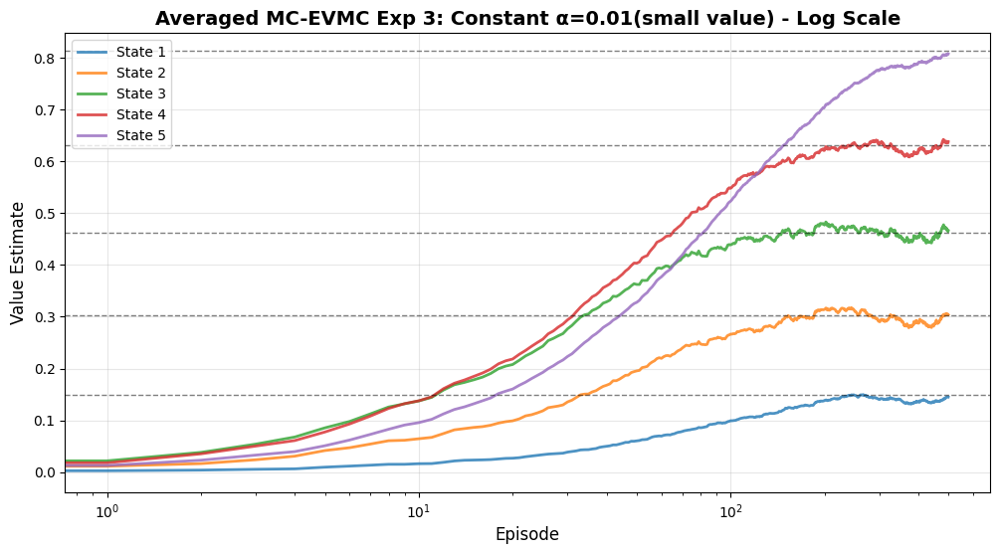

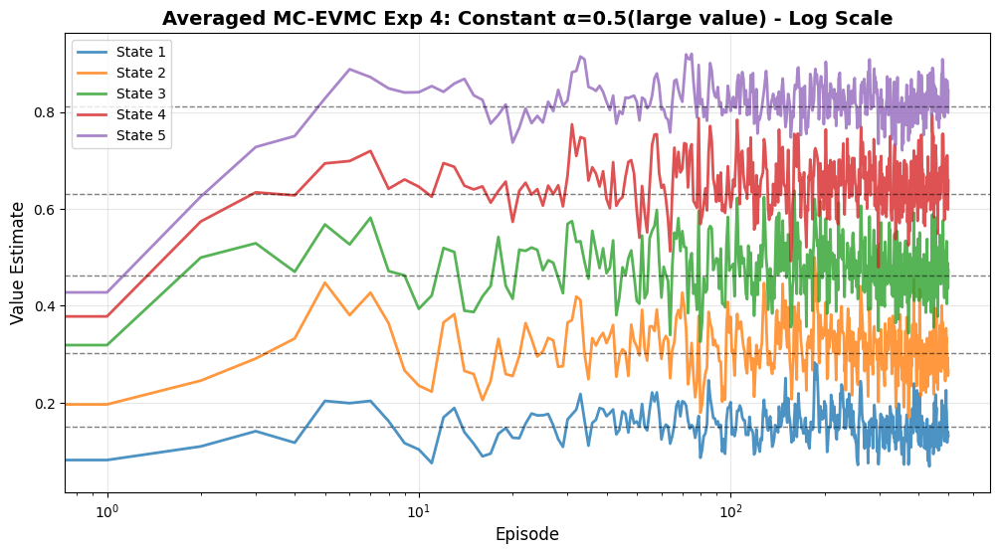

In [52]:
num_episodes = 500

np.random.seed(SEED)
env = RandomWalkEnv()
avg_evmc_exp1, seeds_evmc = run_averaged_experiment(monte_carlo_prediction, env, mc_type='EVMC')
plot_value_estimates(avg_evmc_exp1, TRUE_VALUES, 'Averaged MC-EVMC Exp 1: Linear Decay α:0.5→0.01 - Log Scale', x_log_scale=True)

np.random.seed(SEED)
env = RandomWalkEnv()
avg_evmc_exp2, seeds_evmc = run_averaged_experiment(monte_carlo_prediction, env, mc_type='EVMC', decay_type='exponential')
plot_value_estimates(avg_evmc_exp2, TRUE_VALUES, 'Averaged MC-EVMC Exp 2: Exponential Decay α:0.5→0.01 - Log Scale', x_log_scale=True)

np.random.seed(SEED)
env = RandomWalkEnv()
avg_evmc_exp3, seeds_evmc = run_averaged_experiment(monte_carlo_prediction, env, mc_type='EVMC', alpha_start=0.01, alpha_end=0.01, 
                                                    decay_period=1)
plot_value_estimates(avg_evmc_exp3, TRUE_VALUES, 'Averaged MC-EVMC Exp 3: Constant α=0.01(small value) - Log Scale', x_log_scale=True)

np.random.seed(SEED)
env = RandomWalkEnv()
avg_evmc_exp4, seeds_evmc = run_averaged_experiment(monte_carlo_prediction, env, mc_type='EVMC', alpha_start=0.5, alpha_end=0.5, 
                                                    decay_period=1)
plot_value_estimates(avg_evmc_exp4, TRUE_VALUES, 'Averaged MC-EVMC Exp 4: Constant α=0.5(large value) - Log Scale', x_log_scale=True)






**Observations:**

### Averaged MC-EVMC Exp 1: Linear Decay α: 0.5 → 0.01 (Log x-scale)

**Setup:** 50-run averaged MC-EVMC over 500 episodes, step-size α decays linearly from 0.5 to 0.01, x-axis is log-scaled.

**Observations:**
- With large initial α, all states climb quickly in the first few (log-scale) episodes.
- Oscillations are noticeable in the mid-episodes but become tighter later as the step-size decays.
- After α is decayed , updates become small and the value estimates converge.

---

### Averaged MC-EVMC Exp 2: Exponential Decay α: 0.5 → 0.01 (Log x-scale)

**Setup:** 50-run averaged MC-EVMC over 500 episodes, step-size α decays exponentially from 0.5 to 0.01, x-axis is log-scaled.

**Observations:**
- With large initial α, all states climb quickly in the first few (log-scale) episodes.
- Fluctuations shrink sooner as α drops faster initially, so the curves stabilize earlier on the log axis.

---

### Averaged MC-EVMC Exp 3: Constant α = 0.01 (small value) (Log x-scale)

**Setup:** 50-run averaged MC-EVMC over 500 episodes, constant step-size α = 0.01, x-axis is log-scaled.

**Observations:**
- Very slow learning, estimates rise gradually over many episodes (small α → small updates per episode).
- Curves are extremely smooth/low-variance after averaging, and appear to have converged to true values(although still drifting upward).

---

### Averaged MC-EVMC Exp 4: Constant α = 0.5 (large value) (Log x-scale)
**Setup:** 50-run averaged MC-EVMC over 500 episodes, constant step-size α=0.5, x-axis is log-scaled.

**Observations:**
- Estimates jump quickly in the first few (log-scale) episodes because α is large (aggressive updates).
- Even after averaging 50 runs, the curves remain visibly noisy, large α keeps injecting high variance in the updates.
- Estimates hover around a steady level but keep fluctuating rather than smoothly flattening. (Variance higher than FVMC)



### 11. TD estimate of non-terminal states (10 points)

Plot the **TD** estimate of each non-terminal state of RWE as it progress through different episodes. But this time, the **x-axis (episodes) should be log-scale**. In the same plot also plot the true estimate. The plot will be similar to shown in lecture 7. Take maximum of 500 episodes. You can play with different settings of $\alpha$. This plot will help to zoom in and observe the behavior of the estimates in the initial stages. Analyze the plots for each state and report your observations, findings and possible reasons for the observed behavior.

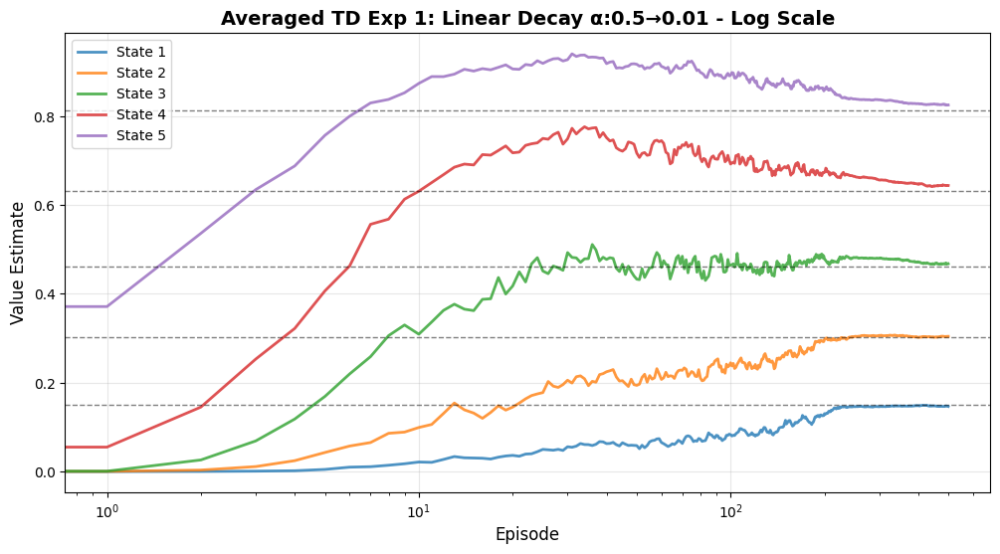

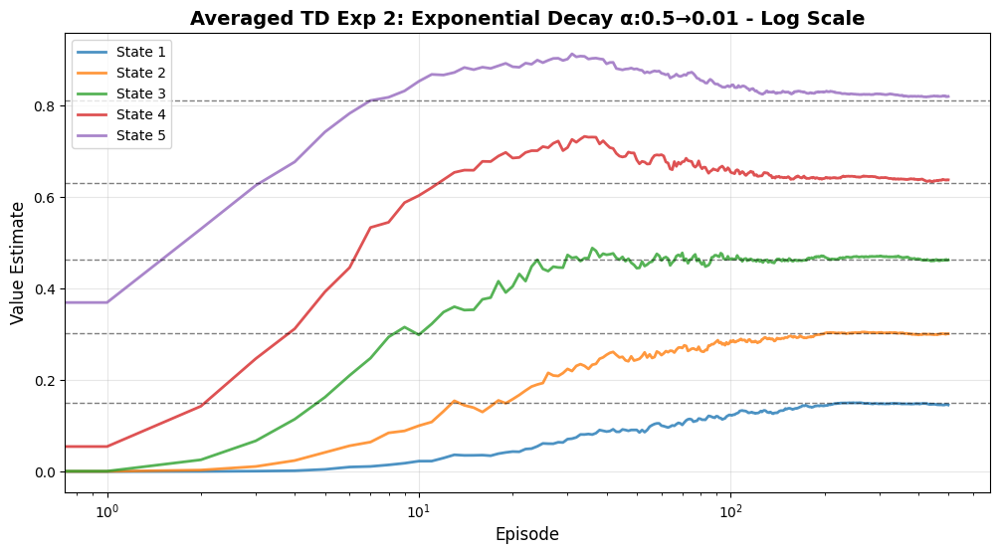

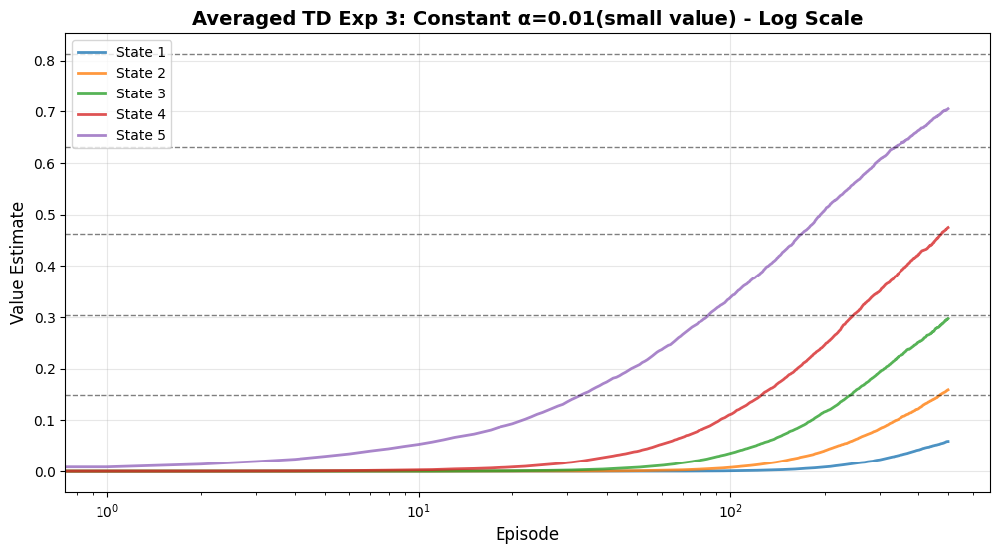

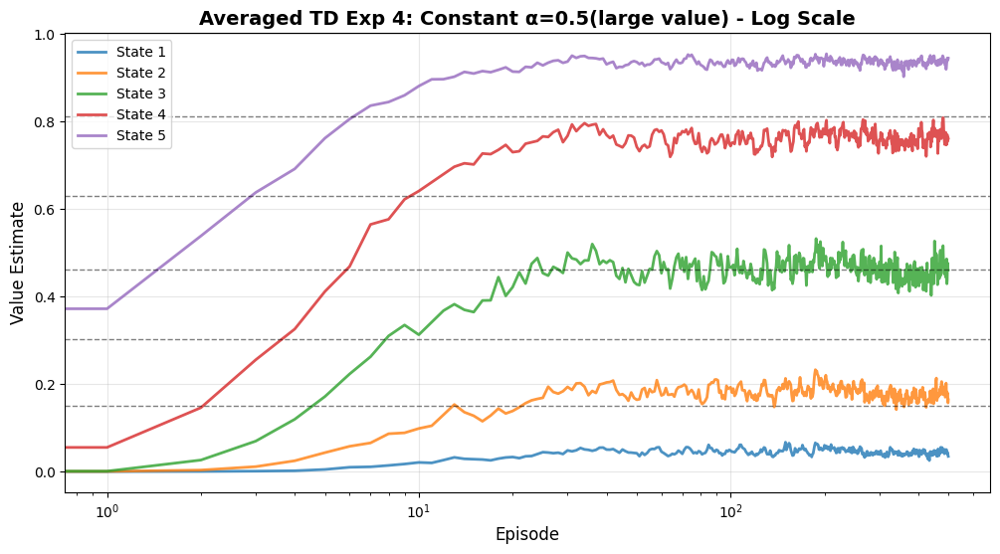

In [53]:
num_episodes = 500

np.random.seed(SEED)
env = RandomWalkEnv()
avg_td_exp1, seeds_td = run_averaged_experiment(temporal_difference_prediction, env)
plot_value_estimates(avg_td_exp1, TRUE_VALUES, 'Averaged TD Exp 1: Linear Decay α:0.5→0.01 - Log Scale', x_log_scale=True)

np.random.seed(SEED)
env = RandomWalkEnv()
avg_td_exp2, seeds_td = run_averaged_experiment(temporal_difference_prediction, env, decay_type='exponential')
plot_value_estimates(avg_td_exp2, TRUE_VALUES, 'Averaged TD Exp 2: Exponential Decay α:0.5→0.01 - Log Scale', x_log_scale=True)

np.random.seed(SEED)
env = RandomWalkEnv()
avg_td_exp3, seeds_td = run_averaged_experiment(temporal_difference_prediction, env, alpha_start=0.01, alpha_end=0.01, decay_period=1)
plot_value_estimates(avg_td_exp3, TRUE_VALUES, 'Averaged TD Exp 3: Constant α=0.01(small value) - Log Scale', x_log_scale=True)

np.random.seed(SEED)
env = RandomWalkEnv()
avg_td_exp4, seeds_td = run_averaged_experiment(temporal_difference_prediction, env,alpha_start=0.5, alpha_end=0.5, decay_period=1)
plot_value_estimates(avg_td_exp4, TRUE_VALUES, 'Averaged TD Exp 4: Constant α=0.5(large value) - Log Scale', x_log_scale=True)


**Observations (Log Scale):**

### Averaged TD Exp 1: Linear Decay α: 0.5 → 0.01 (Log x-scale)

**Setup:** 50-run averaged TD over 500 episodes, step-size α decays linearly from 0.5 to 0.01, x-axis is log-scaled.

**Observations:**
- With large initial α, all states move up quickly in the first few (log-scale) episodes (fast bootstrapped updates).
- Mid-episodes show some oscillations/overshoot, but they tighten later as α decays.
- After α becomes small, updates shrink and the value estimates stabilize (curves flatten out).

---

### Averaged TD Exp 2: Exponential Decay α: 0.5 → 0.01 (Log x-scale)  
**Setup:** 50-run averaged TD over 500 episodes, step-size α decays exponentially from 0.5 to 0.01, x-axis is log-scaled.

**Observations:**
- With large initial α, all states climb quickly in the first few (log-scale) episodes (aggressive early bootstrapped updates).  
- As α drops faster initially (exponential), fluctuations shrink earlier, so the curves stabilize sooner on the log axis compared to linear decay.  
- After α becomes small, updates become small and the value estimates mostly flatten, with only minor residual drift in later episodes.  

---

### Averaged TD Exp 3: Constant α = 0.01 (small value) (Log x-scale)  
**Setup:** 50-run averaged TD over 500 episodes, constant step-size α = 0.01, x-axis is log-scaled.

**Observations:**
- Very slow learning, estimates rise gradually over many episodes (small α → small updates per episode). 
- Clear undershooting within 500 episodes: the estimates stay below the true value since TD is not taking large enough steps.

---

### Averaged TD Exp 4: Constant α = 0.5 (large value) (Log x-scale)  
**Setup:** 50-run averaged TD over 500 episodes, constant step-size α = 0.5,  x-axis is log-scaled.

**Observations:**
- Estimates jump quickly in the first few (log-scale) episodes because α is large (aggressive updates).  
- Values show mixed undershooting/overshooting across states, indicating a bias.
- Even after averaging 50 runs, the curves remain visibly noisy, large α keeps injecting high variance in the updates.



### 12. Comparitive analysis (20 points)


### MC-FVMC (First-Visit Monte Carlo)
-  With linear/exponential decay, FVMC rises quickly early (large α) and then stabilizes as α becomes small.
- **Constant small α (=0.01):** Learning remains slow, with value estimates following an upward trend (not converging)
- **Constant large α (=0.5):** Curves remain visibly noisy even after averaging; large α keeps the estimates highly variate instead of converging.

---

### MC-EVMC (Every-Visit Monte Carlo)
- EVMC follows the same general pattern as FVMC under the same α schedule, but the mid-episode region is often more variate which can be attributed to more frequent updates per episode.
- Exponential decay stabilizes earlier on the log axis (α drops faster initially), while linear decay stabilizes a bit later.
- **Constant small α (=0.01):** Learning remains slow, with value estimates following an upward trend (not converging)
- **Constant large α (=0.5):** Curves remain visibly noisy even after averaging; large α keeps the estimates highly variate instead of converging.
  
---

### TD (Temporal Difference)
- TD value estimates reach closer to the true values earlier compared to MC.
- **Constant small α (=0.01):** Curves rise slowly and undershoot for a long time.
- **Constant large α (=0.5):** Values may undershoot or overshoot indicating high bias.
---

### Key takeaway
- **MC (FVMC/EVMC):** tends to be less biased but has high variance unless α decays.
- **TD:** tends to be more biased but has lower variance overall.


[Write your answer here]

### 13. FVMC Return for non-terminal state (20 points)
Plot the **MC-FVMC Target value ($G_{t}$)** for any one non-terminal state of RWE as it progress through different episodes. Use the same setting as above. In the same plot also include the optimal value of the state. The plot will be similar to discussed in lecture 7. What do you observe and what are the reasons for what you observe? Explain and Report.

In [54]:
def collect_mc_targets(env, num_episodes, state_to_track=3, mc_type='FVMC', gamma=0.99):
    """
    Runs episodes and collects the Monte Carlo target values (Returns G_t)
    for a specific state whenever it is visited.

    Args:
        env (RandomWalkEnv): The environment instance.
        num_episodes (int): Total number of episodes to run.
        state_to_track (int): The specific non-terminal state to track (e.g., 3).
        mc_type (str): 'FVMC' (First-Visit) or 'EVMC' (Every-Visit).
                       - FVMC: Collect target only for the first occurrence in an episode.
                       - EVMC: Collect target for every occurrence in an episode.
        gamma (float): Discount factor for calculating returns.

    Returns:
        targets (list of float): A list containing all the collected target values (G_t)
                                 for the tracked state across all episodes.
    """
    targets = []
    for e in range(num_episodes):
        t = generateTrajectory(env, 0, 100)
        G = 0
        first_vis = None
        for i in range(len(t)-1, -1, -1):
            G = t[i][2] + gamma*G
            state = t[i][0]
            if state == state_to_track: 
                if mc_type == 'EVMC':
                    targets.append(G)
                else:
                    first_vis = G
        if mc_type == 'FVMC' and first_vis is not None:
            targets.append(first_vis)
                    
        
    return targets

def plot_target_distribution(targets, true_value, title):
    """
    Plots the target values (G_t) across episodes/occurrences.

    Args:
        targets (list): List of collected target values.
        true_value (float): The optimal/true value of the state (for reference line).
        title (str): Title of the plot.
    """
    occurences = np.arange(len(targets))
    plt.figure(figsize=(12,6))
    plt.plot(occurences, targets)
    plt.axhline(y=true_value, color='gray', linestyle='--', label = "True Value")
    plt.xlabel('Occurences')
    plt.ylabel('Target Values')
    plt.title(title)
    plt.legend()
    plt.savefig(f"{title}.svg", dpi=300, bbox_inches='tight')
    plt.show()

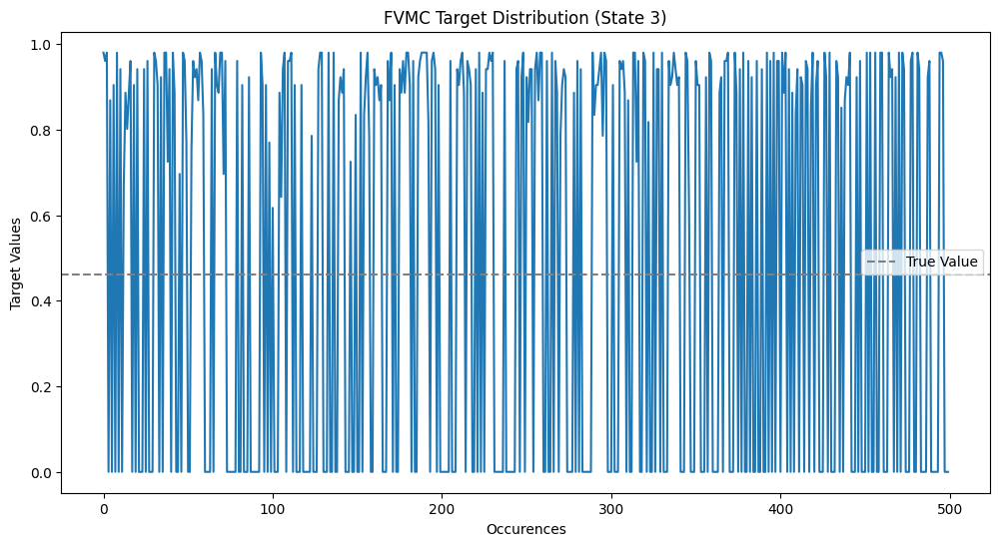

In [55]:

np.random.seed(SEED)
env = RandomWalkEnv()
targets_fvmc = collect_mc_targets(env, num_episodes=500, state_to_track=3, mc_type='FVMC')
plot_target_distribution(targets_fvmc, TRUE_VALUES[3], "FVMC Target Distribution (State 3)")

**Observations:**
- The target values have high variance.

**Why this happens**
- In MC, the target depends on the entire future trajectory after visiting the state, random walk outcomes make returns highly variable.


### 14. EVMC Return for non-terminal state (20 points)

Plot the **MC-EVMC Target value ($G_{t}$)** for any one non-terminal state of RWE (use the same state as above) as it progress through different episodes. Use the same setting as above. In the same plot also include the optimal value of the state. What do you observe and what are the reasons for what you observe? Explain and Report.

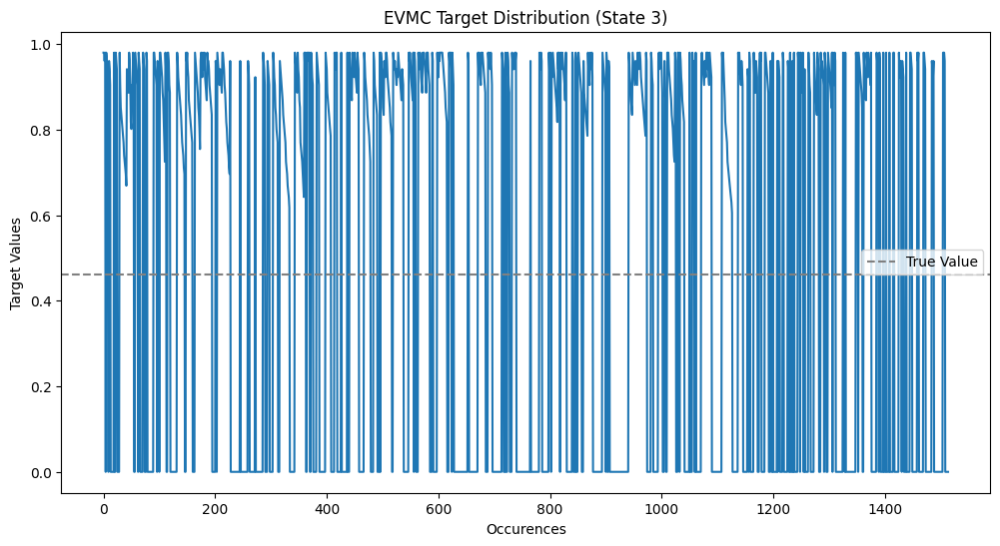

In [56]:
np.random.seed(SEED)
env = RandomWalkEnv()
targets_evmc = collect_mc_targets(env, num_episodes=500, state_to_track=3, mc_type='EVMC')
plot_target_distribution(targets_evmc, TRUE_VALUES[3], "EVMC Target Distribution (State 3)")

**Observations:**

- Return still has high-variance, but compared to FVMC it looks more concentrated near the extremes.

**Why this happens**
- EVMC also uses Monte Carlo returns, so the target depends on the entire future trajectory after visiting the state, random walk outcomes make returns highly variable.
- Since in EVMC every visit is considered, State 3 gets updated many more times leading to concentration near the extremes as compared to FVMC.



### 15. TD Return for non-terminal state (10 points)

Plot the **TD Target value ($G_{t}$ estimate)** for any one non-terminal state of RWE (use the same state as above) as it progress through different episodes. Use the same setting as above. In the same plot also include the optimal value of the state. The plot will be similar to discussed in lecture 7. What do you observe and what are the reasons for what you observe? Explain and Report.

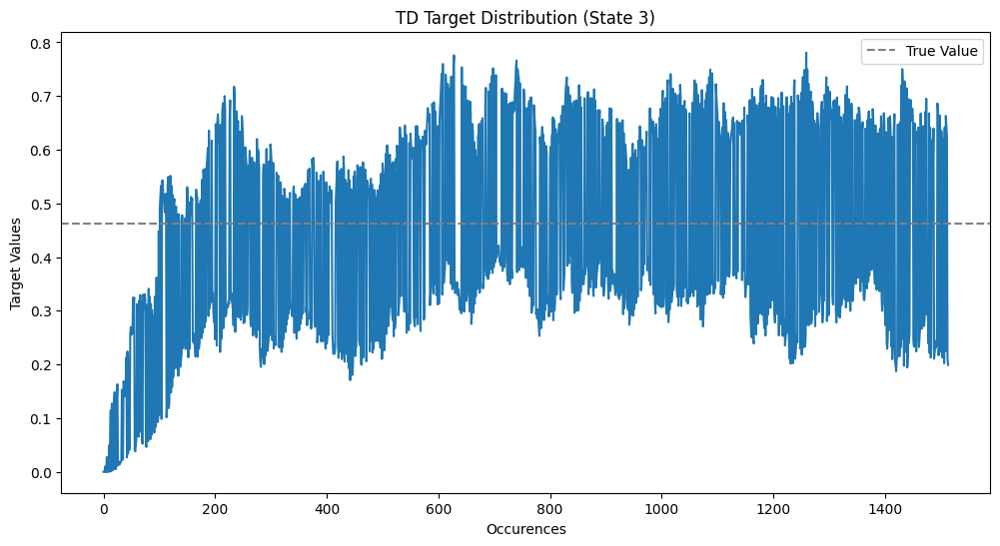

In [57]:
def collect_td_targets(env, num_episodes, state_to_track=3, alpha=0.1, gamma=0.99):
    """
    Runs episodes and collects the TD Target values (R + gamma * V(s'))
    for a specific state to observe how they vary and evolve.

    Args:
        env (RandomWalkEnv): The environment instance.
        num_episodes (int): Total number of episodes to run.
        state_to_track (int): The specific non-terminal state to track (e.g., 3).
        alpha (float): Step size for updating V (needed so the value estimate evolves).
        gamma (float): Discount factor.

    Returns:
        targets (list of float): A list containing all the collected TD target values
                                 for the tracked state across all episodes.
    """
    n_states = len(env.observation_space)
    value = np.zeros(n_states)
    targets = []
    for e in range(num_episodes):
        done = False
        curr_state = env.reset()
        while not done:
            next_state, reward, done, info = env.step(0)
            target = reward
            if not done: 
                target+= gamma*value[next_state]
            error = target - value[curr_state]
            value[curr_state] += alpha*(error)
            if curr_state == state_to_track:
                targets.append(target)
            curr_state = next_state
            
        
    return targets

def plot_target_distribution(targets, true_value, title):
    """
    Plots the specific target values across occurrences to visualize variance.

    Args:
        targets (list): List of target values collected.
        true_value (float): The optimal value for the tracked state.
        title (str): Plot title.
    """
    occurences = np.arange(len(targets))
    plt.figure(figsize=(12,6))
    plt.plot(occurences, targets)
    plt.axhline(y=true_value, color='gray', linestyle='--', label = "True Value")
    plt.xlabel('Occurences')
    plt.ylabel('Target Values')
    plt.title(title)
    plt.legend()
    plt.savefig(f"{title}.svg", dpi=300, bbox_inches='tight')
    plt.show()


np.random.seed(SEED)
env = RandomWalkEnv()
targets_td = collect_td_targets(env, num_episodes=500, state_to_track=3, alpha=0.1)
plot_target_distribution(targets_td, TRUE_VALUES[3], "TD Target Distribution (State 3)")

**Observations:**

- TD targets form a thick band around a mid-range and don’t collapse to extremes.


**Why this happens**
- TD uses a bootstrapped target, so the target is not a full return thus lower variance than MC, but it can introduce bias since we use an estimate. The bias is responsible for the mid-range band.
  


### 16. Target Comparison

Compare First-View, Every-View Monte Carlo and Temporal difference prediction algorithms on their target return values.



### 1) FVMC target
- Target is highly variate unlike TD, due to the full episode return used in MC.
- FVMC uses only the first occurrence in each episode, thus fewer samples, making target less concentrated as compared to EVMC.

### 2) EVMC target
- Target is highly variate unlike TD, due to the full episode return used in MC.
- EVMC uses each occurence in each each episode, thus larger samples, making target more concentrated as compared to FVMC.

### 3) TD target
- Targets form a continuous band, unlike MC methods, due to bootstrapped return used in TD.
- Variance is lower than MC targets because the randomness is mostly from the next transition, not the whole future trajectory.
- TD targets are biased since TD uses an estimate for Value to improve the estimate for Value. 

### Key Takeaway
- **MC (FVMC/EVMC):** target is unbiased but high variance
- **TD:** target has lower variance but is biased


**Citations and LLM use**
- Lecture Notes 6 & 7
- Claude for Ancillary Code Generation(Repeating self-designed testcases for different strategies (2armed to 10armed) (fvmc testcases repeated for TD and EVMC)) and Clarity in case of errors or unexpected performance related to syntactical errors mostly. 